# 7강. 표현 학습과 세그멘테이션: 차원 축소, 오토인코더, VAE, FCN, U-Net, Mask R-CNN, SAM

**대상**: 파이썬과 앞 강의(신경망, CNN, 전이학습)를 아는 입문자 · **분량**: 5교시 · **환경**: Google Colab

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**학습 시간**: 읽고 실습까지 약 6~8시간(추정). 처음부터 끝까지 실행하는 데 Apple Silicon Mac에서 약 20~30분 걸렸고, Colab T4에서는 재 보지 못했습니다.

**필수와 선택**: 2.4절의 변형과 활용, 4.6절(Kaggle 계정 필요)은 선택입니다. 나머지는 필수입니다. 4.6절은 계정이 없으면 저절로 건너뜁니다.

**막혔을 때**: 에러 메시지 전체로 검색하고, 그래도 안 되면 [PyTorch 포럼](https://discuss.pytorch.org/)에 물어보세요. 패키지 설치 직후의 import 오류는 런타임을 다시 시작하면 해결되는 경우가 많습니다.

오늘이 끝나면 다음을 할 수 있습니다.

- 차원의 저주를 실험으로 보여 주고, PCA, t-SNE, UMAP으로 고차원 데이터를 시각화하고 그 그림의 한계를 설명한다.
- 오토인코더와 그 변형(Tied, Denoising, Sparse, Stacked, Convolution)을 구현하고 이상 탐지와 분류에 활용한다.
- VAE의 손실(ELBO)을 유도하고, 수식의 각 항을 코드의 어느 줄과 대응시키는지 설명한다.
- 시맨틱 분할과 인스턴스 분할의 차이를 설명하고, FCN과 U-Net을 직접 구현해 학습하고 Dice로 평가한다.
- Mask R-CNN을 미세 조정하고, SAM과 SAM 2에 점과 박스 프롬프트를 넣어 마스크를 얻는다.

| 교시 | 주제 | 다루는 내용 |
|---|---|---|
| 1교시 | 차원에 대해서 | 차원의 저주, kNN, 매니폴드, PCA, t-SNE, UMAP |
| 2교시 | AutoEncoder | 기본 AE, 잡음 제거, Tied, Sparse, Stacked, 이상 탐지, Convolution AE |
| 3교시 | Variational AutoEncoder | ELBO 유도, 재매개변수화, 구현, 잠재 공간 탐색 |
| 4교시 | FCN과 U-Net | 분할의 개념, 사전학습 FCN, 직접 구현과 학습, 선택 실습(Kaggle 폐 X-ray) |
| 5교시 | Mask R-CNN에서 SAM으로 | RoIAlign, 마스크 브랜치, 미세 조정, 프롬프트 기반 분할, SAM 2 |

>
> **사용법**: 위에서 아래로 순서대로 실행하세요. 메뉴의 `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르면 4, 5교시가 훨씬 빨라집니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **내려받는 데이터**: Fashion-MNIST와 MNIST(수십 MB), Penn-Fudan 보행자(약 54 MB), 사전학습 가중치 FCN(약 135 MB), Mask R-CNN(약 170 MB), SAM ViT-B(약 375 MB), SAM 2.1 Tiny(약 156 MB). 계정은 필요 없습니다.

In [1]:
# 이번 강 전체에서 쓰는 라이브러리
%pip install -q umap-learn torchinfo "transformers>=5" tensorboard

from collections.abc import Callable
import copy
import datetime
import math
import os
import random
import subprocess
import tempfile
import time
import urllib.request
import zipfile
from pathlib import Path

from matplotlib import cm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn import model_selection
from sklearn.datasets import load_breast_cancer, load_digits, load_iris, make_swiss_roll
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.tensorboard import SummaryWriter
import torchvision
import torchvision as tv
from torchvision import datasets, transforms
from torchinfo import summary
from torchvision import tv_tensors
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_Weights, maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from torchvision.transforms import v2
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks
from transformers import Sam2Model, Sam2Processor, SamModel, SamProcessor
from umap import UMAP

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)

DATA_ROOT = "./data"
# 코랩(리눅스)에서는 일꾼 프로세스가 도움이 되고, 맥의 노트북 환경에서는 오히려 시작이 느려진다
NUM_WORKERS = 2 if torch.cuda.is_available() else 0
# 노트북이 너무 무거워지지 않도록 그림 해상도를 조금 낮춘다
plt.rcParams["figure.dpi"] = 70


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다. 1강에서 만든 함수입니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: mps


---
# 1교시. 차원에 대해서

## 1.1 특성(feature)은 많으면 많을수록 좋을까?

너무 적은 것보다는 많은 편이 데이터의 다양한 측면을 담을 수 있으니 좋아 보입니다. 하지만 너무 많으면 어떨까요?

머신러닝에서 만나는 학습 데이터의 특성은 수백 개에서 수만 개에 이르기도 합니다. 이미지만 해도 28×28 흑백이면 784차원이고, 224×224 컬러면 150,528차원입니다. 이렇게 특성이 많으면 훈련이 느려지고 좋은 해를 찾기도 어려워집니다. 이것을 **차원의 저주**(curse of dimensionality)라고 부릅니다.

우리는 4차원 이상을 직관적으로 상상하기 어렵습니다. 그래서 숫자로 확인해 봅시다. 0과 1 사이 균등 분포에서 점 500개를 뽑고, 차원을 늘려 가며 임의의 한 점에서 나머지 점까지의 거리를 잽니다.

(참고 그림: [차원별 공간 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdrGHoh%2FbtqVSu7nT1W%2FOvEULafM3kC7p3gzbfnQ81%2Fimg.png), [차원이 늘 때 거리가 벌어지는 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FboSJYB%2FbtraVTqkwC1%2FSyMcbBfsrOozbaoeKQ4ilK%2Fimg.png). 아래 그래프가 같은 내용을 실제 숫자로 보여 줍니다.)

dim=    2  mean distance=  0.681  relative contrast=  40.730
dim=    3  mean distance=  0.806  relative contrast=  19.704
dim=    5  mean distance=  0.873  relative contrast=   6.004
dim=   10  mean distance=  1.180  relative contrast=   5.678
dim=   30  mean distance=  2.195  relative contrast=   0.831
dim=  100  mean distance=  4.009  relative contrast=   0.407
dim=  300  mean distance=  7.000  relative contrast=   0.182
dim= 1000  mean distance= 12.864  relative contrast=   0.118


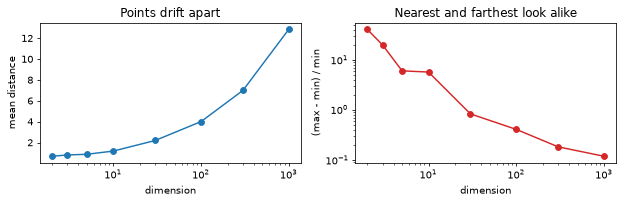

In [2]:
def distance_stats(dim: int, n_points: int = 500) -> tuple[float, float]:
    """균등 분포 점들에서 기준점까지의 평균 거리와 상대 대비((최대-최소)/최소)를 돌려줍니다."""
    rng = np.random.default_rng(0)
    points = rng.uniform(size=(n_points, dim))
    query = rng.uniform(size=dim)
    dist = np.linalg.norm(points - query, axis=1)
    return dist.mean(), (dist.max() - dist.min()) / dist.min()


dims = [2, 3, 5, 10, 30, 100, 300, 1000]
stats = [distance_stats(d) for d in dims]
for d, (mean_dist, contrast) in zip(dims, stats):
    print(f"dim={d:5d}  mean distance={mean_dist:7.3f}  relative contrast={contrast:8.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(dims, [s[0] for s in stats], "o-")
axes[0].set(xscale="log", xlabel="dimension", ylabel="mean distance", title="Points drift apart")
axes[1].plot(dims, [s[1] for s in stats], "o-", color="tab:red")
axes[1].set(xscale="log", yscale="log", xlabel="dimension", ylabel="(max - min) / min", title="Nearest and farthest look alike")
plt.tight_layout()
plt.show()

두 가지가 보입니다.

1. **평균 거리가 커집니다.** 2차원에서의 거리는 고차원에서의 거리보다 훨씬 작습니다. 같은 수의 데이터라면 고차원에서는 공간이 텅 비고, 새 점 근처에 학습 데이터가 없을 가능성이 커집니다. 그래서 고차원에서는 모델이 학습 데이터 사이를 추측으로 메워야 하고 **과적합 위험이 높아집니다.**
2. **가장 가까운 점과 가장 먼 점의 차이가 희미해집니다.** 오른쪽 그래프의 값이 작아질수록 "가깝다"는 말의 의미가 약해집니다. 거리를 쓰는 알고리즘에게 이것은 치명적입니다.

## 1.2 kNN으로 이해하는 차원의 저주

**kNN**(k-nearest neighbors)은 새 점에서 가장 가까운 학습 데이터 k개를 찾아 그들의 다수결로 답을 정합니다. 거리만으로 판단하기 때문에 차원의 저주를 관찰하기 좋습니다.

(참고 그림: [kNN 그림](https://blog.kakaocdn.net/dn/LDQRC/btrhfxVs54I/rVkQlscpQlMsXLlgG55Qk0/img.png). 아래에 직접 그려 봅니다.)

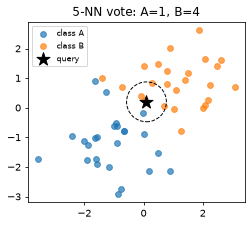

In [3]:
# k=5일 때의 다수결을 그림으로 확인한다
set_seed()
class_a = np.random.normal([-1, -1], 0.9, size=(25, 2))
class_b = np.random.normal([1, 1], 0.9, size=(25, 2))
points = np.vstack([class_a, class_b])
query = np.array([0.1, 0.2])
order = np.argsort(np.linalg.norm(points - query, axis=1))
radius = np.linalg.norm(points[order[4]] - query)   # 5번째로 가까운 점까지의 거리
votes_b = (order[:5] >= 25).sum()

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(*class_a.T, label="class A", alpha=0.7)
ax.scatter(*class_b.T, label="class B", alpha=0.7)
ax.scatter(*query, marker="*", s=200, color="black", label="query")
ax.add_patch(plt.Circle(query, radius, fill=False, linestyle="--"))
ax.set(aspect="equal", title=f"5-NN vote: A={5 - votes_b}, B={votes_b}")
ax.legend(fontsize=8)
plt.show()

먼저 사이킷런의 kNN 분류 모델을 씁니다(`KNeighborsClassifier`는 첫 셀에서 가져왔습니다).

데이터는 사이킷런의 유방암 데이터입니다. 총 30개의 속성과 malignant(악성), benign(양성) 두 가지 타깃 값이 있습니다.

In [4]:
data = load_breast_cancer()
df_data = pd.DataFrame(data.data)
df_labels = pd.DataFrame(data.target)
df_data.head()

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


데이터 개수가 적을수록 차원이 늘 때의 영향이 크게 보이므로 100개로 줄여서 학습시켜 봅니다.

In [5]:
df_data = df_data.iloc[:100, :]
df_labels = df_labels.iloc[:100]

특성마다 단위와 크기가 모두 다르므로, 모든 특성을 평균 0, 분산 1로 맞춥니다. 거리 기반 모델에서는 스케일이 큰 특성이 거리를 독차지하기 때문에 이 단계가 필수입니다.

`hd`는 high dimension(30개 특성 전부), `ld`는 low dimension(앞 10개 특성)입니다.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(df_data, df_labels, test_size=0.4, random_state=42)

# 스케일러는 학습 데이터로만 맞춘다. 테스트 데이터의 정보가 새지 않게 하기 위해서다
scaler = StandardScaler()
scaler.fit(X_train)
X_train_hd = scaler.transform(X_train)
X_test_hd = scaler.transform(X_test)

X_train_ld = X_train_hd[:, :10]
X_test_ld = X_test_hd[:, :10]

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_ld, y_train.values.ravel())   # 사이킷런은 1차원 레이블을 기대한다

print("10 features:", knn.score(X_test_ld, y_test))

10 features: 0.925


In [8]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_hd, y_train.values.ravel())

print("30 features:", knn.score(X_test_hd, y_test))

30 features: 0.925


이 결과만 보고 "차원이 높아지면 정확도가 줄어든다"고 결론 내리고 싶을 수 있습니다. 그러나 테스트 데이터가 40개뿐이라 한 개만 달라져도 2.5%p가 움직입니다. 분할 한 번의 결과로 결론을 내리면 안 됩니다. 분할을 바꿔 가며 다시 봅시다.

In [9]:
for seed in [42, 0, 1, 2, 3]:
    a_train, a_test, b_train, b_test = train_test_split(df_data, df_labels, test_size=0.4, random_state=seed)
    sc = StandardScaler().fit(a_train)
    tr, te = sc.transform(a_train), sc.transform(a_test)
    acc_ld = KNeighborsClassifier(5).fit(tr[:, :10], b_train.values.ravel()).score(te[:, :10], b_test)
    acc_hd = KNeighborsClassifier(5).fit(tr, b_train.values.ravel()).score(te, b_test)
    print(f"split seed={seed:2d}  10 features={acc_ld:.3f}  30 features={acc_hd:.3f}")

split seed=42  10 features=0.925  30 features=0.925
split seed= 0  10 features=0.925  30 features=0.925
split seed= 1  10 features=0.925  30 features=0.850
split seed= 2  10 features=0.925  30 features=0.850
split seed= 3  10 features=0.950  30 features=0.925


분할에 따라 같기도 하고 줄기도 합니다. 유방암 데이터의 30개 특성은 사실 모두 의미 있는 값이어서 이 비교는 차원의 저주를 보여 주기에 좋은 실험이 아닙니다. 차원의 저주는 **특성의 개수가 무의미하게 많을 때** 특히 잘 드러납니다. 전체 569개 데이터에 아무 의미 없는 잡음 특성을 일부러 붙여 봅시다.

noise features=    0  mean test accuracy=0.959
noise features=   10  mean test accuracy=0.946
noise features=   30  mean test accuracy=0.937
noise features=  100  mean test accuracy=0.917
noise features=  300  mean test accuracy=0.875
noise features= 1000  mean test accuracy=0.814


noise features= 3000  mean test accuracy=0.764


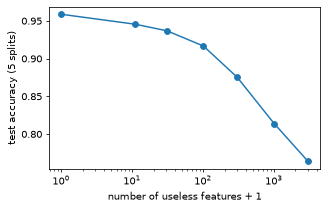

In [10]:
X_full, y_full = load_breast_cancer(return_X_y=True)
noise_counts = [0, 10, 30, 100, 300, 1000, 3000]
noise_acc = []
for n_noise in noise_counts:
    scores = []
    for seed in range(5):
        noise = np.random.default_rng(seed).normal(size=(len(X_full), n_noise))
        X_noisy = np.c_[X_full, noise]
        a, b, c, d = train_test_split(X_noisy, y_full, test_size=0.4, random_state=seed, stratify=y_full)
        sc = StandardScaler().fit(a)
        scores.append(KNeighborsClassifier(5).fit(sc.transform(a), c).score(sc.transform(b), d))
    noise_acc.append(np.mean(scores))
    print(f"noise features={n_noise:5d}  mean test accuracy={noise_acc[-1]:.3f}")

plt.figure(figsize=(5, 3))
plt.plot([n + 1 for n in noise_counts], noise_acc, "o-")
plt.xscale("log")
plt.xlabel("number of useless features + 1")
plt.ylabel("test accuracy (5 splits)")
plt.show()

답을 담은 특성 30개는 그대로인데, 잡음이 늘수록 정확도가 뚝뚝 떨어집니다. 물론 모든 경우에 그렇지는 않지만, 무의미한 특성이 많을 때 이렇게 차원의 저주에 걸리기 쉽습니다. 그러면 **의미 있는 차원만 남기는** 방법이 필요합니다.

## 1.3 매니폴드(Manifold)

이미지는 784차원 공간의 점이지만, 그 공간에서 아무 점이나 찍으면 잡음만 나옵니다. 실제 이미지는 전체 공간 중 아주 얇은 일부에만 모여 있습니다. **매니폴드 가설**은 고차원 데이터가 그보다 훨씬 낮은 차원의 매끄러운 곡면 근처에 놓여 있다는 생각입니다.

**매니폴드**는 데이터를 최대한 오차 없이 아우르는 그런 저차원 곡면입니다. "부분 공간(subspace)"이라고 설명하는 글도 있는데, 수학에서 부분 공간은 원점을 지나는 평평한 공간만을 뜻합니다. 매니폴드는 **휘어져 있어도 되고, 좁은 영역에서만 평평해 보이면 됩니다.** 지구 표면이 전체로는 구이지만 동네에서는 평면처럼 보이는 것과 같습니다. 이 차이가 곧 아래에서 볼 PCA와 t-SNE, UMAP의 차이입니다.

**Manifold Learning**은 이런 매니폴드를 잘 찾는 것을 목표로 합니다. 찾아낸다면 데이터의 특징을 유지하면서 저차원으로 압축할 수 있습니다.

(참고 그림: [매니폴드 그림](https://velog.velcdn.com/images%2Fxuio%2Fpost%2Febfccc83-3168-4956-af90-3df89c9f1fbb%2Fimage.png). 아래에서 스위스 롤로 직접 확인합니다.)

Manifold Learning을 위한 모델 종류는 다음과 같습니다.

- 선형 변환(Linear Transformation)
  - 주성분 분석(Principal Component Analysis, PCA)
- 비선형 변환(Non-linear Transformation)
  - 오토인코더(Autoencoder, AE)
  - t-SNE (t-distributed Stochastic Neighbor Embedding)
  - UMAP (Uniform Manifold Approximation and Projection)

말려 있는 2차원 종이인 **스위스 롤**로 선형과 비선형의 차이를 미리 봅시다.

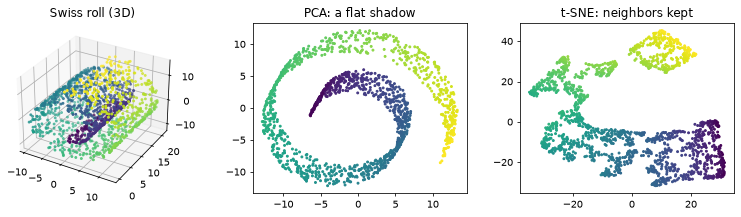

In [11]:
roll, roll_color = make_swiss_roll(n_samples=1500, noise=0.05, random_state=0)
roll_pca = PCA(n_components=2).fit_transform(roll)
roll_tsne = TSNE(n_components=2, perplexity=40, random_state=0).fit_transform(roll)

fig = plt.figure(figsize=(11, 3.2))
ax = fig.add_subplot(131, projection="3d")
ax.scatter(*roll.T, c=roll_color, cmap="viridis", s=4)
ax.set_title("Swiss roll (3D)")
ax = fig.add_subplot(132)
ax.scatter(*roll_pca.T, c=roll_color, cmap="viridis", s=4)
ax.set_title("PCA: a flat shadow")
ax = fig.add_subplot(133)
ax.scatter(*roll_tsne.T, c=roll_color, cmap="viridis", s=4)
ax.set_title("t-SNE: neighbors kept")
plt.tight_layout()
plt.show()

색은 종이 위의 위치입니다. PCA는 직선으로 투영만 하므로 말린 종이를 펴지 못하고, 말린 모양이 그대로 남습니다. 나선 위에서 색이 크게 다른 점(종이 위에서 먼 점)도 층 사이의 직선거리로는 가까워 보입니다. t-SNE는 이웃 관계를 지키려 하기 때문에 종이를 어느 정도 펼쳐 놓습니다. 다만 전체 모양은 찢어지기도 합니다.

## 1.4 PCA

**PCA**는 기존 변수를 선형 조합하여 새로운 변수를 만드는, 분산 기반의 선형 변환 기법입니다.

데이터를 직선 위로 투영했을 때 **투영된 점들의 분산이 가장 커지는 방향**을 찾습니다. 투영 후에 점들이 최대한 겹치지 않고 퍼져 있는 방향이니 정보를 가장 많이 남기는 방향입니다. 이 방향은 공분산 행렬의 **고유벡터**(eigenvector)이고, 그 방향의 분산이 **고유값**(eigenvalue)입니다. 고유값이 큰 순서대로 k개를 고르고 그 방향으로 선형 변환합니다.

자세한 설명: [PCA 정리 글](https://ljm565.github.io/contents/ManifoldLearning2.html) · [회전하는 투영선 애니메이션](https://velog.velcdn.com/images%2Fswan9405%2Fpost%2F6b1446e0-fe48-497c-9191-20e3ce447e96%2Fpca02.gif)

그 애니메이션의 내용을 그래프로 옮겨 봅니다. 직선을 돌려 가며 투영 분산을 재고, 고유벡터의 방향과 같은지 확인합니다.

largest projected variance: 4.356, at 29 deg
largest eigenvalue        : 4.356, direction 29 deg


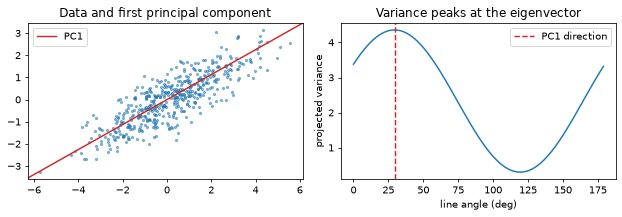

In [12]:
set_seed()
cov_true = np.array([[3.0, 1.5], [1.5, 1.2]])
points_2d = np.random.multivariate_normal([0, 0], cov_true, size=500)

# 직선의 각도를 바꿔 가며 투영 분산을 잰다
angles = np.linspace(0, np.pi, 180, endpoint=False)
directions = np.c_[np.cos(angles), np.sin(angles)]
projected_var = (points_2d @ directions.T).var(axis=0, ddof=1)

# 공분산 행렬의 고유벡터를 구한다. eigh는 고유값을 오름차순으로 돌려준다
eigvals, eigvecs = np.linalg.eigh(np.cov(points_2d.T))
pc1 = eigvecs[:, -1]
pc1_angle = np.arctan2(pc1[1], pc1[0]) % np.pi

print(f"largest projected variance: {projected_var.max():.3f}, at {np.degrees(angles[projected_var.argmax()]):.0f} deg")
print(f"largest eigenvalue        : {eigvals[-1]:.3f}, direction {np.degrees(pc1_angle):.0f} deg")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].scatter(*points_2d.T, s=5, alpha=0.5)
axes[0].axline((0, 0), slope=pc1[1] / pc1[0], color="tab:red", label="PC1")
axes[0].set(aspect="equal", title="Data and first principal component")
axes[0].legend()
axes[1].plot(np.degrees(angles), projected_var)
axes[1].axvline(np.degrees(pc1_angle), color="tab:red", linestyle="--", label="PC1 direction")
axes[1].set(xlabel="line angle (deg)", ylabel="projected variance", title="Variance peaks at the eigenvector")
axes[1].legend()
plt.tight_layout()
plt.show()

이번에는 iris 데이터셋을 가져와서 특성 스케일을 정규화합니다.

In [13]:
# 데이터셋 로드
iris = load_iris()
df = pd.DataFrame(data=np.c_[iris.data])

# 데이터셋 정규화
scaler = StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)

# 데이터프레임으로 자료형 변환 및 target class 정보 추가
df_scaled = pd.DataFrame(df_scaled, columns=["sepal length", "sepal width", "petal length", "petal width"])
df_scaled["target"] = iris.target

df_scaled

,sepal length,sepal width,petal length,petal width,target
0,-0.900681,1.019004,-1.340227,-1.315444,0
1,-1.143017,-0.131979,-1.340227,-1.315444,0
2,-1.385353,0.328414,-1.397064,-1.315444,0
3,-1.506521,0.098217,-1.283389,-1.315444,0
4,-1.021849,1.249201,-1.340227,-1.315444,0
...,...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832,2
146,0.553333,-1.282963,0.705921,0.922303,2
147,0.795669,-0.131979,0.819596,1.053935,2
148,0.432165,0.788808,0.933271,1.448832,2


사이킷런의 `PCA`로 쉽게 변환할 수 있습니다. `n_components`에는 원하는 차원의 수를 넣습니다.

In [14]:
# 2차원으로 차원 축소, target 정보는 제외
pca = PCA(n_components=2)
pca.fit(df_scaled.iloc[:, :-1])

# pca transform 후 데이터프레임으로 자료형 변경
df_pca = pca.transform(df_scaled.iloc[:, :-1])
df_pca = pd.DataFrame(df_pca, columns=["component 0", "component 1"])

df_pca

,component 0,component 1
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835
...,...,...
145,1.870503,0.386966
146,1.564580,-0.896687
147,1.521170,0.269069
148,1.372788,1.011254


PCA의 주성분 설명력을 볼 수 있습니다. 첫 주성분이 데이터 분산을 가장 많이 설명합니다.

In [15]:
# PCA 주성분 설명력 출력
print(pca.explained_variance_ratio_)
print("explained by 2 components:", pca.explained_variance_ratio_.sum())

[0.72962445 0.22850762]
explained by 2 components: 0.9581320720000165


PCA로 2차원이 되었으니 시각화할 수 있습니다. 주성분 값을 뿌려 보고 꽃 종류별로 잘 나뉘는지 확인합니다. 같은 그림을 t-SNE와 UMAP에서도 그릴 것이므로 함수로 만들어 둡니다.

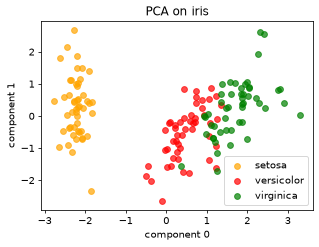

In [16]:
def scatter_by_class(embedding: pd.DataFrame, target: pd.Series, title: str) -> None:
    """2차원 임베딩을 붓꽃 종류별 색으로 그립니다."""
    names = ["setosa", "versicolor", "virginica"]
    colors = ["orange", "red", "green"]
    for class_id, (name, color) in enumerate(zip(names, colors)):
        part = embedding[target == class_id]
        plt.scatter(part["component 0"], part["component 1"], color=color, alpha=0.7, label=name)
    plt.xlabel("component 0")
    plt.ylabel("component 1")
    plt.title(title)
    plt.legend()
    plt.show()


plt.figure(figsize=(5, 3.5))
scatter_by_class(df_pca, df_scaled["target"], "PCA on iris")

## 1.5 t-SNE (t-distributed Stochastic Neighbor Embedding)

고차원에서 **가까웠던 점들이 저차원에서도 가깝게** 놓이도록 점의 위치를 옮겨 가며 차원을 줄이는 비선형 기법입니다.

**기본 원리**

점들을 저차원에 임의로(또는 PCA로) 배치한 다음, 고차원의 이웃 관계와 저차원의 이웃 관계가 비슷해지도록 경사하강법으로 조금씩 옮깁니다. 흔히 "거리를 유지한다"고 설명하지만 조금 부정확합니다. t-SNE가 맞추는 것은 거리 자체가 아니라 거리에서 만든 **유사도(확률)**입니다. 이 차이는 아래 단점에서 중요해집니다.

**유사도를 구하는 방법**

고차원에서는 정규분포로 유사도를 만듭니다. 점 $i$ 입장에서 점 $j$를 이웃으로 고를 확률입니다.

$$p_{j|i}=\frac{\exp(-\|x_i-x_j\|^2/2\sigma_i^2)}{\sum_{k\neq i}\exp(-\|x_i-x_k\|^2/2\sigma_i^2)},\qquad p_{ij}=\frac{p_{j|i}+p_{i|j}}{2n}$$

$\sigma_i$는 점마다 다르며, 사용자가 정한 **perplexity**(대략 "이웃으로 고려할 점의 개수")를 맞추도록 정해집니다.

저차원에서는 자유도 1인 t 분포로 유사도를 만듭니다.

$$q_{ij}=\frac{(1+\|y_i-y_j\|^2)^{-1}}{\sum_{k\neq l}(1+\|y_k-y_l\|^2)^{-1}}$$

그리고 두 분포의 차이인 KL 발산 $\sum_{i\neq j} p_{ij}\log\frac{p_{ij}}{q_{ij}}$를 최소화합니다.

**왜 저차원에서 t 분포를 쓰나요?** t 분포는 정규분포보다 꼬리가 두껍습니다. 고차원에는 "적당히 가까운" 점이 아주 많은데 2차원에는 그 많은 점을 놓을 자리가 부족합니다(crowding problem). 꼬리가 두꺼우면 그런 점들을 저차원에서 조금 더 멀리 놓아도 유사도가 크게 떨어지지 않아서 군집이 눌어붙지 않습니다.

t 분포와 정규분포의 차이는 아래 그래프로, 실제 결과는 이어지는 실험으로 확인합니다.

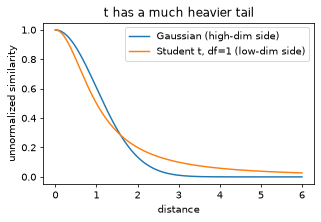

distance 1: Gaussian=0.6065, t=0.5000
distance 2: Gaussian=0.1353, t=0.2000
distance 4: Gaussian=0.0003, t=0.0588


In [17]:
dist_axis = np.linspace(0, 6, 200)
gauss_sim = np.exp(-dist_axis ** 2 / 2)
t_sim = 1 / (1 + dist_axis ** 2)

plt.figure(figsize=(5, 3))
plt.plot(dist_axis, gauss_sim, label="Gaussian (high-dim side)")
plt.plot(dist_axis, t_sim, label="Student t, df=1 (low-dim side)")
plt.xlabel("distance")
plt.ylabel("unnormalized similarity")
plt.title("t has a much heavier tail")
plt.legend()
plt.show()

for d in [1, 2, 4]:
    print(f"distance {d}: Gaussian={math.exp(-d ** 2 / 2):.4f}, t={1 / (1 + d ** 2):.4f}")

PCA에서 사용한 데이터를 그대로 가지고 t-SNE를 해 봅시다.

In [18]:
# 2차원 t-SNE 임베딩, target 정보는 제외
tsne = TSNE(n_components=2, random_state=0)
df_tsne = tsne.fit_transform(df_scaled.iloc[:, :-1])

# 데이터프레임으로 자료형 변경
df_tsne = pd.DataFrame(df_tsne, columns=["component 0", "component 1"])

df_tsne

,component 0,component 1
0,-25.917686,-1.001229
1,-22.148052,-0.096169
2,-23.116467,-1.127652
3,-22.350016,-1.155122
4,-26.519518,-0.650842
...,...,...
145,14.365085,0.744862
146,8.716403,2.713384
147,13.194552,0.665156
148,15.255013,2.267283


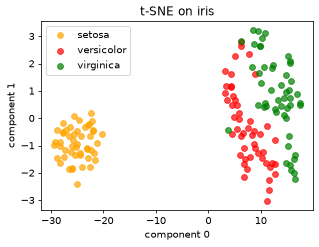

In [19]:
plt.figure(figsize=(5, 3.5))
scatter_by_class(df_tsne, df_scaled["target"], "t-SNE on iris")

손글씨 데이터인 MNIST를 시각화해 봅시다. 784차원을 바로 넣지 않고 PCA로 50차원까지 줄인 다음 t-SNE를 돌립니다. [사이킷런 문서](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)도 특성이 아주 많을 때 이렇게 하기를 권합니다.

elapsed: 2.7s


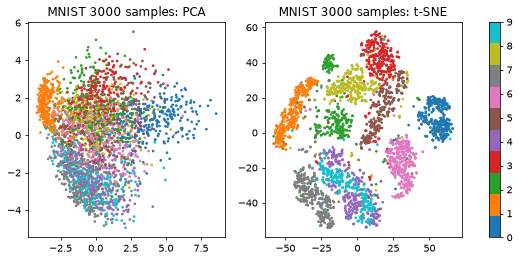

In [20]:
mnist_raw = datasets.MNIST(DATA_ROOT, train=True, download=True)
rng = np.random.default_rng(0)
idx = rng.choice(len(mnist_raw), 3000, replace=False)
mnist_x = mnist_raw.data[idx].numpy().reshape(-1, 784) / 255.0
mnist_y = mnist_raw.targets[idx].numpy()

start = time.time()
mnist_pca2 = PCA(n_components=2, random_state=0).fit_transform(mnist_x)
mnist_pca50 = PCA(n_components=50, random_state=0).fit_transform(mnist_x)
mnist_tsne = TSNE(n_components=2, random_state=0).fit_transform(mnist_pca50)
print(f"elapsed: {time.time() - start:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, emb, title in zip(axes, [mnist_pca2, mnist_tsne], ["PCA", "t-SNE"]):
    sc = ax.scatter(*emb.T, c=mnist_y, cmap="tab10", s=3)
    ax.set_title(f"MNIST 3000 samples: {title}")
fig.colorbar(sc, ax=axes, ticks=range(10))
plt.show()

**t-SNE의 장점과 단점**

장점

- PCA는 저차원으로 눌렀을 때 겹쳐서 뭉개지는 부분이 많지만, t-SNE는 그 문제가 많이 해소됩니다. 위 MNIST 그림에서 확인할 수 있습니다.
- 기존 SNE의 문제였던 crowding 문제와 최적화의 어려움을 t 분포로 완화했습니다.

단점

- 데이터가 많으면 시간이 오래 걸립니다.
- 특성이 아주 많으면 그대로 넣지 말고 먼저 PCA 등으로 줄이는 것이 좋습니다.
- **저차원 임베딩의 거리는 실제 데이터의 거리를 뜻하지 않습니다. 군집의 크기와 군집 사이의 간격도 의미가 없습니다.**
- 저차원으로 줄이면서 정보 손실과 왜곡이 생깁니다.
- 초기값과 난수에 따라 결과가 달라집니다. 사이킷런은 지금 PCA 초기화가 기본값이지만 `random_state`를 고정해야 재현됩니다.

> **주의**: t-SNE는 하이퍼파라미터의 영향이 적다는 설명을 볼 수 있는데, 아래 실험과 맞지 않습니다. perplexity 값에 따라 그림이 크게 달라집니다.

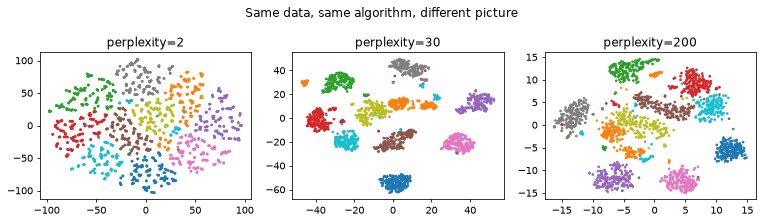

In [21]:
digits_x, digits_y = load_digits(return_X_y=True)
perplexities = [2, 30, 200]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, perp in zip(axes, perplexities):
    emb = TSNE(n_components=2, perplexity=perp, random_state=0).fit_transform(digits_x)
    ax.scatter(*emb.T, c=digits_y, cmap="tab10", s=3)
    ax.set_title(f"perplexity={perp}")
plt.suptitle("Same data, same algorithm, different picture")
plt.tight_layout()
plt.show()

같은 데이터인데 그림의 인상이 크게 다릅니다. 그래서 t-SNE 그림 한 장을 보고 "군집이 3개다", "이 두 군집은 멀다"고 결론을 내리면 안 됩니다. 여러 설정으로 그려 보세요. 흥미로운 사례는 [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/)에 있습니다.

## 1.6 UMAP (Uniform Manifold Approximation and Projection)

고차원에서 만든 **그래프**와 저차원에서 만든 그래프가 비슷해지도록 최적화해 변환하는 기법입니다.

UMAP은 t-SNE의 문제점을 많이 해결했고, 데이터 특징을 학습하는 목적에 더 적절한 수학적 이론을 바탕으로 한다고 소개됩니다.

**UMAP의 원리**

각 데이터를 노드(node)로, 두 데이터 사이의 연결 확률을 그 둘을 잇는 엣지(edge)의 가중치로 생각합니다. 고차원의 그래프 관계가 저차원에서도 비슷하게 유지되도록 점의 위치를 학습합니다.

이 그래프를 만드는 이론적 틀이 **fuzzy simplicial complex**입니다. 복잡해 보이지만 그림은 단순합니다.

- 각 점 주위에 원을 그리고 반지름(extent)을 점점 키웁니다. 두 점의 원이 겹치면 두 점이 연결되어 있다고 봅니다.
- 이 반지름이 중요합니다. 너무 작으면 작고 고립된 클러스터들이 생기고, 너무 크면 모든 것이 연결됩니다.
- 그래서 `n_neighbors`번째로 가까운 점까지의 거리를 기준으로 **점마다 반지름을 따로 정합니다.** 밀집 지역의 점은 반지름이 작고, 성긴 지역의 점은 반지름이 큽니다. n번째로 가까운 점의 거리가 짧을수록 반지름이 천천히 커집니다.
- 원의 경계를 흐리게(fuzzy) 합니다. 반지름이 커질수록 먼 점과의 연결 강도가 줄어듭니다.
- 각 점은 **최소한 가장 가까운 점과는 반드시 연결**되도록 합니다. 그래야 데이터 구조가 조각나지 않습니다.

(그림으로 잘 설명한 글: [Understanding UMAP](https://pair-code.github.io/understanding-umap/))

**UMAP의 파라미터**

- `n_neighbors`: 그래프를 만들 때 고려하는 이웃의 수입니다. 작으면 국소 구조에, 크면 전역 구조에 집중합니다.
- `min_dist`: 저차원에서 점 사이의 최소 거리입니다. 점들을 얼마나 촘촘하게 묶을지 조절합니다.

UMAP은 흔히 t-SNE보다 빠르고 전역 구조를 잘 유지한다고 소개됩니다. 속도는 아래에서 직접 재어 봅니다. 그리고 전역 구조의 유지는 UMAP 자체보다 초기화의 영향이 크다는 반론도 있습니다([Kobak & Linderman, 2021](https://www.nature.com/articles/s41587-020-00809-z)). 이 부분은 아직 논쟁 중이라고 알아 두면 충분합니다.

UMAP은 코랩에 기본으로 설치되어 있지 않아 첫 셀에서 `umap-learn`을 설치했습니다.

In [22]:
# 2차원 UMAP 임베딩, target 정보는 제외
umap_model = UMAP(n_components=2, random_state=0)
df_umap = umap_model.fit_transform(df_scaled.iloc[:, :-1])

# 데이터프레임으로 자료형 변경
df_umap = pd.DataFrame(df_umap, columns=["component 0", "component 1"])

df_umap

,component 0,component 1
0,-1.041527,6.942821
1,-2.381450,9.741685
2,-1.796326,9.169215
3,-1.852495,9.437611
4,-0.967715,6.558481
...,...,...
145,12.100883,3.146561
146,10.901809,4.925584
147,11.526299,3.497652
148,12.689327,3.661301


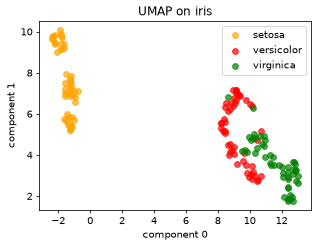

In [23]:
plt.figure(figsize=(5, 3.5))
scatter_by_class(df_umap, df_scaled["target"], "UMAP on iris")

파라미터가 그림을 어떻게 바꾸는지 봅니다.

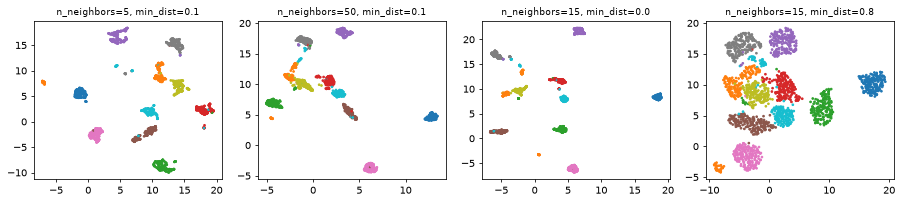

In [24]:
settings = [(5, 0.1), (50, 0.1), (15, 0.0), (15, 0.8)]
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (nn_value, md_value) in zip(axes, settings):
    emb = UMAP(n_neighbors=nn_value, min_dist=md_value, random_state=0).fit_transform(digits_x)
    ax.scatter(*emb.T, c=digits_y, cmap="tab10", s=3)
    ax.set_title(f"n_neighbors={nn_value}, min_dist={md_value}", fontsize=9)
plt.tight_layout()
plt.show()

이제 Fashion-MNIST에서 UMAP과 t-SNE를 같은 데이터로 비교합니다.

10000 samples, 784 dims (no PCA first)
t-SNE                  : 9.3s
UMAP seed, first run   : 17.5s
UMAP seed, second run  : 7.9s
UMAP no seed, parallel : 1.6s


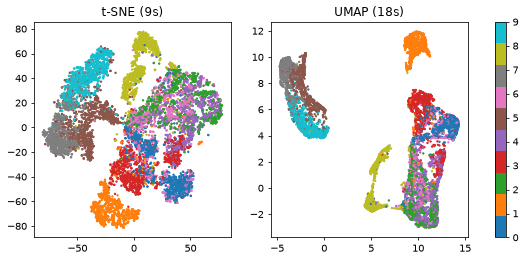

In [25]:
fashion_raw = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
FASHION_SAMPLES = 10000
idx = np.random.default_rng(0).choice(len(fashion_raw), FASHION_SAMPLES, replace=False)
fashion_x = fashion_raw.data[idx].numpy().reshape(-1, 784) / 255.0
fashion_y = fashion_raw.targets[idx].numpy()

start = time.time()
fashion_tsne = TSNE(n_components=2, random_state=0).fit_transform(fashion_x)
tsne_time = time.time() - start



def timed_umap(**kwargs: int) -> tuple[np.ndarray, float]:
    """UMAP을 실행하고 (임베딩, 걸린 시간)을 돌려줍니다."""
    begin = time.time()
    result = UMAP(n_components=2, **kwargs).fit_transform(fashion_x)
    return result, time.time() - begin


# 같은 설정을 두 번 재어 첫 실행의 준비 비용을 분리하고, 시드 고정의 비용도 따로 잰다
fashion_umap, umap_time = timed_umap(random_state=0)
_, umap_seed_again = timed_umap(random_state=0)
_, umap_no_seed = timed_umap()
print(f"{FASHION_SAMPLES} samples, 784 dims (no PCA first)")
print(f"t-SNE                  : {tsne_time:.1f}s")
print(f"UMAP seed, first run   : {umap_time:.1f}s")
print(f"UMAP seed, second run  : {umap_seed_again:.1f}s")
print(f"UMAP no seed, parallel : {umap_no_seed:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(*fashion_tsne.T, c=fashion_y, cmap="tab10", s=2)
axes[0].set_title(f"t-SNE ({tsne_time:.0f}s)")
sc = axes[1].scatter(*fashion_umap.T, c=fashion_y, cmap="tab10", s=2)
axes[1].set_title(f"UMAP ({umap_time:.0f}s)")
fig.colorbar(sc, ax=axes, ticks=range(10))
plt.show()

위 출력에서 세 가지를 읽을 수 있습니다.

- **첫 실행은 느립니다.** 같은 설정으로 다시 돌리면 훨씬 빨라집니다. 이 크기의 데이터를 처음 다룰 때 드는 준비 비용으로 보입니다.
- **`random_state`를 고정하면 UMAP은 단일 스레드로 돕니다.** UMAP도 `n_jobs value 1 overridden to 1 by setting random_state`라는 경고로 알려 줍니다. 재현성의 대가입니다.
- **시드 없이 병렬로 돌리면 t-SNE보다 훨씬 빠릅니다.** "빠르다"는 소개는 이 측정과 맞습니다.

첫 실행 값만 보면 t-SNE가 빨라 보이므로, 조건을 나눠 재야 합니다. 여기서는 같은 입력으로 비교하려고 두 방법 모두 784차원을 그대로 넣었습니다. 앞에서 MNIST에 했듯 PCA를 먼저 쓰면 t-SNE도 더 빨라질 수 있습니다. **속도 비교는 구현, 설정, 데이터 크기에 따라 달라지니** 내 데이터로 재 보는 것이 가장 정확합니다.

이웃이 얼마나 보존되는지 숫자로 재 볼 수도 있습니다. `trustworthiness`는 저차원에서 이웃이 된 점이 원래도 이웃이었는지를 0에서 1 사이 값으로 재는 지표입니다.

In [26]:
trust_rows = {}
for name, emb in [
    ("PCA", PCA(n_components=2, random_state=0).fit_transform(digits_x)),
    ("t-SNE", TSNE(n_components=2, random_state=0).fit_transform(digits_x)),
    ("UMAP", UMAP(n_components=2, random_state=0).fit_transform(digits_x)),
]:
    trust_rows[name] = trustworthiness(digits_x, emb, n_neighbors=10)
    print(f"{name:6s} trustworthiness = {trust_rows[name]:.3f}")

PCA    trustworthiness = 0.830
t-SNE  trustworthiness = 0.993


UMAP   trustworthiness = 0.988


PCA보다 t-SNE와 UMAP이 이웃을 훨씬 잘 보존합니다. 두 방법은 애초에 이웃 보존을 목적으로 만들어졌으니 당연한 결과이고, 전역 거리까지 잘 지킨다는 뜻은 아닙니다.

### 실습 1. PCA 직접 구현

`np.linalg.eigh`로 PCA를 직접 구현하세요. `X`의 평균을 빼고, 공분산 행렬의 고유값 분해를 하고, 고유값이 큰 순서로 `k`개의 고유벡터에 투영합니다. 돌려주는 값은 (투영 결과, 설명된 분산 비율)입니다. 사이킷런의 결과와 같은지 assert로 확인합니다(고유벡터는 부호가 임의이므로 절댓값으로 비교합니다).

```python
def pca_from_scratch(X: np.ndarray, k: int) -> tuple[np.ndarray, np.ndarray]:
    ...
```

In [27]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def pca_from_scratch(X: np.ndarray, k: int) -> tuple[np.ndarray, np.ndarray]:
    """공분산 행렬의 고유값 분해로 k차원 PCA를 계산합니다."""
    centered = X - X.mean(axis=0)
    eigvals, eigvecs = np.linalg.eigh(np.cov(centered.T))
    # eigh는 오름차순으로 돌려주므로 뒤집는다
    order = np.argsort(eigvals)[::-1][:k]
    projected = centered @ eigvecs[:, order]
    return projected, eigvals[order] / eigvals.sum()


iris_x = df_scaled.iloc[:, :-1].to_numpy()
mine, ratio = pca_from_scratch(iris_x, 2)
theirs = PCA(n_components=2).fit(iris_x)
assert np.allclose(ratio, theirs.explained_variance_ratio_)
assert np.allclose(np.abs(mine), np.abs(theirs.transform(iris_x)))
print("OK", ratio)
```

</details>

---
# 2교시. AutoEncoder

## 2.1 오토인코더란

**오토인코더**(AutoEncoder, AE)는 정답 레이블 없이 학습하는 비지도 신경망으로, 입력을 출력으로 복사하는 법을 배웁니다.

그냥 복사하면 아무 의미가 없으므로 여러 가지 제약을 줍니다.

- 은닉층의 뉴런 수를 입력층보다 작게 해서 데이터를 압축(차원 축소)합니다. 구조가 모래시계 모양이 됩니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Ft1.daumcdn.net%2Fcfile%2Ftistory%2F996C93475BDC97C00A))
- 입력에 잡음(noise)을 추가한 후 깨끗한 입력을 복원하도록 학습합니다.

이런 제약 때문에 모델은 입력을 그대로 외울 수 없고, 데이터에 있는 **패턴**을 찾아 활용하게 됩니다.

- **인코더(Encoder)**: 입력을 내부 표현으로 바꿉니다(인지 네트워크, recognition network).
- **디코더(Decoder)**: 내부 표현을 출력으로 바꿉니다(생성 네트워크, generative network).

즉 인코더는 정보를 받아 압축하고, 디코더는 압축된 표현을 풀어 입력을 복원합니다.

```
입력 784 → 128 → 64 → 12 → [잠재 변수 3] → 12 → 64 → 128 → 출력 784
           `------ 인코더 ------'              `------ 디코더 ------'
```

## 2.2 오토인코더 구현

'펭귄브로의 3분 딥러닝 파이토치맛' 교재를 바탕으로 작성된 [코드 공유 글](https://dacon.io/codeshare/4551)을 따라 구현합니다.

In [28]:
# 하이퍼파라미터 준비
EPOCH = 10
BATCH_SIZE = 64

Fashion-MNIST 데이터셋을 사용합니다. 옷과 신발 사진 10종류, 28×28 흑백 이미지입니다.

In [29]:
# Fashion MNIST 데이터셋 불러오기 (학습 데이터만 사용)
trainset = datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=transforms.ToTensor(),
)
train_loader = torch.utils.data.DataLoader(
    dataset=trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

오토인코더 모듈을 정의합니다.

In [30]:
class Autoencoder(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        # 인코더는 간단한 신경망으로 분류 모델처럼 생겼다
        self.encoder = nn.Sequential(   # nn.Sequential로 인코더와 디코더를 각각 묶는다
            nn.Linear(28 * 28, 128),    # 차원을 28*28에서 점차 줄여 나간다
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 12),
            nn.ReLU(),
            nn.Linear(12, 3),           # 입력의 특징을 3차원으로 압축한다(출력이 곧 잠재 변수)
        )
        self.decoder = nn.Sequential(
            nn.Linear(3, 12),           # 디코더는 차원을 점차 28*28로 복원한다
            nn.ReLU(),
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid(),               # 픽셀 값이 0과 1 사이이므로 출력도 그 범위로 맞춘다
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        encoded = self.encoder(x)         # 인코더가 잠재 변수를 만들고
        decoded = self.decoder(encoded)   # 디코더가 복원 이미지를 만든다
        return encoded, decoded

옵티마이저와 손실 함수를 정의합니다. 입력 값과 디코더가 낸 값의 차이를 재기 위해 평균제곱오차(MSE)를 씁니다.

In [31]:
set_seed()
autoencoder = Autoencoder().to(device)
# Adam은 SGD의 변형으로, 기울기의 이력을 참고해 파라미터별 학습 속도를 조절한다
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.005)
criterion = nn.MSELoss()

5개의 이미지가 학습이 진행되며 어떻게 바뀌는지 관찰하기 위해 `view_data`를 정의합니다.

In [32]:
# 복원이 어떻게 되는지 관찰하기 위해 5개의 이미지를 가져온다
view_data = trainset.data[:5].view(-1, 28 * 28)
# 픽셀 값이 0~255이므로 모델이 다루는 0~1 사이 값으로 만들기 위해 255로 나눈다
view_data = view_data.type(torch.FloatTensor) / 255.0

학습 코드입니다. **입력과 정답이 모두 같은 이미지**라는 점에 주의하세요.

In [33]:
def train(autoencoder: nn.Module, train_loader: torch.utils.data.DataLoader) -> float:
    """한 에폭 학습하고 평균 손실을 돌려줍니다."""
    autoencoder.train()
    total_loss = 0.0
    for x, _ in train_loader:
        x = x.view(-1, 28 * 28).to(device)
        y = x   # 입력(x)과 정답(y) 모두 같은 이미지다

        encoded, decoded = autoencoder(x)

        loss = criterion(decoded, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

에폭이 돌 때마다 `view_data`를 디코더가 어떻게 복원하는지 기록합니다. 매 에폭 그림을 그리면 그림이 10장이 되므로, 1, 5, 10 에폭의 결과만 모아 한 장에 그립니다.

[Epoch 1] loss: 0.03702


[Epoch 2] loss: 0.02607


[Epoch 3] loss: 0.02458


[Epoch 4] loss: 0.02372


[Epoch 5] loss: 0.02330


[Epoch 6] loss: 0.02284


[Epoch 7] loss: 0.02256


[Epoch 8] loss: 0.02235


[Epoch 9] loss: 0.02223


[Epoch 10] loss: 0.02204


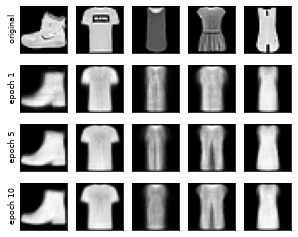

In [34]:
SNAPSHOT_EPOCHS = [1, 5, 10]
snapshots = {}
for epoch in range(1, EPOCH + 1):
    loss = train(autoencoder, train_loader)
    print(f"[Epoch {epoch}] loss: {loss:.5f}")
    if epoch in SNAPSHOT_EPOCHS:
        autoencoder.eval()
        with torch.no_grad():
            _, decoded_data = autoencoder(view_data.to(device))
        snapshots[epoch] = decoded_data.cpu().numpy()

# 입력과 디코딩 결과 비교
fig, axes = plt.subplots(1 + len(SNAPSHOT_EPOCHS), 5, figsize=(5, 4.2))
for i in range(5):
    axes[0][i].imshow(view_data[i].reshape(28, 28).numpy(), cmap="gray")
    for row, epoch in enumerate(SNAPSHOT_EPOCHS, start=1):
        axes[row][i].imshow(snapshots[epoch][i].reshape(28, 28), cmap="gray")
axes[0][0].set_ylabel("original", fontsize=8)
for row, epoch in enumerate(SNAPSHOT_EPOCHS, start=1):
    axes[row][0].set_ylabel(f"epoch {epoch}", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks(())
    ax.set_yticks(())
plt.show()

그럼 인코더를 통해 나온 값을 확인해 봅시다.

In [35]:
# 잠재 변수를 3D 플롯으로 시각화하기 위해 이미지 200개를 준비한다
view_data = trainset.data[:200].view(-1, 28 * 28)
view_data = view_data.type(torch.FloatTensor) / 255.0
autoencoder.eval()
with torch.no_grad():
    encoded_data, _ = autoencoder(view_data.to(device))
encoded_data = encoded_data.cpu()

3D 공간에서 각 클래스는 어떻게 모여 있을까요? 점마다 글자를 찍으면 200개의 글자가 겹쳐 읽기 어려우므로, 클래스별 색의 점으로 그립니다.

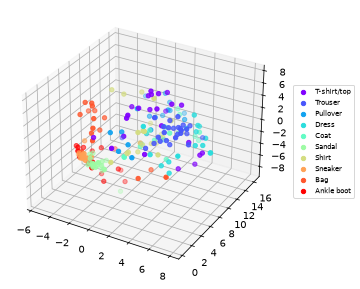

In [36]:
CLASSES = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
labels = trainset.targets[:200].numpy()
for class_id, name in CLASSES.items():
    part = encoded_data[labels == class_id].numpy()
    ax.scatter(*part.T, color=cm.rainbow(class_id / 9), label=name, s=20)
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.05, 0.5))
plt.show()

그림은 인상일 뿐이니 숫자로도 확인합니다. 잠재 변수 3개만 가지고 kNN 분류를 해 보면 "같은 레이블끼리 모였는지"를 잴 수 있습니다. 비교 대상은 픽셀 그대로인 784차원입니다. **레이블은 오토인코더 학습에 전혀 쓰지 않았습니다.**

In [37]:
testset = datasets.FashionMNIST(root=DATA_ROOT, train=False, download=True, transform=transforms.ToTensor())


def to_flat(dataset: datasets.FashionMNIST, n: int) -> tuple[torch.Tensor, np.ndarray]:
    """데이터셋의 앞 n개를 0~1 범위의 1차원 텐서와 레이블로 돌려줍니다."""
    x = dataset.data[:n].view(-1, 28 * 28).type(torch.FloatTensor) / 255.0
    return x, dataset.targets[:n].numpy()


x_tr, y_tr = to_flat(trainset, 10000)
x_te, y_te = to_flat(testset, 2000)
with torch.no_grad():
    z_tr = autoencoder.encoder(x_tr.to(device)).cpu().numpy()
    z_te = autoencoder.encoder(x_te.to(device)).cpu().numpy()

print("kNN on 784-dim pixels :", KNeighborsClassifier(5).fit(x_tr.numpy(), y_tr).score(x_te.numpy(), y_te))
print("kNN on 3-dim latent   :", KNeighborsClassifier(5).fit(z_tr, y_tr).score(z_te, y_te))
print("random guess          :", 0.1)

kNN on 784-dim pixels : 0.8225
kNN on 3-dim latent   : 0.728
random guess          : 0.1


레이블을 한 번도 본 적 없는데도 3차원 잠재 변수만으로 무작위 찍기(10%)를 훌쩍 넘습니다. 같은 레이블의 이미지가 잠재 공간에서 서로 모인다는 뜻입니다. 곧 **차원 축소**(Dimension Reduction)입니다. 다만 그림과 점수에서 보이듯 비슷하게 생긴 옷(셔츠, 코트, 풀오버 등)은 완전히 나뉘지 않고, 784차원 kNN보다 정확도가 낮습니다. 3차원으로 누르면서 잃은 정보가 있기 때문입니다.

왜 이름이 **오토**인코더인지도 알 수 있습니다. ([구조 그림](https://pebpung.github.io/assets/img/2021-09-11/AutoEncoder-1/Untitled.png))

압축 과정에서 추출한 의미 있는 데이터 z를 보통 **잠재 벡터**(latent vector)라고 부릅니다. 중요한 점은 오토인코더가 출력하는 잠재 벡터를 우리가 미리 알 수 없다는 사실입니다. 우리는 3차원으로 압축하라고만 했을 뿐이고, 무엇을 담을지는 모델이 학습으로 찾아 냅니다.

그래서 고차원 데이터를 잘 표현하는 잠재 벡터를 **자동으로(automatically)** 찾아 주는 모델을 Auto Encoder라 부릅니다.

## 2.3 오토인코더로 잡음 제거하기

입력에 잡음을 섞고, 정답은 깨끗한 이미지로 두면 모델은 잡음을 걷어 내는 법을 배웁니다.

In [38]:
NOISE_STD = 0.2   # 잡음의 강도. 픽셀 범위 0~1에 비해 눈에 띌 만큼으로 임의로 정했다


def add_noise(img: torch.Tensor) -> torch.Tensor:
    """이미지와 같은 크기의 가우시안 잡음을 더합니다."""
    noise = torch.randn(img.size()) * NOISE_STD
    return img + noise

학습 코드에 잡음을 더하는 한 줄만 추가합니다. 아래에서는 2.2절에서 학습한 `autoencoder`를 이어서 10 에폭 더 학습합니다(새 모델이 아닙니다).

In [39]:
def train(autoencoder: nn.Module, train_loader: torch.utils.data.DataLoader) -> float:
    """입력에 잡음을 넣고 깨끗한 이미지를 복원하도록 한 에폭 학습합니다."""
    autoencoder.train()
    avg_loss = 0.0
    for x, _ in train_loader:
        noisy_x = add_noise(x)   # 입력에 잡음 더하기
        noisy_x = noisy_x.view(-1, 28 * 28).to(device)
        y = x.view(-1, 28 * 28).to(device)

        encoded, decoded = autoencoder(noisy_x)

        loss = criterion(decoded, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        avg_loss += loss.item()   # 이번에는 평균 오차값을 관찰한다
    return avg_loss / len(train_loader)

In [40]:
for epoch in range(1, EPOCH + 1):
    loss = train(autoencoder, train_loader)
    print(f"[Epoch {epoch}] loss: {loss:.5f}")

[Epoch 1] loss: 0.02302


[Epoch 2] loss: 0.02254


[Epoch 3] loss: 0.02238


[Epoch 4] loss: 0.02236


[Epoch 5] loss: 0.02224


[Epoch 6] loss: 0.02214


[Epoch 7] loss: 0.02212


[Epoch 8] loss: 0.02209


[Epoch 9] loss: 0.02207


[Epoch 10] loss: 0.02195


In [41]:
# 모델이 학습 때 본 적 없는 테스트 데이터로 검증한다
set_seed()
sample_data = testset.data[0].view(-1, 28 * 28)   # 1차원 행렬로 변환한다
sample_data = sample_data.type(torch.FloatTensor) / 255.0

# 이미지를 add_noise로 오염시킨 뒤 모델에 통과시킨다
original_x = sample_data[0]
noisy_x = add_noise(original_x).to(device)
autoencoder.eval()
with torch.no_grad():
    _, recovered_x = autoencoder(noisy_x)   # 인코딩 결과는 쓰지 않으므로 "_"로 받는다

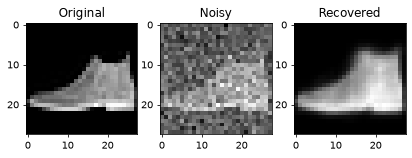

test MSE noisy vs clean    : 0.0400
test MSE recovered vs clean: 0.0224


In [42]:
f, a = plt.subplots(1, 3, figsize=(7, 2.6))

# 시각화를 위해 넘파이 행렬로 바꾼다
original_img = np.reshape(original_x.cpu().numpy(), (28, 28))
noisy_img = np.reshape(noisy_x.cpu().numpy(), (28, 28))
recovered_img = np.reshape(recovered_x.cpu().numpy(), (28, 28))

for ax, title, img in zip(a, ["Original", "Noisy", "Recovered"], [original_img, noisy_img, recovered_img]):
    ax.set_title(title)
    ax.imshow(img, cmap="gray")
plt.show()

# 한 장의 인상으로 끝내지 않고 테스트 데이터 전체의 평균 오차를 잰다
x_all = testset.data.view(-1, 28 * 28).type(torch.FloatTensor) / 255.0
noisy_all = add_noise(x_all)
with torch.no_grad():
    _, recovered_all = autoencoder(noisy_all.to(device))
print(f"test MSE noisy vs clean    : {F.mse_loss(noisy_all, x_all).item():.4f}")
print(f"test MSE recovered vs clean: {F.mse_loss(recovered_all.cpu(), x_all).item():.4f}")

잡음이 사라졌지만 복원 이미지는 뭉개집니다. 잠재 변수가 3개뿐이어서 무늬까지 담을 수 없기 때문입니다. "잡음을 없앴다"기보다 "그 옷과 비슷한 전형적인 이미지로 대체했다"에 가깝습니다. 더 또렷한 복원을 원하면 잠재 차원을 키워야 합니다. 숙제에서 해 봅니다.

## 2.4 오토인코더의 종류

아래 변형들을 작은 실험과 함께 봅니다. 공통으로 쓸 도구부터 만듭니다. 배치를 키우고 각 모델을 5 에폭만 학습하므로, 수치는 변형 사이의 대략적인 비교로만 읽으세요.

In [43]:
AE_BATCH = 256
AE_EPOCHS = 5
ae_loader = torch.utils.data.DataLoader(trainset, batch_size=AE_BATCH, shuffle=True, num_workers=NUM_WORKERS)
x_test_all = testset.data.view(-1, 28 * 28).type(torch.FloatTensor) / 255.0


def fit_ae(model: nn.Module, loader: torch.utils.data.DataLoader, epochs: int | None = None, l1: float = 0.0) -> None:
    """(잠재 변수, 복원)을 돌려주는 모델을 MSE로 학습합니다. l1은 잠재 변수에 거는 희소성 벌점입니다."""
    epochs = AE_EPOCHS if epochs is None else epochs
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    model.train()
    for _ in range(epochs):
        for x, _ in loader:
            x = x.view(x.size(0), -1).to(device)
            z, recon = model(x)
            loss = F.mse_loss(recon, x) + l1 * z.abs().mean()
            opt.zero_grad()
            loss.backward()
            opt.step()


def test_mse(model: nn.Module) -> float:
    """테스트 데이터 전체의 복원 MSE를 돌려줍니다."""
    model.eval()
    with torch.no_grad():
        _, recon = model(x_test_all.to(device))
    return F.mse_loss(recon.cpu(), x_test_all).item()


def count_params(model: nn.Module) -> int:
    """학습되는 파라미터의 수를 돌려줍니다."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Tied weight Auto Encoder

인코더의 가중치 행렬을 **전치(transpose)해서 디코더의 가중치로 그대로 사용**하는 구조입니다. 학습할 가중치가 절반으로 줍니다. 그래서 계산이 빠르고 과적합 위험이 적다는 설명을 흔히 보지만, 시간은 아래 실험처럼 줄지 않습니다. 과적합은 이 강에서 검증하지 않았습니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdBfh3m%2Fbtsl2IYkCHC%2FXsJij2oXygURbHbNgwRVK0%2Fimg.png))

tied autoencoder를 코드로 구현합니다. `nn.Linear`를 쓰지 않고 가중치 행렬을 직접 만든 뒤, 디코더에서 `W.t()`로 다시 씁니다. 편향(bias)은 인코더와 디코더가 따로 가집니다.

In [44]:
class TiedAutoencoder(nn.Module):
    """디코더가 인코더 가중치의 전치를 그대로 쓰는 오토인코더입니다."""

    def __init__(self, sizes: tuple[int, ...] = (28 * 28, 128, 64, 12, 3)) -> None:
        super().__init__()
        pairs = list(zip(sizes[:-1], sizes[1:]))
        self.weights = nn.ParameterList([nn.Parameter(torch.empty(out_dim, in_dim)) for in_dim, out_dim in pairs])
        self.enc_bias = nn.ParameterList([nn.Parameter(torch.zeros(out_dim)) for _, out_dim in pairs])
        self.dec_bias = nn.ParameterList([nn.Parameter(torch.zeros(in_dim)) for in_dim, _ in pairs])
        for w in self.weights:
            nn.init.xavier_uniform_(w)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        last = len(self.weights) - 1
        for i, (w, b) in enumerate(zip(self.weights, self.enc_bias)):
            x = F.linear(x, w, b)
            x = x if i == last else F.relu(x)
        z = x
        # 인코더의 마지막 층부터 거꾸로 전치 행렬을 곱한다
        for i in range(last, -1, -1):
            x = F.linear(x, self.weights[i].t(), self.dec_bias[i])
            x = torch.sigmoid(x) if i == 0 else F.relu(x)
        return z, x


set_seed()
plain_ae = Autoencoder().to(device)
tied_ae = TiedAutoencoder().to(device)
print("parameters  plain:", count_params(plain_ae), " tied:", count_params(tied_ae))
start = time.time()
fit_ae(plain_ae, ae_loader)
plain_time = time.time() - start
start = time.time()
fit_ae(tied_ae, ae_loader)
tied_time = time.time() - start
print(f"test MSE    plain: {test_mse(plain_ae):.4f} ({plain_time:.0f}s)   tied: {test_mse(tied_ae):.4f} ({tied_time:.0f}s)")

parameters  plain: 219891  tied: 110543


test MSE    plain: 0.0276 (7s)   tied: 0.0266 (7s)


파라미터는 거의 절반입니다. 복원 성능과 시간은 위 출력으로 확인하세요. 이 구조에서 시간은 크게 줄지 않습니다. 곱셈 횟수는 그대로이고 저장할 가중치만 줄기 때문입니다.

### Denoising Auto Encoder

2.3절에서 한 것이 바로 이 모델입니다. 무작위 가우시안 잡음을 입력에 더하고, 출력은 잡음 없는 이미지를 복원하도록 학습합니다. 일반 AE와 정답은 같고 입력만 다릅니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbrvovM%2Fbtsl0KW9mLE%2FLauEk2qZY1eAvFkmjFKIWk%2Fimg.png))

[Vincent 외(2008)](https://www.cs.toronto.edu/~larocheh/publications/icml-2008-denoising-autoencoders.pdf)는 이렇게 학습한 인코더의 필터가 일반 AE보다 에지나 획 같은 유용한 특징을 더 잘 찾는다고 보고했습니다.

### Sparse Auto Encoder

기본 구조와 달리 은닉층의 노드 수가 입력보다 **더 많습니다.** 제약이 없다면 입력을 그대로 복사해 버릴 수 있으니, 활성화되는 뉴런의 수를 제한합니다. 대부분의 값이 0인(sparse) 잠재 변수를 만들어 디코더가 모든 뉴런을 한꺼번에 참조하지 못하게 강제합니다.

방법은 두 가지가 대표적입니다. 손실에 L1 벌점을 더해 값을 0으로 밀거나, 큰 값 k개만 남기고 나머지를 0으로 보냅니다(k-sparse).

> **주의**: 활성화되는 뉴런이 학습 때마다 랜덤으로 바뀐다는 설명을 볼 수 있는데, 뉴런을 무작위로 끄는 것은 Dropout입니다. Sparse AE에서 어떤 뉴런이 켜질지는 **입력에 따라** 결정됩니다.

아래에서는 L1 방식을 씁니다.

In [45]:
class SparseAutoencoder(nn.Module):
    """은닉층이 입력보다 넓은 한 층짜리 오토인코더입니다."""

    def __init__(self, hidden: int = 1024) -> None:
        super().__init__()
        self.encoder = nn.Linear(28 * 28, hidden)
        self.decoder = nn.Linear(hidden, 28 * 28)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        z = F.relu(self.encoder(x))   # ReLU를 써야 값이 정확히 0이 될 수 있다
        return z, torch.sigmoid(self.decoder(z))


L1_WEIGHT = 0.05
ACTIVE_EPS = 1e-3   # 이 값보다 크면 켜진 뉴런으로 센다

for l1_value in [0.0, L1_WEIGHT]:
    set_seed()
    sparse_ae = SparseAutoencoder().to(device)
    fit_ae(sparse_ae, ae_loader, l1=l1_value)
    sparse_ae.eval()
    with torch.no_grad():
        z_sparse, _ = sparse_ae(x_test_all.to(device))
    active = (z_sparse > ACTIVE_EPS).float().mean().item()
    print(f"L1={l1_value:<5} test MSE={test_mse(sparse_ae):.4f}  active neurons per image={active * 100:.1f}% of 1024")

L1=0.0   test MSE=0.0050  active neurons per image=76.2% of 1024


L1=0.05  test MSE=0.0076  active neurons per image=13.6% of 1024


L1 벌점을 걸면 켜진 뉴런의 비율이 크게 줄고, 그 대가로 복원 오차가 조금 늘어납니다.

### 실습 2. k-sparse 활성화

각 행(이미지)에서 값이 가장 큰 `k`개만 남기고 나머지를 0으로 만드는 함수를 작성하세요. `torch.topk`와 `scatter_`를 쓰면 짧게 쓸 수 있습니다. 위 Sparse AE의 잠재 변수에 넣어 복원이 어떻게 변하는지도 확인해 보세요.

```python
def topk_sparsify(z: torch.Tensor, k: int) -> torch.Tensor:
    ...
```

In [46]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def topk_sparsify(z: torch.Tensor, k: int) -> torch.Tensor:
    """각 행에서 값이 큰 k개만 남기고 나머지를 0으로 만듭니다."""
    _, top_idx = z.topk(k, dim=1)
    mask = torch.zeros_like(z).scatter_(1, top_idx, 1.0)
    return z * mask


z_demo = torch.tensor([[0.1, 0.9, 0.5, 0.2], [3.0, 1.0, 2.0, 4.0]])
result = topk_sparsify(z_demo, 2)
assert torch.equal(result, torch.tensor([[0.0, 0.9, 0.5, 0.0], [3.0, 0.0, 0.0, 4.0]]))
assert (topk_sparsify(torch.rand(5, 100), 7) != 0).sum(dim=1).eq(7).all()

# 학습된 Sparse AE의 잠재 변수 중 50개만 남겨 복원해 본다
with torch.no_grad():
    z_full, _ = sparse_ae(x_test_all[:1000].to(device))
    recon_k = torch.sigmoid(sparse_ae.decoder(topk_sparsify(z_full, 50)))
print("MSE with top-50 activations:", F.mse_loss(recon_k.cpu(), x_test_all[:1000]).item())
```

</details>

### Stacked Auto Encoder (Deep AE)

층을 늘려 깊게 만들되, **한 층씩 분리해서 학습**하는 구조입니다.

층이 많으면 파라미터가 많아 학습이 어렵고, 차원을 한꺼번에 많이 줄이면 복원이 어렵습니다. 이 문제를 풀기 위해 한 층짜리 AE를 여러 개 쌓습니다. 이전 AE에서 찾은 잠재 벡터를 다음 AE의 입력으로 삼는 과정을 반복하고, 최종 Stacked AE에는 각 AE에서 학습된 가중치를 모아 그대로 씁니다. 이렇게 초기화한 뒤 전체를 역전파로 더 학습합니다.

(단계별 참고 그림: [구조](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fsk3fQ%2FbtqFANUD5Tc%2F8vXxtPWt8MeY26AXVJturk%2Fimg.png), [1단계](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbOmL4W%2FbtqFzAa4Vv6%2FSip5BzE4kkELtxlhj2mkf1%2Fimg.png), [2단계](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FkWOv4%2FbtqFzG9Z0zg%2Fv9UCtJqJ3lf382N48u9J7K%2Fimg.png), [3단계](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fkxz3G%2FbtqFApTZViQ%2FblXV1GKwwO95hvRufMqPG0%2Fimg.png), [결합](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FHd6aY%2FbtqFBL9GjcG%2Fs0hjmlbM705Ny2d2AVHkx1%2Fimg.png))

784→128→32로 줄이는 2단 구조로 직접 해 봅니다. 비교 대상은 같은 구조를 처음부터 통째로 학습한 모델입니다. 학습 에폭의 합을 같게 맞췄습니다.

In [47]:
class ShallowAE(nn.Module):
    """한 층짜리 오토인코더입니다. 픽셀을 복원할 때만 출력에 sigmoid를 씁니다."""

    def __init__(self, in_dim: int, hidden: int, pixel_output: bool) -> None:
        super().__init__()
        self.encoder = nn.Linear(in_dim, hidden)
        self.decoder = nn.Linear(hidden, in_dim)
        self.pixel_output = pixel_output

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        z = F.relu(self.encoder(x))
        recon = self.decoder(z)
        return z, torch.sigmoid(recon) if self.pixel_output else recon


class StackedAE(nn.Module):
    """미리 학습한 두 AE의 인코더와 디코더를 이어 붙입니다."""

    def __init__(self, ae1: ShallowAE, ae2: ShallowAE) -> None:
        super().__init__()
        self.ae1, self.ae2 = ae1, ae2

    def encode(self, x: torch.Tensor) -> torch.Tensor:
        return F.relu(self.ae2.encoder(F.relu(self.ae1.encoder(x))))

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        z = self.encode(x)
        h = F.relu(self.ae2.decoder(z))
        return z, torch.sigmoid(self.ae1.decoder(h))


set_seed()
# 1단계: 픽셀을 복원하는 AE를 학습한다
ae1 = ShallowAE(28 * 28, 128, pixel_output=True).to(device)
fit_ae(ae1, ae_loader)

# 2단계: 1단계 인코더의 출력을 데이터로 삼아 다음 AE를 학습한다
ae1.eval()
with torch.no_grad():
    features = torch.cat([F.relu(ae1.encoder(x.view(x.size(0), -1).to(device))).cpu() for x, _ in ae_loader])
feature_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(features, torch.zeros(len(features))), batch_size=AE_BATCH, shuffle=True
)
ae2 = ShallowAE(128, 32, pixel_output=False).to(device)
fit_ae(ae2, feature_loader)

stacked = StackedAE(ae1, ae2).to(device)
print(f"stacked, before fine-tuning   : test MSE {test_mse(stacked):.4f}")

# 3단계: 이어 붙인 전체를 역전파로 더 학습한다
fit_ae(stacked, ae_loader)
print(f"stacked, after fine-tuning    : test MSE {test_mse(stacked):.4f}")

# 비교: 같은 구조를 무작위 초기화에서 같은 총 에폭만큼 통째로 학습한다
set_seed()
end_to_end = StackedAE(ShallowAE(28 * 28, 128, True), ShallowAE(128, 32, False)).to(device)
fit_ae(end_to_end, ae_loader, epochs=3 * AE_EPOCHS)
print(f"end-to-end, same total epochs : test MSE {test_mse(end_to_end):.4f}")

stacked, before fine-tuning   : test MSE 0.0214


stacked, after fine-tuning    : test MSE 0.0135


end-to-end, same total epochs : test MSE 0.0129


층별 사전 학습은 ReLU와 Adam, BatchNorm이 없던 시절에 깊은 망을 학습시키려고 고안된 방법입니다. 지금은 이런 얕은 구조라면 위 결과처럼 처음부터 통째로 학습해도 충분한 경우가 많습니다. 개념으로 알아 두면 됩니다.

### 활용 1: 이상 탐지(Anomaly detection)

오토인코더의 대표적인 활용처입니다(Stacked AE의 활용으로 자주 소개되지만, 구조와 상관없이 쓸 수 있습니다). '이상'이라는 레이블이 없어도 **정상 데이터만으로** AE를 학습합니다. 그러면 정상은 잘 복원하지만 처음 보는 이상은 잘 복원하지 못하므로, **복원 오차가 큰 데이터를 이상치로 판단**합니다. ([제조 검사 그림](https://www.cognex.com/library/media/blogs/kr-deep-learning-research/autoencoder.jpg?la=ko-kr&hash=EAE518883DC308B296B9CE4F640A449960CFFF15&hash=EAE518883DC308B296B9CE4F640A449960CFFF15&sc_lang=ko-kr))

신발 3종(Sandal, Sneaker, Ankle boot)을 정상으로 두고, 옷과 가방을 이상으로 놓아 봅시다. 평가에는 **AUROC**를 씁니다. 이상 하나와 정상 하나를 무작위로 뽑았을 때 이상의 점수가 더 높을 확률로, 임계값을 정하지 않고 점수의 순서만 평가합니다. 0.5면 무작위, 1이면 완벽입니다.

AUROC = 0.972  (0.5 is random, 1.0 is perfect)


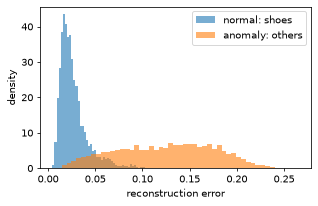

In [48]:
NORMAL_CLASSES = [5, 7, 9]   # Sandal, Sneaker, Ankle boot

normal_idx = torch.isin(trainset.targets, torch.tensor(NORMAL_CLASSES)).nonzero().squeeze().tolist()
normal_loader = torch.utils.data.DataLoader(
    torch.utils.data.Subset(trainset, normal_idx), batch_size=AE_BATCH, shuffle=True, num_workers=NUM_WORKERS
)
set_seed()
anomaly_ae = Autoencoder().to(device)
fit_ae(anomaly_ae, normal_loader, epochs=2 * AE_EPOCHS)

anomaly_ae.eval()
with torch.no_grad():
    _, recon = anomaly_ae(x_test_all.to(device))
# 이미지마다 복원 오차를 계산한다. 이것이 이상 점수다
scores = ((recon.cpu() - x_test_all) ** 2).mean(dim=1).numpy()
is_anomaly = ~np.isin(testset.targets.numpy(), NORMAL_CLASSES)
print(f"AUROC = {roc_auc_score(is_anomaly, scores):.3f}  (0.5 is random, 1.0 is perfect)")

plt.figure(figsize=(5, 3))
plt.hist(scores[~is_anomaly], bins=50, alpha=0.6, density=True, label="normal: shoes")
plt.hist(scores[is_anomaly], bins=50, alpha=0.6, density=True, label="anomaly: others")
plt.xlabel("reconstruction error")
plt.ylabel("density")
plt.legend()
plt.show()

정상(신발)의 오차는 낮은 쪽에 몰려 있지만 두 분포가 겹치는 구간도 있습니다. 또한 여기서 이상은 옷과 가방처럼 정상과 전혀 다른 물건입니다. 실제 불량은 정상과 훨씬 비슷한 경우가 많아 이렇게 쉽게 갈리지 않습니다.

### 활용 2: Stacked AE로 분류하기

AE의 인코더 부분까지만 자르고 그 위에 분류 모델을 올립니다. 특징 추출과 예측을 결합하는 것입니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FckYmb5%2Fbtsl5ko7wjj%2FH2TkwkznrKkFVhDBShcUM0%2Fimg.png))

순서는 이렇습니다. 학습된 인코더의 가중치를 고정(freeze)하고 위쪽 MLP만 학습한 뒤, 인코더의 뒷부분 가중치만 풀어서 함께 재학습(fine-tuning)합니다.

레이블이 많으면 이득이 작으니 **레이블이 500개뿐인 상황**을 가정합니다. 인코더는 레이블 없이 60,000장으로 이미 학습되어 있습니다. 같은 구조를 무작위 초기화에서 레이블 500개만으로 학습한 경우와 비교합니다.

In [49]:
LABELED = 500
HEAD_STEPS = 300
FINE_STEPS = 200

idx = torch.randperm(len(trainset), generator=torch.Generator().manual_seed(0))[:LABELED]
x_lab = trainset.data[idx].view(-1, 28 * 28).type(torch.FloatTensor).to(device) / 255.0
y_lab = trainset.targets[idx].to(device)
y_test_all = testset.targets.to(device)


def run_steps(params: list[nn.Parameter], forward_fn: Callable[[torch.Tensor], torch.Tensor], steps: int, lr: float) -> None:
    """레이블이 있는 500장 전체를 한 배치로 삼아 지정한 파라미터만 학습합니다."""
    opt = torch.optim.Adam(params, lr=lr)
    for _ in range(steps):
        loss = F.cross_entropy(forward_fn(x_lab), y_lab)
        opt.zero_grad()
        loss.backward()
        opt.step()


def accuracy(forward_fn: Callable[[torch.Tensor], torch.Tensor]) -> float:
    """테스트 데이터의 분류 정확도를 돌려줍니다."""
    with torch.no_grad():
        return (forward_fn(x_test_all.to(device)).argmax(1) == y_test_all).float().mean().item()


set_seed()
head = nn.Linear(32, 10).to(device)
stacked.eval()
forward_pre = lambda x: head(stacked.encode(x))

# 1단계: 인코더는 건드리지 않고 분류기만 학습한다
run_steps(list(head.parameters()), forward_pre, HEAD_STEPS, lr=1e-2)
print(f"pretrained encoder, frozen    : {accuracy(forward_pre):.3f}")

# 2단계: 인코더의 뒷부분(ae2.encoder)까지 풀어 작은 학습률로 함께 조정한다
run_steps(list(head.parameters()) + list(stacked.ae2.encoder.parameters()), forward_pre, FINE_STEPS, lr=1e-3)
print(f"after fine-tuning             : {accuracy(forward_pre):.3f}")

# 비교: 무작위 초기화에서 레이블 500개만으로 같은 횟수 학습한다
set_seed()
scratch = nn.Sequential(nn.Linear(28 * 28, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 10)).to(device)
run_steps(list(scratch.parameters()), scratch, HEAD_STEPS + FINE_STEPS, lr=1e-2)
print(f"random init, labels only      : {accuracy(scratch):.3f}")

pretrained encoder, frozen    : 0.765
after fine-tuning             : 0.766


random init, labels only      : 0.765


정직하게 읽어 봅시다. 레이블 없이 학습한 특징 위에 분류기만 올려도(`frozen`) 쓸 만한 정확도가 나옵니다. 그러나 **이 실험에서는 사전 학습이 무작위 초기화보다 뚜렷이 낫지 않습니다.** 층별 사전 학습은 작은 MLP와 쉬운 데이터에서는 이득이 작습니다. 사전 학습이 이기려면 레이블이 더 적거나, 데이터가 더 복잡하거나, 인코더가 더 강력해야 합니다. 5.3절에서 볼 SAM의 인코더가 그런 예입니다.

### Convolution Auto Encoder

기본 구조는 같지만 CNN처럼 합성곱 필터를 씁니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FduxCl7%2Fbtrul2OkluL%2FNPoba7cheVK4y7q89MsMk1%2Fimg.png))

인코더는 합성곱과 풀링으로 크기를 줄이고, 디코더는 **전치 합성곱**(transposed convolution)으로 크기를 키웁니다. ([전치 합성곱 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F6JwuV%2FbtrubMlZmrH%2F2xHxTVDvr6MHXKdWzS64jK%2Fimg.png))

전치 합성곱은 합성곱의 크기 변화를 거꾸로 하는 연산입니다. 입력 한 칸이 커널 모양으로 넓게 퍼져 출력에 더해집니다. 출력 크기는 `(입력-1)×stride - 2×padding + (kernel-1) + output_padding + 1` 입니다. 직접 확인해 봅시다.

In [50]:
kernel_demo = nn.ConvTranspose2d(1, 1, kernel_size=2, stride=2, bias=False)
nn.init.ones_(kernel_demo.weight)
small = torch.tensor([[[[1.0, 2.0], [3.0, 4.0]]]])
print(kernel_demo(small).detach().squeeze())

# 뒤에서 쓸 설정이 정확히 2배로 키우는지 확인한다
up = nn.ConvTranspose2d(8, 4, kernel_size=3, stride=2, padding=1, output_padding=1)
print("input 7x7 ->", up(torch.zeros(1, 8, 7, 7)).shape[2:])

tensor([[1., 1., 2., 2.],
        [1., 1., 2., 2.],
        [3., 3., 4., 4.],
        [3., 3., 4., 4.]])
input 7x7 -> torch.Size([14, 14])


### Convolution Auto Encoder를 구현해 보자

테스트 데이터셋도 함께 만듭니다. 합성곱에 특별한 배치 크기가 필요한 것은 아닙니다. 그냥 다른 값으로 학습해 보는 것입니다.

In [51]:
BATCH_SIZE = 32
train_loader = torch.utils.data.DataLoader(
    dataset=trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
# 테스트 데이터는 섞을 이유가 없다. 순서가 고정되어야 결과를 재현할 수 있다
test_loader = torch.utils.data.DataLoader(
    dataset=testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)

Convolution Auto Encoder 모듈을 정의합니다.

> **흔한 실수 두 가지**
> 1. `pre_encoded.view(BATCH_SIZE, -1)`처럼 배치 크기를 고정하면 마지막 배치(테스트 10000장을 32로 나누면 16장 남음)의 모양이 **에러 없이 잘못** 만들어집니다. `x.size(0)`을 쓰세요.
> 2. 마지막 활성화 함수가 `ReLU`면 상한이 없고 음수로 들어간 픽셀의 기울기가 0이 됩니다. 픽셀 범위에 맞는 `Sigmoid`를 쓰세요.

In [52]:
class ConvolutionAutoencoder(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),                    # batch x 16 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.Conv2d(16, 32, 3, padding=1),                   # batch x 32 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.Conv2d(32, 64, 3, padding=1),                   # batch x 64 x 28 x 28
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2, 2),                                # batch x 64 x 14 x 14
            nn.Conv2d(64, 128, 3, padding=1),                  # batch x 128 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2, 2),                                # batch x 128 x 7 x 7
            nn.Conv2d(128, 256, 3, padding=1),                 # batch x 256 x 7 x 7
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 3, 2, 1, 1),          # batch x 128 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.ConvTranspose2d(128, 64, 3, 1, 1),              # batch x 64 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.ConvTranspose2d(64, 16, 3, 1, 1),               # batch x 16 x 14 x 14
            nn.ReLU(),
            nn.BatchNorm2d(16),
            nn.ConvTranspose2d(16, 1, 3, 2, 1, 1),             # batch x 1 x 28 x 28
            nn.Sigmoid(),
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        pre_encoded = self.encoder(x)
        encoded = pre_encoded.view(x.size(0), -1)
        decoded = self.decoder(pre_encoded)
        return encoded, decoded

In [53]:
set_seed()
cautoencoder = ConvolutionAutoencoder().to(device)

optimizer = torch.optim.Adam(cautoencoder.parameters(), lr=0.005)
criterion = nn.MSELoss()

In [54]:
def train_conv_ae(model: nn.Module, opt: torch.optim.Optimizer, epochs: int) -> None:
    """합성곱 오토인코더를 학습합니다. 입력과 정답이 모두 같은 이미지입니다."""
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            _, decoded = model(x)
            loss = criterion(decoded, x)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        print(f"[Epoch {epoch}] loss: {total / len(train_loader):.5f}")


train_conv_ae(cautoencoder, optimizer, EPOCH)

[Epoch 1] loss: 0.00631


[Epoch 2] loss: 0.00200


[Epoch 3] loss: 0.00152


[Epoch 4] loss: 0.00125


[Epoch 5] loss: 0.00107


[Epoch 6] loss: 0.00092


[Epoch 7] loss: 0.00082


[Epoch 8] loss: 0.00075


[Epoch 9] loss: 0.00068


[Epoch 10] loss: 0.00063


torch.Size([32, 28, 28])


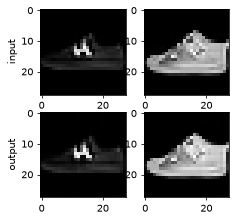

In [55]:
# 학습 데이터의 한 배치로 확인한다
cautoencoder.eval()
x, _ = next(iter(train_loader))
x = x.to(device)
with torch.no_grad():
    _, decoded = cautoencoder(x)
out_img = torch.squeeze(decoded.cpu())
print(out_img.size())

fig, axes = plt.subplots(2, 2, figsize=(3.5, 3.5))
for i in range(2):
    axes[0][i].imshow(torch.squeeze(x[i]).cpu().numpy(), cmap="gray")
    axes[1][i].imshow(out_img[i].numpy(), cmap="gray")
axes[0][0].set_ylabel("input")
axes[1][0].set_ylabel("output")
plt.show()

테스트 데이터셋에서도 봅시다. 평가할 때는 BatchNorm이 학습 때 모은 통계를 쓰도록 `eval()`을 불러야 합니다(빠뜨리기 쉽습니다).

In [56]:
def conv_test_mse(model: nn.Module) -> tuple[float, torch.Tensor, torch.Tensor]:
    """테스트 데이터 전체의 평균 MSE와 첫 배치의 입력, 복원을 돌려줍니다."""
    model.eval()
    total, first_x, first_out = 0.0, None, None
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            _, decoded = model(x)
            total += F.mse_loss(decoded, x, reduction="sum").item()
            if first_x is None:
                first_x, first_out = x.cpu(), decoded.cpu()
    return total / (len(testset) * 28 * 28), first_x, first_out


conv_mse, first_x, first_out = conv_test_mse(cautoencoder)
print(f"test MSE: {conv_mse:.5f}")

test MSE: 0.00065


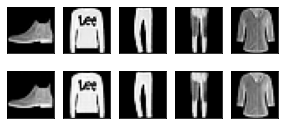

In [57]:
def show_rows(top: torch.Tensor, bottom: torch.Tensor, n: int = 5) -> None:
    """위 행에 입력, 아래 행에 복원을 그립니다."""
    fig, axes = plt.subplots(2, n, figsize=(n, 2.2))
    for i in range(n):
        axes[0][i].imshow(top[i].squeeze().numpy(), cmap="gray")
        axes[1][i].imshow(bottom[i].squeeze().numpy(), cmap="gray")
    for ax in axes.ravel():
        ax.set_xticks(())
        ax.set_yticks(())
    plt.show()


show_rows(first_x, first_out)

복원이 거의 완벽합니다. 그런데 이 모델이 **데이터를 압축하고 있을까요?**

<details><summary>답</summary>

아닙니다. 인코더의 출력은 256×7×7 = **12,544차원**으로, 입력 784차원의 16배입니다. 공간을 줄였지만 채널을 그보다 더 늘렸습니다. 병목이 없으니 복원이 쉬운 것은 당연하고, 이 모델의 잠재 표현은 차원 축소가 아닙니다.

</details>

진짜 병목을 넣으면 어떻게 될까요? 잠재 표현을 4×7×7 = 196차원(입력의 1/4)으로 줄인 모델을 같은 조건으로 학습해 비교합니다.

[Epoch 1] loss: 0.00837


[Epoch 2] loss: 0.00510


[Epoch 3] loss: 0.00474


[Epoch 4] loss: 0.00453


[Epoch 5] loss: 0.00440


[Epoch 6] loss: 0.00428


[Epoch 7] loss: 0.00422


[Epoch 8] loss: 0.00413


[Epoch 9] loss: 0.00411


[Epoch 10] loss: 0.00402


no real bottleneck  latent=12544  test MSE=0.00065
real bottleneck     latent=  196  test MSE=0.00389


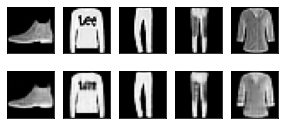

In [58]:
class BottleneckConvAE(nn.Module):
    """잠재 표현이 입력보다 실제로 작은 합성곱 오토인코더입니다."""

    def __init__(self, latent_channels: int = 4) -> None:
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(32), nn.MaxPool2d(2, 2),   # 32 x 14 x 14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(64), nn.MaxPool2d(2, 2),  # 64 x 7 x 7
            nn.Conv2d(64, latent_channels, 1),                                                   # 4 x 7 x 7
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(latent_channels, 64, 1), nn.ReLU(), nn.BatchNorm2d(64),
            nn.ConvTranspose2d(64, 32, 3, 2, 1, 1), nn.ReLU(), nn.BatchNorm2d(32),               # 32 x 14 x 14
            nn.ConvTranspose2d(32, 1, 3, 2, 1, 1), nn.Sigmoid(),                                 # 1 x 28 x 28
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        z = self.encoder(x)
        return z.view(x.size(0), -1), self.decoder(z)


set_seed()
bottleneck_ae = BottleneckConvAE().to(device)
train_conv_ae(bottleneck_ae, torch.optim.Adam(bottleneck_ae.parameters(), lr=0.005), EPOCH)
bottleneck_mse, first_x, bottleneck_out = conv_test_mse(bottleneck_ae)

with torch.no_grad():
    latent_dim = cautoencoder(first_x[:1].to(device))[0].shape[1], bottleneck_ae(first_x[:1].to(device))[0].shape[1]
print(f"no real bottleneck  latent={latent_dim[0]:5d}  test MSE={conv_mse:.5f}")
print(f"real bottleneck     latent={latent_dim[1]:5d}  test MSE={bottleneck_mse:.5f}")
show_rows(first_x, bottleneck_out)

병목을 넣으면 테스트 MSE가 몇 배로 커지고 글자 같은 세부가 흐려집니다. 그래도 입력의 4분의 1 크기로 형태를 유지합니다. 이것이 진짜 압축의 대가입니다.

---
# 3교시. Variational AutoEncoder

## 3.1 VAE란

**VAE**(Variational AutoEncoder)는 생성 모델(Generative model)의 일종입니다. 이름은 오토인코더이고 구조도 닮았지만 목적이 완전히 다른 모델입니다.

> **생성 모델이란?** 학습한 데이터를 바탕으로 실제로 있을 것 같은 데이터를 스스로 생성하는 모델입니다. 목적은 학습 데이터가 놓여 있는 데이터 분포를 찾는 것입니다.

AE는 데이터의 특징을 추출하는 것이 목적이어서 **인코더**가 주인공이고, VAE는 새로운 데이터를 생성하는 것이 목적이어서 **디코더**가 주인공입니다.

VAE의 구조는 다음과 같습니다. AE와 달리 인코더가 잠재 벡터 하나가 아니라 **분포**(평균과 분산)를 내놓고, 거기서 샘플을 뽑아 디코더에 넣습니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fb30Uzl%2FbtrxY4wKngj%2FSucVwitDrRtQvi1xTHdrR0%2Fimg.png))

```
입력 x → [인코더] → μ, log σ² → z = μ + σ·ε (ε ~ N(0, I)) → [디코더] → 복원 x'
```

- Encoder: 입력을 잠재 공간(latent space)의 분포로 변환합니다.
- Decoder: 잠재 변수를 입력 공간으로 변환합니다.

## 3.2 VAE를 이해하기 위한 수식

> **표기**: VAE 논문의 표기를 따릅니다. **인코더는 $q_\phi(z|x)$, 디코더는 $p_\theta(x|z)$** 입니다.

생성하고자 하는 데이터, 우리가 가지고 있는 학습 데이터가 $x$입니다. 파라미터 $\theta$가 주어졌을 때 데이터 $x$가 나올 확률 $p_\theta(x)$가 높을수록 좋은 모델입니다.

$x$를 생성하는 데 필요한 잠재 변수가 $z$입니다. $x$를 잘 설명하는 특징을 $z$에 담고, 이 $z$로부터 $x$와 비슷하지만 새로운 데이터를 만드는 것이 목표입니다.

$x$의 주변확률은 다음과 같습니다.

$$p(x) = \int p(x,z)\,dz$$

> **참고: 확률의 곱셈 규칙** $\quad p(x|z) = \dfrac{p(x,z)}{p(z)}$

이를 넣으면 다음을 얻습니다.

$$p(x) = \int p(x,z)\,dz = \int p(z)\,p(x|z)\,dz$$

$p(z)$는 우리가 정규분포 $N(0, I)$로 **정해 둔 값**(사전 분포)입니다. 문제는 이 적분입니다. $z$의 경우의 수가 무수히 많아 계산할 수 없고, 무작위로 뽑은 $z$는 대부분 $x$와 무관해서 샘플로 근사하기도 어렵습니다.

> **흔한 오해**: "$P(z)$를 알 수 없으니 $P(z|x)$를 구하자"는 설명을 볼 수 있습니다. 정확히는 $p(z)$는 우리가 정한 것이고, 계산할 수 없는 것은 $p(x)$와 사후 분포 $p(z|x)$입니다. 베이즈 정리에 따라 $p(z|x)=p(x|z)p(z)/p(x)$이므로 $p(x)$를 모르면 $p(z|x)$도 알 수 없습니다.

→ 가지고 있는 $x$를 보고, 그 $x$를 만들었을 법한 $z$만 뽑으면 어떨까요? 그 분포가 $p(z|x)$입니다. 이상적인 $p(z|x)$는 알 수 없지만, 다루기 쉬운 정규분포 $Q(z)$로 근사할 수 있습니다.

$$p(z|x) \approx Q(z)$$

**변분 추론(Variational Inference)**: 복잡한 분포를 간단한 분포로 근사하는 방법입니다.

$Q(z)$를 $p(z|x)$에 맞추기 위해 쿨백-라이블러 발산(Kullback-Leibler divergence, KLD)을 씁니다.

> **KL 발산**: 두 분포의 차이를 재는 지표입니다. 두 분포가 비슷할수록 작고, 같으면 0이며, 음수가 되지 않습니다.
>
> $D_{KL}(P_1\|P_2) = \sum P_1 \log \frac{P_1}{P_2}$

$$\begin{aligned}
D_{KL}(Q(z)\|p(z|x))
&= \sum_{z} Q(z)\log \frac{Q(z)}{p(z|x)}\\
&= \sum_{z} Q(z)\log \frac{Q(z)\,p(x)}{p(z,x)}\\
&= \sum_{z} Q(z)\log \frac{Q(z)}{p(z,x)}+\log p(x)\sum_{z}Q(z)\\
&= \sum_{z} Q(z)\log \frac{Q(z)}{p(x|z)\,p(z)}+\log p(x)\\
&= \sum_{z} Q(z)\log \frac{Q(z)}{p(z)}-\sum_{z}Q(z)\log p(x|z)+\log p(x)
\end{aligned}$$

> **기대값의 정의**: 확률변수의 함수 $g(x)$에 대해 $\mathbb{E}[g(x)] = \sum_{x} g(x) f(x)$

$$= D_{KL}(Q(z)\|p(z))-\mathbb{E}_{z\sim Q(z)}[\log p(x|z)]+\log p(x)$$

$\log p(x)$에 대해 정리합니다.

$$\log p(x) = D_{KL}(Q(z)\|p(z|x)) \underbrace{- D_{KL}(Q(z)\|p(z))+\mathbb{E}_{z\sim Q(z)}[\log p(x|z)]}_{\text{ELBO}}$$

$$\text{ELBO} = -D_{KL}(Q(z)\|p(z))+\mathbb{E}_{z\sim Q(z)}[\log p(x|z)]$$

KL 발산은 음수가 될 수 없으므로 $\log p(x) \ge \text{ELBO}$ 입니다. 그래서 **Evidence Lower BOund**(증거의 하한)입니다. ELBO를 키우는 일에는 두 가지 효과가 있습니다. 인코더($\phi$)에 대해 키우면 $\log p_\theta(x)$는 그대로이므로 계산할 수 없던 $D_{KL}(Q\|p(z|x))$가 줄어듭니다(근사가 좋아집니다). 디코더($\theta$)에 대해 키우면 하한과 함께 $\log p_\theta(x)$ 자체를 끌어올립니다(모델이 좋아집니다).

이어지는 생각을 요약하면 다음과 같습니다. $p(x)$를 직접 계산할 수 없다 → $p(z|x)$를 $Q$로 근사하자 → 디코더를 고정하면 그 차이를 줄이는 것이 곧 ELBO를 키우는 것이고, 디코더까지 함께 학습하면 $\log p_\theta(x)$도 함께 올라간다.

유도가 맞는지 숫자로 검산합시다. $z$가 3가지 값만 갖는 작은 모델이면 $\log p(x)$를 정확히 계산할 수 있습니다.

In [59]:
# z가 세 값만 갖는 작은 모델. 적분이 합으로 바뀌므로 모든 값을 정확히 계산할 수 있다
p_z = np.array([0.5, 0.3, 0.2])          # 사전 분포 p(z)
p_x_given_z = np.array([0.9, 0.2, 0.05])  # 관측한 x에 대한 p(x|z)
q_z = np.array([0.6, 0.3, 0.1])          # 임의로 고른 근사 분포 Q(z)


def kl(p: np.ndarray, q: np.ndarray) -> float:
    """이산 분포의 KL 발산을 계산합니다."""
    return float(np.sum(p * np.log(p / q)))


p_x = np.sum(p_z * p_x_given_z)                  # p(x) = Σ p(z) p(x|z)
posterior = p_z * p_x_given_z / p_x              # p(z|x)
elbo = -kl(q_z, p_z) + np.sum(q_z * np.log(p_x_given_z))

print(f"log p(x)             = {np.log(p_x):.6f}")
print(f"ELBO                 = {elbo:.6f}")
print(f"KL(Q || p(z|x))      = {kl(q_z, posterior):.6f}")
print(f"ELBO + KL(Q||p(z|x)) = {elbo + kl(q_z, posterior):.6f}")
assert np.isclose(np.log(p_x), elbo + kl(q_z, posterior))
assert elbo <= np.log(p_x)

# Q가 진짜 사후 분포와 같으면 하한이 딱 맞아떨어진다
elbo_best = -kl(posterior, p_z) + np.sum(posterior * np.log(p_x_given_z))
print(f"ELBO when Q = p(z|x) = {elbo_best:.6f}")
assert np.isclose(np.log(p_x), elbo_best)

log p(x)             = -0.653926
ELBO                 = -0.885699
KL(Q || p(z|x))      = 0.231773
ELBO + KL(Q||p(z|x)) = -0.653926
ELBO when Q = p(z|x) = -0.653926


## 3.3 ELBO와 손실 함수

$Q$를 데이터마다 따로 정하는 대신, 입력 $x$를 받아 분포를 내놓는 신경망(인코더)으로 만듭니다. 즉 $Q(z)$가 $q_\phi(z|x)$가 됩니다.

$$\text{ELBO} = -D_{KL}(q_\phi(z|x)\|p(z))+\mathbb{E}_{z\sim q_\phi(z|x)}[\log p_\theta(x|z)]$$

데이터 한 개 $x_i$에 대해 씁니다.

$$\text{ELBO}_i = -D_{KL}(q_\phi(z|x_i)\|p(z))+\mathbb{E}_{z\sim q_\phi(z|x_i)}[\log p_\theta(x_i|z)]$$

ELBO는 키워야 하고 손실은 줄여야 하므로 부호를 뒤집습니다. 이것이 **최종 손실 함수**입니다.

$$\text{loss}_i(\theta,\phi) = -\text{ELBO}_i = \underbrace{D_{KL}(q_\phi(z|x_i)\|p(z))}_{\text{규제 항}}\ \underbrace{-\ \mathbb{E}_{z\sim q_\phi(z|x_i)}[\log p_\theta(x_i|z)]}_{\text{복원 항}}$$

- **규제 항(Regularization term)**: 인코더가 내놓는 분포가 사전 분포 $p(z)$에서 멀어지지 않게 합니다. 이 항 덕분에 잠재 공간이 $N(0,I)$ 근처에 빈틈없이 모이고, 나중에 $N(0,I)$에서 뽑은 $z$로 생성할 수 있습니다.
- **복원 항(Reconstruction term)**: $z$로 $x_i$를 잘 복원해야 한다는 뜻입니다. 인코더와 디코더 모두 이 항으로 학습됩니다.

두 항은 서로 줄다리기를 합니다. 복원을 잘하려면 데이터마다 $z$를 뚜렷이 구별해야 하는데(KL 증가), KL을 줄이면 모든 $x$의 $z$가 같은 분포로 뭉칩니다(복원 악화).

## 3.4 Reparameterization Trick

이 손실을 학습에 쓰려면 어떤 가정이 들어가고 코드로 어떻게 풀어 쓰는지 알아봅시다.

> **다변량 정규분포** $N(\mu,\Sigma)$: $\mu$는 $n\times 1$ 행렬, $\Sigma$는 $n\times n$ 행렬입니다.

### 규제 항(Regularization term)

$$D_{KL}(q_\phi(z|x_i)\|p(z))$$

인코더가 내놓은 평균과 분산을 가진 정규분포 $q_\phi(z|x_i)$를, 평균 0, 분산 1인 정규분포 $p(z)$에 가깝게 합니다.

두 다변량 정규분포 사이의 KL 발산은 식이 알려져 있습니다([수식 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fd5UuY3%2FbtqZ2bbtPbF%2FdgvZ9xnlUyXgMhg9KqU7k0%2Fimg.png)). 공분산을 대각 행렬로 가정하고 $p(z)=N(0,I)$를 넣으면 간단해집니다.

$$D_{KL} = -\frac{1}{2}\sum_j\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)$$

샘플링 없이 바로 계산됩니다. 이 식이 맞는지 세 가지 방법으로 검산합니다.

In [60]:
set_seed()
mu_check = torch.tensor([0.5, -1.0, 2.0])
logvar_check = torch.tensor([0.0, -0.5, 1.0])
sigma_check = torch.exp(0.5 * logvar_check)

# 1) 코드에서 쓸 닫힌 식
kld_formula = -0.5 * torch.sum(1 + logvar_check - mu_check.pow(2) - logvar_check.exp())

# 2) PyTorch 분포 라이브러리의 계산
q_dist = torch.distributions.Normal(mu_check, sigma_check)
p_dist = torch.distributions.Normal(torch.zeros(3), torch.ones(3))
kld_library = torch.distributions.kl_divergence(q_dist, p_dist).sum()

# 3) 정의대로 샘플을 뽑아 평균 내기(Monte Carlo): E_q[log q(z) - log p(z)]
samples = q_dist.sample((200000,))
kld_monte_carlo = (q_dist.log_prob(samples) - p_dist.log_prob(samples)).sum(dim=1).mean()

print(f"closed form : {kld_formula.item():.4f}")
print(f"library     : {kld_library.item():.4f}")
print(f"Monte Carlo : {kld_monte_carlo.item():.4f}")
assert torch.isclose(kld_formula, kld_library)
assert abs(kld_formula - kld_monte_carlo) < 0.05

closed form : 3.0374
library     : 3.0374
Monte Carlo : 3.0384


### 복원 항(Reconstruction term)

$$-\mathbb{E}_{z\sim q_\phi(z|x_i)}[\log p_\theta(x_i|z)]$$

기대값과 적분의 정의에 따라 다시 쓸 수 있습니다. 음의 부호를 빠뜨리지 않도록 주의하세요.

$$= -\int q_\phi(z|x_i)\log p_\theta(x_i|z)\,dz$$

> **Monte Carlo Estimation**: 무작위로 많은 데이터를 뽑아 함수의 값을 수치적으로 근사하는 방법입니다. 모든 $z$를 고려하는 대신 충분히 많은 $z_1, z_2, \dots, z_n$을 뽑아 평균을 내면 전체 $z$의 효과를 낼 수 있습니다.

$$\approx -\frac{1}{n}\sum_{j=1}^n \log p_\theta(x_i|z_j)$$

VAE는 $n$개를 뽑지 않고 $z$를 **하나만** 뽑아 씁니다. 추정값에 잡음이 있지만 미니배치로 평균을 내고 에폭을 반복하므로 충분히 학습이 됩니다. VAE 논문도 배치가 충분히 크면 $n=1$이면 된다고 설명합니다.

$$\approx -\log p_\theta (x_i|z)$$

### 미분할 수 없는 샘플링을 어떻게 할까

이제 문제가 하나 남습니다. **$z$를 분포에서 샘플링하는 연산은 역전파가 통과할 수 없습니다.** 난수를 뽑는 과정에는 $\mu$, $\sigma$에 대한 기울기가 정의되지 않기 때문입니다. 인코더까지 기울기를 보낼 길이 끊어집니다.

해결책이 **재매개변수화**(reparameterization)입니다. 평균 0, 분산 1인 정규분포에서 잡음 $\varepsilon$을 먼저 뽑고, 인코더가 구한 평균과 표준편차로 더하고 곱합니다.

$$z = \mu + \varepsilon \cdot \sigma,\qquad \varepsilon \sim N(0, I)$$

$z$의 분포는 그대로 $N(\mu, \sigma^2)$이지만, 무작위성은 $\varepsilon$으로 밀려났습니다. $\varepsilon$을 상수처럼 보면 $z$는 $\mu$, $\sigma$의 평범한 수식이므로 미분할 수 있습니다. $\partial z/\partial\mu = 1$, $\partial z/\partial\sigma = \varepsilon$입니다. 직접 확인합니다.

In [61]:
mu_demo = torch.tensor(0.5, requires_grad=True)
sigma_demo = torch.tensor(1.5, requires_grad=True)

# 그냥 샘플링하면 계산 그래프가 끊어진다
z_plain = torch.distributions.Normal(mu_demo, sigma_demo).sample()
print("sample(): requires_grad =", z_plain.requires_grad)

# 재매개변수화: 잡음을 먼저 뽑고 수식으로 z를 만든다
set_seed()
eps = torch.randn(())
z_reparam = mu_demo + eps * sigma_demo
z_reparam.backward()
print("reparam : requires_grad =", z_reparam.requires_grad)
print(f"dz/dmu    = {mu_demo.grad.item():.4f} (expected 1)")
print(f"dz/dsigma = {sigma_demo.grad.item():.4f} (expected eps = {eps.item():.4f})")
assert mu_demo.grad == 1 and torch.isclose(sigma_demo.grad, eps)

# 뽑은 z의 분포가 정말 N(mu, sigma^2)인지 확인한다
with torch.no_grad():
    many = mu_demo + torch.randn(200000) * sigma_demo
print(f"sample mean = {many.mean().item():.3f} (expected 0.5), std = {many.std().item():.3f} (expected 1.5)")

sample(): requires_grad = False
reparam : requires_grad = True
dz/dmu    = 1.0000 (expected 1)
dz/dsigma = -1.1257 (expected eps = -1.1257)
sample mean = 0.500 (expected 0.5), std = 1.501 (expected 1.5)


### 디코더의 분포와 BCE

$z$를 정의했으니 $\log p_\theta(x_i|z)$를 계산해야 합니다. 디코더 출력 $x'_i$를 픽셀별 베르누이 분포의 확률로 가정합니다.

> **베르누이 분포** $\quad P(X=x) = p^x (1-p)^{1-x}$

$$\log p_\theta(x_i|z) = \log \left[(x'_i)^{x_i}(1-x'_i)^{1-x_i}\right] = x_i\log x'_i+(1-x_i)\log(1-x'_i)$$

> **Binary Cross Entropy** $\quad \text{BCE}(\hat y,y) = -\left(y \log \hat y + (1-y) \log(1-\hat y)\right)$

부호만 다르고 같은 식입니다. 즉 **복원 항은 BCE입니다.** 픽셀마다 독립으로 가정했으므로 로그 확률은 픽셀에 대해 **더해야** 합니다. 그래서 코드는 `F.binary_cross_entropy(..., reduction="sum")`을 씁니다. 평균(`mean`)을 쓰면 복원 항만 784분의 1로 작아져 KL 항과의 균형이 무너집니다. 뒤에서 실험으로 보겠습니다.

수식과 함수가 같은지 확인합니다. 그리고 한 가지 주의할 점이 있습니다. MNIST 픽셀은 0과 1만 있는 것이 아니라 그 사이 회색 값도 있습니다. 엄밀히 베르누이 가정에 맞지 않고, 이때 BCE는 **완벽한 복원에서도 0이 되지 않습니다.** 관행적으로 널리 쓰는 근사입니다.

In [62]:
x_pix = torch.tensor([0.0, 1.0, 1.0, 0.0])
x_hat = torch.tensor([0.1, 0.8, 0.6, 0.3])
manual = -(x_pix * x_hat.log() + (1 - x_pix) * (1 - x_hat).log()).sum()
library = F.binary_cross_entropy(x_hat, x_pix, reduction="sum")
print(f"-log Bernoulli = {manual.item():.4f},  F.binary_cross_entropy = {library.item():.4f}")
assert torch.isclose(manual, library)

gray = torch.tensor([0.5, 0.2])
print(f"BCE for a perfect reconstruction of gray pixels: {F.binary_cross_entropy(gray, gray, reduction='sum').item():.4f}")

-log Bernoulli = 1.1960,  F.binary_cross_entropy = 1.1960
BCE for a perfect reconstruction of gray pixels: 1.1935


## 3.5 VAE를 파이토치로 구현하기

[참고 글](https://cumulu-s.tistory.com/25)을 바탕으로 구현합니다. 이번에는 텐서보드로 손실도 기록합니다. 저장된 노트북에서는 텐서보드 화면을 볼 수 없으므로 같은 내용을 그래프로도 그립니다.

In [63]:
# 코랩 서버는 UTC로 동작하므로 한국 시간을 명시해 폴더 이름을 만든다
KST = datetime.timezone(datetime.timedelta(hours=9))
current_time = datetime.datetime.now(KST).strftime("%Y-%m-%d-%H-%M")

# 텐서보드는 실행마다 결과를 나눠 저장해야 하므로 시각별 폴더를 만든다
saved_loc = os.path.join("runs", "VAE_Result", current_time)
os.makedirs(saved_loc, exist_ok=True)
print("저장 위치:", saved_loc)

writer = SummaryWriter(saved_loc)   # 텐서보드 기록을 쓰는 객체
EPOCHS = 50
BATCH_SIZE = 200

저장 위치: runs/VAE_Result/2026-11-05-07-20


MNIST 데이터를 불러옵니다.

In [64]:
transformer = transforms.Compose([transforms.ToTensor()])

trainset = torchvision.datasets.MNIST(root=DATA_ROOT, train=True, download=True, transform=transformer)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)

testset = torchvision.datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=transformer)
testloader = torch.utils.data.DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

8개의 이미지만 출력해 봅니다.

torch.Size([200, 1, 28, 28])


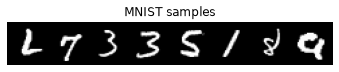

In [65]:
def imshow_grid(img: torch.Tensor, title: str = "") -> None:
    """이미지 묶음을 격자로 그립니다."""
    grid = torchvision.utils.make_grid(img.cpu())
    plt.figure(figsize=(6, 1 + grid.shape[1] / 60))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()


sample, label = next(iter(trainloader))
print(sample.shape)
imshow_grid(sample[:8], "MNIST samples")

핵심이 되는 VAE 모델 코드입니다.

**encode**

인코더 $q_\phi(z|x)$는 이미지를 받아서 평균과 분산을 출력합니다. fc1 → relu → fc2 → relu 한 뒤, 잠재 공간 차원만큼 평균(`fc31`)과 로그 분산(`fc32`)을 출력합니다.

**reparameterize**

$\mu$와 분산이 주어졌을 때 잠재 변수 z를 만드는 함수입니다.

왜 분산이 아니라 **로그 분산**(`logvar`)일까요? 표준편차는 음수가 될 수 없는데 선형층의 출력은 음수도 나옵니다. `fc32`의 출력을 $\log\sigma^2$으로 해석하면 어떤 실수가 나와도 $\sigma$가 양수가 됩니다.

$$\sigma = e^{\log\sigma} = e^{\frac{2\log\sigma}{2}} = e^{\frac{\log \sigma^2}{2}} = e^{\frac{\text{logvar}}{2}}$$

```python
std = torch.exp(0.5 * logvar)
eps = torch.randn_like(std)     # 평균 0, 분산 1인 정규분포에서 같은 모양의 잡음을 뽑는다
z = mu + std * eps              # 3.4절의 z = mu + eps * sigma
```

**decode**

z를 받아 fc4 → relu → fc5 → relu → fc6 → sigmoid를 거쳐, 이미지와 같은 차원의 0~1 사이 값을 출력합니다. 이 값이 베르누이 분포의 확률 $x'$입니다.

In [66]:
class VAE(nn.Module):
    def __init__(self, image_size: int, hidden_size_1: int, hidden_size_2: int, latent_size: int) -> None:
        super().__init__()

        self.fc1 = nn.Linear(image_size, hidden_size_1)
        self.fc2 = nn.Linear(hidden_size_1, hidden_size_2)
        self.fc31 = nn.Linear(hidden_size_2, latent_size)
        self.fc32 = nn.Linear(hidden_size_2, latent_size)

        self.fc4 = nn.Linear(latent_size, hidden_size_2)
        self.fc5 = nn.Linear(hidden_size_2, hidden_size_1)
        self.fc6 = nn.Linear(hidden_size_1, image_size)

    def encode(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return self.fc31(h2), self.fc32(h2)

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        h3 = F.relu(self.fc4(z))
        h4 = F.relu(self.fc5(h3))
        return torch.sigmoid(self.fc6(h4))

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        mu, logvar = self.encode(x.view(-1, 784))
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

모델과 옵티마이저를 정의합니다. 잠재 변수를 2차원으로 두어 뒤에서 그림으로 볼 수 있게 합니다.

In [67]:
set_seed()
VAE_model = VAE(28 * 28, 512, 256, 2).to(device)
optimizer = optim.Adam(VAE_model.parameters(), lr=1e-3)

손실 함수입니다. 위에서 어려운 수식을 배운 이유가 이 세 줄입니다.

| 수식 | 코드 |
|---|---|
| $-\log p_\theta(x_i\|z)$, 픽셀별로 합 | `F.binary_cross_entropy(recon_x, x, reduction="sum")` |
| $-\frac12\sum_j(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2)$ | `-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())` |
| $\text{loss} = -\text{ELBO}$ | `BCE + KLD` |

배치의 모든 데이터를 더한 값이므로, 데이터 하나의 값을 보려면 배치 크기로 나눕니다.

In [68]:
def loss_function(
    recon_x: torch.Tensor, x: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    """복원 항(BCE)과 규제 항(KLD)을 따로 돌려줍니다. 둘의 합이 음의 ELBO입니다."""
    BCE = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction="sum")
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE, KLD

In [69]:
LOG_EVERY = 10   # 로그가 너무 길어지지 않도록 10 에폭마다 출력한다


def train(epoch: int, model: nn.Module, train_loader: torch.utils.data.DataLoader, optimizer: optim.Optimizer) -> dict[str, float]:
    """한 에폭 학습하고 데이터 하나당 평균 손실을 돌려줍니다."""
    model.train()
    totals = {"bce": 0.0, "kld": 0.0}
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device)
        optimizer.zero_grad()

        recon_batch, mu, logvar = model(data)
        BCE, KLD = loss_function(recon_batch, data, mu, logvar)
        loss = BCE + KLD

        step = batch_idx + epoch * len(train_loader)
        writer.add_scalar("Train/Reconstruction Error", BCE.item() / len(data), step)
        writer.add_scalar("Train/KL-Divergence", KLD.item() / len(data), step)
        writer.add_scalar("Train/Total Loss", loss.item() / len(data), step)

        loss.backward()
        optimizer.step()
        totals["bce"] += BCE.item()
        totals["kld"] += KLD.item()
    n = len(train_loader.dataset)
    return {k: v / n for k, v in totals.items()}

In [70]:
def test(epoch: int, model: nn.Module, test_loader: torch.utils.data.DataLoader) -> dict[str, float]:
    """테스트 데이터의 손실을 계산하고 복원 이미지를 텐서보드에 기록합니다."""
    model.eval()
    totals = {"bce": 0.0, "kld": 0.0}
    with torch.no_grad():
        for batch_idx, (data, _) in enumerate(test_loader):
            data = data.to(device)
            recon_batch, mu, logvar = model(data)
            BCE, KLD = loss_function(recon_batch, data, mu, logvar)
            totals["bce"] += BCE.item()
            totals["kld"] += KLD.item()

            if batch_idx == 0:
                n = min(data.size(0), 8)
                # 위 줄은 실제 이미지, 아래 줄은 복원 이미지
                comparison = torch.cat([data[:n], recon_batch.view(-1, 1, 28, 28)[:n]])
                grid = torchvision.utils.make_grid(comparison.cpu())
                writer.add_image("Test image - Above: Real data, below: reconstruction data", grid, epoch)
    size = len(test_loader.dataset)
    result = {k: v / size for k, v in totals.items()}
    writer.add_scalar("Test/Reconstruction Error", result["bce"], epoch)
    writer.add_scalar("Test/KL-Divergence", result["kld"], epoch)
    writer.add_scalar("Test/Total Loss", result["bce"] + result["kld"], epoch)
    return result

아래는 $N(0, I)$에서 뽑은 잠재 변수를 이미지로 만드는 코드입니다. 이것이 **생성**입니다. 인코더가 전혀 쓰이지 않는 점에 주목하세요.

In [71]:
def latent_to_image(epoch: int, model: nn.Module) -> torch.Tensor:
    """사전 분포에서 z를 뽑아 이미지 64장을 생성하고 텐서보드에 기록합니다."""
    model.eval()
    with torch.no_grad():
        # 잠재 차원을 모델에서 읽으므로 차원을 바꿔도 그대로 동작한다
        sample = torch.randn(64, model.fc4.in_features).to(device)
        recon_image = model.decode(sample).cpu()
    images = recon_image.view(64, 1, 28, 28)
    writer.add_image("Latent To Image", torchvision.utils.make_grid(images), epoch)
    return images

Epoch   1  train loss 194.18 (BCE 191.18 + KLD 3.00)  test loss 168.15


Epoch  10  train loss 144.04 (BCE 137.69 + KLD 6.36)  test loss 144.48


Epoch  20  train loss 139.91 (BCE 133.28 + KLD 6.64)  test loss 141.45


Epoch  30  train loss 137.57 (BCE 130.76 + KLD 6.81)  test loss 139.98


Epoch  40  train loss 136.24 (BCE 129.31 + KLD 6.93)  test loss 139.09


Epoch  50  train loss 134.88 (BCE 127.83 + KLD 7.05)  test loss 139.00
elapsed: 97s


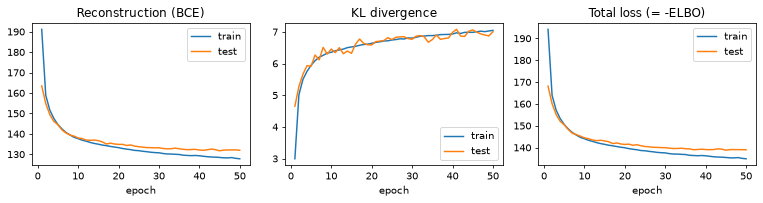

In [72]:
history = {"train_bce": [], "train_kld": [], "test_bce": [], "test_kld": []}
set_seed()
start = time.time()
for epoch in range(EPOCHS):
    tr = train(epoch, VAE_model, trainloader, optimizer)
    te = test(epoch, VAE_model, testloader)
    generated = latent_to_image(epoch, VAE_model)
    history["train_bce"].append(tr["bce"])
    history["train_kld"].append(tr["kld"])
    history["test_bce"].append(te["bce"])
    history["test_kld"].append(te["kld"])
    if epoch == 0 or (epoch + 1) % LOG_EVERY == 0:
        print(f"Epoch {epoch + 1:3d}  train loss {tr['bce'] + tr['kld']:.2f} (BCE {tr['bce']:.2f} + KLD {tr['kld']:.2f})"
              f"  test loss {te['bce'] + te['kld']:.2f}")
print(f"elapsed: {time.time() - start:.0f}s")
writer.close()

epochs_axis = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, key, title in zip(axes, ["bce", "kld"], ["Reconstruction (BCE)", "KL divergence"]):
    ax.plot(epochs_axis, history[f"train_{key}"], label="train")
    ax.plot(epochs_axis, history[f"test_{key}"], label="test")
    ax.set(xlabel="epoch", title=title)
    ax.legend()
axes[2].plot(epochs_axis, np.add(history["train_bce"], history["train_kld"]), label="train")
axes[2].plot(epochs_axis, np.add(history["test_bce"], history["test_kld"]), label="test")
axes[2].set(xlabel="epoch", title="Total loss (= -ELBO)")
axes[2].legend()
plt.tight_layout()
plt.show()

Total Loss = KL Divergence + Reconstruction Error 입니다. 위 그래프에서 복원 오차는 줄고, KL은 처음에 빠르게 늘다가 증가 폭이 작아지며, 전체 손실은 줄어듭니다.

> **흔한 오해**: KL이 늘어나는 것을 보고 인코더가 제대로 학습되지 못한다고 해석하면 틀립니다. 학습 맨 처음(첫 에폭 안에서)에는 모든 $x$의 $z$가 $N(0, I)$ 근처여서 KL이 거의 0이고 복원은 엉망입니다. 학습이 되면서 인코더가 $x$의 정보를 $z$에 담기 시작하면 $q(z|x)$는 데이터마다 다른 위치로 옮겨 가고 KL은 **커지는 것이 정상**입니다. KL은 "$z$에 담은 정보의 양"에 해당합니다. 오히려 KL이 0으로 붙어 있으면 $z$가 아무 정보도 담지 않는다는 뜻으로, 이 현상을 **posterior collapse**라고 합니다. 아래에서 직접 만들어 봅니다.

In [73]:
%load_ext tensorboard
%tensorboard --logdir runs/VAE_Result

코랩에서만 실행: 텐서보드 확장
코랩에서만 실행: 텐서보드 화면


저장된 노트북에서도 볼 수 있도록, 마지막 에폭의 복원과 생성 결과를 그립니다. 생성 이미지는 인코더 없이 $N(0, I)$에서 뽑은 $z$로 만든 것입니다.

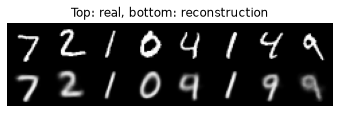

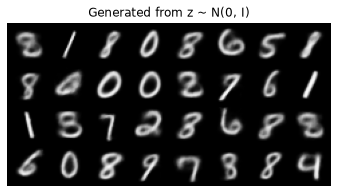

In [74]:
VAE_model.eval()
data, _ = next(iter(testloader))
with torch.no_grad():
    recon, _, _ = VAE_model(data.to(device))
imshow_grid(torch.cat([data[:8], recon.view(-1, 1, 28, 28)[:8].cpu()]), "Top: real, bottom: reconstruction")
imshow_grid(generated[:32], "Generated from z ~ N(0, I)")

숫자처럼 보이지만 흐릿합니다. 잠재 차원이 2뿐이고, 픽셀별 독립 가정 때문에 VAE는 그럴듯한 값들의 평균을 내놓는 경향이 있기 때문입니다. 또렷한 이미지를 잘 만드는 GAN과 대비되는 점입니다.

### `reduction`을 바꾸면 어떻게 될까: posterior collapse 만들기

3.4절의 주장을 실험합니다. 복원 항을 `reduction="mean"`으로 바꾸면 픽셀과 배치 모두에 대해 평균이 됩니다. 배치 크기의 영향을 빼고 784분의 1이라는 효과만 보도록 KL도 배치 평균으로 맞춥니다. 복원 항이 784분의 1로 작아지므로 KL 항이 손실을 지배합니다. 5 에폭만 돌려 봅니다.

epoch 1: KLD per image = 0.00031


epoch 2: KLD per image = 0.00000


epoch 3: KLD per image = 0.00000


epoch 4: KLD per image = 0.00000


epoch 5: KLD per image = 0.00000


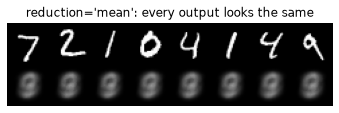

output std across the batch: 0.0037214597687125206


In [75]:
COLLAPSE_EPOCHS = 5
set_seed()
collapse_model = VAE(28 * 28, 512, 256, 2).to(device)
collapse_opt = optim.Adam(collapse_model.parameters(), lr=1e-3)
for epoch in range(COLLAPSE_EPOCHS):
    collapse_model.train()
    total_kld = 0.0
    for data, _ in trainloader:
        data = data.to(device)
        recon_batch, mu, logvar = collapse_model(data)
        bce_mean = F.binary_cross_entropy(recon_batch, data.view(-1, 784), reduction="mean")   # 잘못된 축약
        kld_per_image = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(data)
        loss = bce_mean + kld_per_image
        collapse_opt.zero_grad()
        loss.backward()
        collapse_opt.step()
        total_kld += kld_per_image.item() * len(data)
    print(f"epoch {epoch + 1}: KLD per image = {total_kld / len(trainloader.dataset):.5f}")

collapse_model.eval()
data, _ = next(iter(testloader))
with torch.no_grad():
    recon_bad, _, _ = collapse_model(data.to(device))
imshow_grid(torch.cat([data[:8], recon_bad.view(-1, 1, 28, 28)[:8].cpu()]), "reduction='mean': every output looks the same")
print("output std across the batch:", recon_bad.std(dim=0).mean().item())

KL이 사실상 0이 되고, 어떤 입력을 넣어도 비슷한 이미지(평균 숫자)가 나옵니다. $z$가 입력에 대한 정보를 담지 않게 된 것입니다. `reduction` 인자 하나가 수식의 균형을 바꿉니다.

### 잠재 공간 살펴보기

학습된 VAE로 만든 10000개의 MNIST 테스트 이미지의 2차원 표현을 봅니다.

In [76]:
testloader_2 = torch.utils.data.DataLoader(testset, batch_size=10000, shuffle=False, num_workers=NUM_WORKERS)

(10000, 2) mean: [-0.04 -0.05] std: [1.01 1.07]


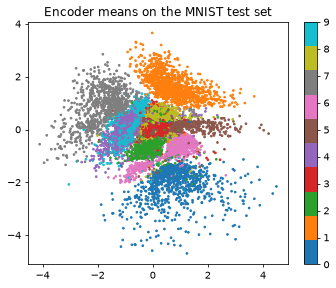

In [77]:
sample, label = next(iter(testloader_2))
label_np = label.numpy()   # 그림의 색으로 쓴다

VAE_model.eval()
with torch.no_grad():
    mu, _ = VAE_model.encode(sample.view(-1, 784).to(device))
mu = mu.cpu().numpy()
print(mu.shape, "mean:", mu.mean(axis=0).round(2), "std:", mu.std(axis=0).round(2))
plt.figure(figsize=(6, 4.5))
plt.scatter(mu[:, 0], mu[:, 1], c=label_np, cmap="tab10", s=3)
plt.colorbar(ticks=range(10))
plt.title("Encoder means on the MNIST test set")
plt.show()

잠재 공간의 $(x, y)$ 값을 바꿔 가며 디코더가 만드는 이미지가 어떻게 변하는지 봅니다. 잠재 공간이 연속적이라면 이미지도 부드럽게 변해야 합니다.

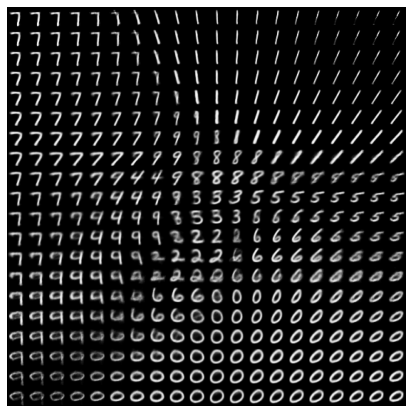

In [78]:
nx = ny = 20
x_values = np.linspace(-3, 3, nx)   # -3부터 3까지 균등한 간격으로 숫자 만들기
y_values = np.linspace(-3, 3, ny)

canvas = np.empty((28 * ny, 28 * nx))   # 560 x 560 크기의 도화지
with torch.no_grad():
    for i, yi in enumerate(y_values):
        for j, xi in enumerate(x_values):
            z_point = torch.tensor([[xi, yi]], dtype=torch.float32, device=device)
            x_mean = VAE_model.decode(z_point).cpu().reshape(28, 28).numpy()
            # y가 클수록 그림의 위쪽에 오도록 행 번호를 뒤집는다
            canvas[(ny - i - 1) * 28 : (ny - i) * 28, j * 28 : (j + 1) * 28] = x_mean

plt.figure(figsize=(6, 6))
plt.imshow(canvas, origin="upper", cmap="gray")
plt.axis("off")
plt.tight_layout()
plt.show()

### 실습 3. 잠재 공간에서 두 숫자 잇기

두 잠재 벡터를 선형으로 잇는 함수를 작성하세요. `steps`개의 점을 돌려주며, 처음은 `z1`, 끝은 `z2`입니다. 함수를 만든 뒤, 테스트 데이터의 숫자 두 장을 인코더에 넣어 얻은 `mu`를 양 끝으로 삼아 디코더로 이미지를 만들어 보세요. 한 숫자가 다른 숫자로 서서히 변합니다.

```python
def interpolate_z(z1: torch.Tensor, z2: torch.Tensor, steps: int) -> torch.Tensor:
    ...
```

In [79]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def interpolate_z(z1: torch.Tensor, z2: torch.Tensor, steps: int) -> torch.Tensor:
    """z1에서 z2까지 일정한 간격으로 steps개의 잠재 벡터를 만듭니다."""
    weights = torch.linspace(0, 1, steps, device=z1.device).unsqueeze(1)
    return (1 - weights) * z1 + weights * z2


a, b = torch.tensor([0.0, 0.0]), torch.tensor([2.0, -4.0])
path = interpolate_z(a, b, 5)
assert path.shape == (5, 2)
assert torch.equal(path[0], a) and torch.equal(path[-1], b)
assert torch.allclose(path[2], torch.tensor([1.0, -2.0]))

with torch.no_grad():
    mus, _ = VAE_model.encode(sample[:2].view(-1, 784).to(device))
    images = VAE_model.decode(interpolate_z(mus[0], mus[1], 10)).view(-1, 1, 28, 28)
imshow_grid(images, f"From digit {label_np[0]} to digit {label_np[1]}")
```

</details>

---
# 4교시. FCN과 U-Net

## 4.1 Segmentation이란?

이미지의 픽셀 수준에서 각 영역이 어떤 의미를 갖는지 분리하는 방법입니다.

- **Semantic Segmentation**: 의미대로 분할합니다. 같은 클래스면 서로 다른 물체여도 같은 색입니다.
- **Instance Segmentation**: 물체(object)대로 분할합니다. 같은 클래스라도 물체마다 다른 색입니다.

구체적으로는 **이미지의 각 픽셀이 어느 클래스에 속하는지 예측**합니다. 즉 사진의 모든 픽셀을 해당하는 클래스로 분류하는 문제입니다.

(참고 그림: [시맨틱과 인스턴스 비교](https://velog.velcdn.com/images%2Fcha-suyeon%2Fpost%2Faa245159-a1f4-47f3-8e30-4f48ec916543%2Fimage.png), [픽셀별 분류](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FoXhHC%2Fbtq0vRbGj1m%2FKX1XtTC3F0DM7pOb906QYK%2Fimg.png). 아래에서 실제 데이터로 봅니다.)

4, 5교시에서는 **Penn-Fudan 보행자 데이터**를 씁니다. 이미지 170장에 보행자마다 다른 번호가 칠해진 마스크가 있습니다. 출처는 [Penn-Fudan Database](https://www.cis.upenn.edu/~jshi/ped_html/)이고, 논문은 Wang, Shi, Song, Shen의 "Object Detection Combining Recognition and Segmentation"(ACCV 2007)입니다. 실제 보행자가 찍힌 사진이라 **재게시 조건을 고려해 사진이 보이는 그림은 이 노트북에 저장하지 않았습니다.** 코드를 실행하면 직접 볼 수 있습니다. 같은 데이터를 시맨틱 분할(4교시)과 인스턴스 분할(5교시)에 모두 쓸 수 있습니다.

In [80]:
PENN_URL = "https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip"
PENN_ROOT = Path(DATA_ROOT) / "PennFudanPed"
if not PENN_ROOT.exists():
    tv.datasets.utils.download_and_extract_archive(PENN_URL, download_root=DATA_ROOT)

image_files = sorted((PENN_ROOT / "PNGImages").glob("*.png"))
mask_files = sorted((PENN_ROOT / "PedMasks").glob("*.png"))
print(len(image_files), len(mask_files))

# 사람이 여러 명인 이미지를 골라 시맨틱과 인스턴스의 차이를 본다
crowded = max(range(len(mask_files)), key=lambda i: np.array(Image.open(mask_files[i])).max())
example_img = Image.open(image_files[crowded]).convert("RGB")
example_mask = np.array(Image.open(mask_files[crowded]))
print("pixel values in the mask:", np.unique(example_mask), "(0 is background, others are person ids)")

plt.figure(figsize=(4, 3.5))
plt.imshow(example_img)
plt.title("Image")
plt.axis("off")
plt.show()

170 170
pixel values in the mask: [0 1 2 3 4 5 6 7 8] (0 is background, others are person ids)


이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


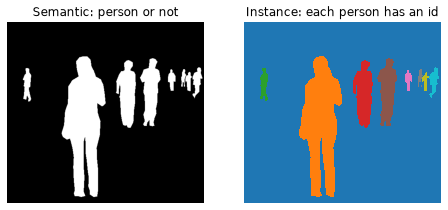

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(example_mask > 0, cmap="gray")
axes[0].set_title("Semantic: person or not")
axes[1].imshow(example_mask, cmap="tab10", interpolation="nearest")
axes[1].set_title("Instance: each person has an id")
for ax in axes:
    ax.axis("off")
plt.show()

픽셀별 분류가 코드에서 어떤 모양인지 확인합니다. 분류 모델이 `(배치, 클래스)`를 낸다면, 분할 모델은 `(배치, 클래스, 높이, 너비)`를 냅니다. 픽셀마다 클래스 점수가 있는 셈입니다. `CrossEntropyLoss`는 이 모양을 그대로 받아 픽셀별 평균을 냅니다.

In [82]:
# 2클래스, 2x3 이미지 한 장에 대한 모델 출력(logit)
logits = torch.tensor([[[[2.0, 0.1, -1.0], [1.5, -0.5, -2.0]],     # 배경 클래스 점수
                        [[-1.0, 0.3, 2.0], [0.0, 1.0, 1.0]]]])     # 사람 클래스 점수
print("logits:", logits.shape, "(batch, class, H, W)")
prediction = logits.argmax(dim=1)
print("prediction:\n", prediction)

target = torch.tensor([[[0, 1, 1], [0, 1, 1]]])
print("target:", target.shape, "(batch, H, W)")
print("cross entropy:", F.cross_entropy(logits, target).item())

logits: torch.Size([1, 2, 2, 3]) (batch, class, H, W)
prediction:
 tensor([[[0, 1, 1],
         [0, 1, 1]]])
target: torch.Size([1, 2, 3]) (batch, H, W)
cross entropy: 0.19112126529216766


## 4.2 FCN (Fully Convolutional Network)

초기의 분류 CNN(LeNet, AlexNet, GoogLeNet 등)은 끝에 완전연결층을 두어 **"이미지 전체의 답" 하나**를 냅니다. 완전연결층은 입력을 일렬로 펴서 위치 정보를 버리고, 입력 크기도 고정합니다. 분할에 쓰기에는 이것이 한계입니다. FCN은 기존 CNN의 완전연결층을 합성곱으로 바꿔 이 한계를 극복합니다. ([FCN 구조](https://gaussian37.github.io/assets/img/vision/segmentation/fcn/1.png), [완전연결층을 합성곱으로 바꾸는 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fdab59q%2Fbtq0tfkffFq%2Fk4GD8TKLusWjfVq36DMBn0%2Fimg.png))

네 단계로 동작합니다.

1. 합성곱층으로 특징을 추출합니다.
2. 1×1 합성곱층으로 낮은 해상도의 Class Presence Heat Map을 만듭니다.
3. 전치 합성곱으로 낮은 해상도의 히트맵을 업샘플링해 입력과 같은 크기의 맵을 만듭니다.
4. 각 픽셀에서 확률이 가장 높은 클래스를 고릅니다. 그 클래스로 칠하면 분할 결과입니다.

### Upsampling 방법

1/32로 줄어든 특성맵을 한 번에 32배로 늘리면 뭉뚱그려지고 디테일이 없어집니다. 실제 마스크로 재 봅시다. 마스크를 1/k로 줄였다가 다시 키워서, **예측이 완벽해도 해상도 때문에 얼마나 잃는지** 확인합니다. ([참고 그림 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FZHivi%2Fbtq0qA3fGBE%2FsDELHesscgPxC2cbWk6au1%2Fimg.png), [참고 그림 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbb7uvh%2Fbtq0zdkIsTF%2FQWkZ87uNnbUqjb505VldH0%2Fimg.png))

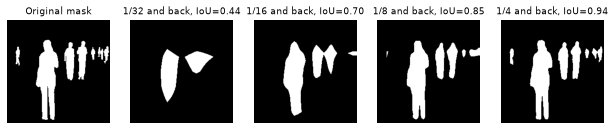

In [83]:
mask_tensor = torch.from_numpy(example_mask > 0).float()[None, None]
mask_tensor = F.interpolate(mask_tensor, size=(224, 224), mode="nearest")

factors = [32, 16, 8, 4]
fig, axes = plt.subplots(1, len(factors) + 1, figsize=(11, 2.4))
axes[0].imshow(mask_tensor.squeeze(), cmap="gray")
axes[0].set_title("Original mask", fontsize=9)
for ax, k in zip(axes[1:], factors):
    small = F.avg_pool2d(mask_tensor, k)
    restored = F.interpolate(small, size=(224, 224), mode="bilinear", align_corners=False) > 0.5
    truth = mask_tensor.bool()
    iou = (restored & truth).sum().item() / (restored | truth).sum().item()
    ax.imshow(restored.squeeze(), cmap="gray")
    ax.set_title(f"1/{k} and back, IoU={iou:.2f}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.show()

1/32 해상도에서는 사람 모양이 사라집니다. 그래서 FCN은 **skip combining** 기법을 씁니다. 더 앞 단계의 해상도 높은 특성맵을 참고하며 업샘플링합니다. 깊은 층은 "무엇인가"를 잘 알고, 얕은 층은 "어디인가"를 잘 압니다. 둘을 더하면 양쪽의 장점을 얻습니다.

FCN 논문의 이름은 어디까지 합쳤는지를 가리킵니다. FCN-32s는 1/32에서 한 번에, FCN-16s는 1/16과 합쳐서, FCN-8s는 1/8까지 합쳐서 복원합니다. 합칠수록 경계가 정밀해집니다. ([skip 구조 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FZTyVe%2Fbtq0vPLEa9K%2FyDo9ZkXqPknWkXPIEImWK1%2Fimg.png), [skip 구조 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcExu63%2Fbtq0u5OM1rP%2FQp8uJPTBpkMC0xkZoqJzAK%2Fimg.png), [32s, 16s, 8s 결과 비교](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FczpfKI%2Fbtq0vPkz77r%2F9vhp9EICvkrgtKTPrUtTM0%2Fimg.png))

## 4.3 사전학습된 FCN 써 보기

`torchvision`의 FCN을 사용해 봅니다. `torch.hub.load`는 저장소의 코드를 내려받아 실행하므로, 같은 모델이 들어 있는 `torchvision`을 직접 쓰는 편이 안전합니다.

이 모델은 이름만 FCN이고 구조는 4.2절과 조금 다릅니다. ResNet-50의 뒤쪽 단계에서 stride 대신 팽창 합성곱(dilated convolution)을 써서 1/8 해상도까지만 줄이고, 그 출력을 쌍선형 보간으로 한 번에 키웁니다. 전치 합성곱과 skip이 없습니다. 해상도를 처음부터 덜 잃는 다른 해법입니다.

In [84]:
fcn_weights = tv.models.segmentation.FCN_ResNet50_Weights.DEFAULT
fcn_model = tv.models.segmentation.fcn_resnet50(weights=fcn_weights)
# 더 큰 모델을 쓰려면 fcn_resnet101과 FCN_ResNet101_Weights를 쓴다
fcn_model.eval()
print("classes:", fcn_weights.meta["categories"])

classes: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']


사용할 이미지를 내려받습니다. 양과 양치기 개 사진입니다(사진: Rosendahl, 퍼블릭 도메인, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Sheep_and_sheep_dog_on_field.jpg)). 위키미디어는 프로그램의 요청에 `User-Agent`를 요구하므로 헤더를 함께 보냅니다.

In [85]:
url, filename = ("https://upload.wikimedia.org/wikipedia/commons/d/d0/Sheep_and_sheep_dog_on_field.jpg", "sheep_and_dog.jpg")
if not os.path.exists(filename):
    request = urllib.request.Request(url, headers={"User-Agent": "deep-learning-course/1.0"})
    with urllib.request.urlopen(request, timeout=60) as response:
        Path(filename).write_bytes(response.read())

In [86]:
input_image = Image.open(filename)
input_image = input_image.convert("RGB")
print(input_image.size)

(1280, 960)


In [87]:
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

input_tensor = preprocess(input_image)
input_batch = input_tensor.unsqueeze(0).to(device)   # 모델은 배치 차원을 기대한다
fcn_model.to(device)

with torch.no_grad():
    output = fcn_model(input_batch)["out"][0]
print("output:", output.shape, "(21 classes, H, W)")
output_predictions = output.argmax(0)

# 어떤 클래스가 얼마나 나왔는지 숫자로 본다
categories = fcn_weights.meta["categories"]
ids, counts = output_predictions.unique(return_counts=True)
for i, c in zip(ids.tolist(), counts.tolist()):
    print(f"{categories[i]:12s} {100 * c / output_predictions.numel():5.1f}%")

output: torch.Size([21, 960, 1280]) (21 classes, H, W)


__background__  64.5%
cow            1.7%
dog           11.3%
sheep         22.6%


결과를 그려 봅니다. 21개 클래스마다 다른 색을 칠합니다.

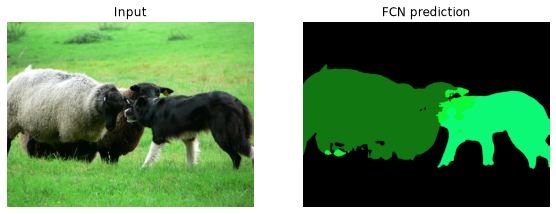

In [88]:
# 클래스마다 다른 색이 되도록 팔레트를 만든다
palette = torch.tensor([2 ** 25 - 1, 2 ** 15 - 1, 2 ** 21 - 1])
colors = torch.as_tensor([i for i in range(21)])[:, None] * palette
colors = (colors % 255).numpy().astype("uint8")

# 21개 클래스의 예측을 각각의 색으로 칠한다
r = Image.fromarray(output_predictions.byte().cpu().numpy()).resize(input_image.size)
r.putpalette(colors.flatten().tolist())   # 최근 Pillow는 NumPy 배열을 직접 받지 못한다

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].imshow(input_image)
axes[0].set_title("Input")
axes[1].imshow(r)
axes[1].set_title("FCN prediction")
for ax in axes:
    ax.axis("off")
plt.show()

_ = fcn_model.to("cpu")   # 뒤의 학습에 메모리를 쓰도록 비켜 둔다. _로 받아 모델 구조 출력을 막는다

## 4.4 FCN 직접 구현하고 학습하기

본 흐름에서는 계정 없이 받을 수 있는 Penn-Fudan 보행자 데이터를 씁니다. 같은 코드를 의료 영상에 적용하는 폐 X-ray 분할([참고 글](https://kimbg.tistory.com/18))은 이 교시 끝의 **선택 실습**에 있습니다.

문제는 사람과 배경을 가르는 2클래스 분할입니다.

In [89]:
### HYPER PARAMETER ###
RANDOM_SEED = 831
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 4
NUM_CLASS = 2
EPOCHS = 30    # 학습 이미지가 100여 장뿐이라 에폭당 갱신 횟수가 적으므로 넉넉히 둔다
SEG_LOG_EVERY = 5

TEST_ratio = 0.2   # 전체 170장뿐이라 평가가 너무 흔들리지 않도록 테스트를 넉넉히 둔다
VAL_ratio = 0.2

In [90]:
X, X_test, y, y_test = model_selection.train_test_split(image_files, mask_files, test_size=TEST_ratio, random_state=RANDOM_SEED)
X_train, X_val, y_train, y_val = model_selection.train_test_split(X, y, test_size=VAL_ratio, random_state=RANDOM_SEED)
print(len(X_train), len(X_val), len(X_test))

samplex = np.array(Image.open(X_train[0]).convert("RGB"))
sampley = np.array(Image.open(y_train[0]))
print(samplex.shape, samplex.dtype)
print(sampley.shape, sampley.dtype, np.unique(sampley))

108 28 34
(348, 342, 3) uint8
(348, 342) uint8 [0 1]


이미지마다 크기가 다르므로 224×224로 맞춥니다. 이때 **마스크는 반드시 최근접(NEAREST) 보간**으로 줄여야 합니다. 일반 보간을 쓰면 0과 1 사이의 값이 생겨 레이블이 깨집니다.

정답은 클래스 번호 `(H, W)`로 둡니다. `CrossEntropyLoss`는 클래스 번호와 원-핫 확률 두 형태를 모두 받고 값이 같습니다. 아래 셀에서 확인합니다.

학습 데이터가 적으므로 학습 때만 좌우 반전을 넣습니다. 이미지와 마스크를 **함께** 뒤집어야 합니다.

In [91]:
class SegmentationDataset(torch.utils.data.Dataset):
    """이미지와 마스크 파일 목록을 받아 (3, H, W) 이미지와 (H, W) 클래스 번호를 돌려줍니다."""

    def __init__(self, img_path: list[Path], img_labels: list[Path], transforms_x: tv.transforms.Compose | None = None, transforms_y: tv.transforms.Compose | None = None, flip: bool = False) -> None:
        self.img_path = img_path
        self.img_labels = img_labels
        self.transforms_x = transforms_x
        self.transforms_y = transforms_y
        self.flip = flip

    def __len__(self) -> int:
        return len(self.img_path)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        # 흑백 이미지도 RGB로 바꾸면 같은 값이 3채널로 복제되어 모델을 그대로 쓸 수 있다
        ten_x = tv.transforms.functional.to_tensor(Image.open(self.img_path[index]).convert("RGB"))

        mask = np.array(Image.open(self.img_labels[index]))
        if mask.ndim == 3:
            mask = mask[..., 0]
        # 0은 배경, 그 외는 전경이다. 보행자의 번호는 시맨틱 분할에 필요 없다
        ten_y = torch.from_numpy((mask > 0).astype(np.int64)).unsqueeze(0)

        if self.transforms_x:
            # 안티에일리어싱 보간은 값이 0~1을 살짝 벗어날 수 있어 범위를 맞춘다
            ten_x = self.transforms_x(ten_x).clamp(0, 1)
        if self.transforms_y:
            ten_y = self.transforms_y(ten_y)
        if self.flip and random.random() < 0.5:
            ten_x, ten_y = ten_x.flip(-1), ten_y.flip(-1)
        return ten_x, ten_y.squeeze(0)


### TRANSFORM & CHECK ###
x_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE, antialias=True),
])
y_transforms = tv.transforms.Compose([
    tv.transforms.Resize(size=IMAGE_SIZE, interpolation=tv.transforms.InterpolationMode.NEAREST),
])

In [92]:
train_ds = SegmentationDataset(X_train, y_train, x_transforms, y_transforms, flip=True)
val_ds = SegmentationDataset(X_val, y_val, x_transforms, y_transforms)
test_ds = SegmentationDataset(X_test, y_test, x_transforms, y_transforms)

set_seed()
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=NUM_WORKERS)

train_sample_x, train_sample_y = next(iter(train_loader))
print(f"train_sample_x.shape: {train_sample_x.shape}")
print(f"train_sample_x.dtype: {train_sample_x.dtype}")
print(f"train_sample_x.min, max: {train_sample_x.min().item():.3f}, {train_sample_x.max().item():.3f}")
print(f"train_sample_y.shape: {train_sample_y.shape}")
print(f"train_sample_y.dtype: {train_sample_y.dtype}")
print(f"train_sample_y.unique: {train_sample_y.unique().tolist()}")

# 클래스 번호와 원-핫 확률, 두 형태의 정답이 같은 손실을 주는지 확인한다
one_hot = F.one_hot(train_sample_y, num_classes=NUM_CLASS).permute(0, 3, 1, 2).float()
fake_logits = torch.randn(BATCH_SIZE, NUM_CLASS, *IMAGE_SIZE)
loss_index = F.cross_entropy(fake_logits, train_sample_y)
loss_onehot = F.cross_entropy(fake_logits, one_hot)
print(f"CE with class index: {loss_index.item():.6f}, with one-hot: {loss_onehot.item():.6f}")
assert torch.isclose(loss_index, loss_onehot)

train_sample_x.shape: torch.Size([4, 3, 224, 224])
train_sample_x.dtype: torch.float32
train_sample_x.min, max: 0.000, 1.000
train_sample_y.shape: torch.Size([4, 224, 224])
train_sample_y.dtype: torch.int64
train_sample_y.unique: [0, 1]
CE with class index: 0.902880, with one-hot: 0.902880


In [93]:
### VISUALIZE ###
ncols, nrows = 4, 2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(2.5 * ncols, 2.5 * nrows))
for i in range(ncols):
    axes[0, i].imshow(train_sample_x[i].permute(1, 2, 0))
    axes[1, i].imshow(train_sample_y[i], cmap="gray")
axes[0, 0].set_ylabel("train_x_sample")
axes[1, 0].set_ylabel("train_y_sample")
plt.tight_layout()
plt.show()

이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


VGG 방식의 블록(합성곱 뒤에 풀링)을 쌓은 FCN을 직관적으로 구현한 코드입니다. VGG-16과 똑같지는 않습니다(블록당 합성곱 2개). `torchvision`의 사전학습 VGG를 쓰는 방법도 있지만, 구조가 잘 보이도록 처음부터 만듭니다.

4.2절의 4단계와 다른 점이 있습니다. 논문은 낮은 해상도에서 1×1 합성곱으로 클래스 점수맵을 만든 뒤 점수맵끼리 합치며 키우는데, 이 구현은 특성맵 상태로 합치며 키운 다음 **맨 끝에서** 1×1 합성곱을 적용합니다.

이 코드는 **모든 max pooling 층의 출력**을 skip으로 씁니다. 논문의 FCN-8s보다 더 많이 합치는 변형입니다. 디코더의 각 단계에서 같은 크기의 인코더 특성맵을 **더합니다**(`score + x4`). 채널 수가 같아야 더할 수 있으므로 디코더의 채널을 인코더에 맞췄습니다.

In [94]:
class FCN(nn.Module):
    def __init__(self) -> None:
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.block2 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.block3 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.block4 = nn.Sequential(
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.block5 = nn.Sequential(
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.relu = nn.ReLU(inplace=True)
        self.deconv1 = nn.ConvTranspose2d(512, 512, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn1 = nn.BatchNorm2d(512)
        self.deconv2 = nn.ConvTranspose2d(512, 256, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn2 = nn.BatchNorm2d(256)
        self.deconv3 = nn.ConvTranspose2d(256, 128, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.deconv4 = nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn4 = nn.BatchNorm2d(64)
        self.deconv5 = nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, dilation=1, output_padding=1)
        self.bn5 = nn.BatchNorm2d(32)
        self.classifier = nn.Conv2d(32, NUM_CLASS, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.block1(x)
        x1 = x
        x = self.block2(x)
        x2 = x
        x = self.block3(x)
        x3 = x
        x = self.block4(x)
        x4 = x
        x = self.block5(x)
        x5 = x

        score = self.bn1(self.relu(self.deconv1(x5)))     # size=(N, 512, x.H/16, x.W/16)
        score = score + x4                                # 원소별 덧셈, size=(N, 512, x.H/16, x.W/16)
        score = self.bn2(self.relu(self.deconv2(score)))  # size=(N, 256, x.H/8, x.W/8)
        score = score + x3                                # 원소별 덧셈, size=(N, 256, x.H/8, x.W/8)
        score = self.bn3(self.relu(self.deconv3(score)))  # size=(N, 128, x.H/4, x.W/4)
        score = score + x2                                # 원소별 덧셈, size=(N, 128, x.H/4, x.W/4)
        score = self.bn4(self.relu(self.deconv4(score)))  # size=(N, 64, x.H/2, x.W/2)
        score = score + x1                                # 원소별 덧셈, size=(N, 64, x.H/2, x.W/2)
        score = self.bn5(self.relu(self.deconv5(score)))  # size=(N, 32, x.H, x.W)
        score = self.classifier(score)                    # size=(N, n_class, x.H, x.W)

        return score


model = FCN()
print(summary(model, input_size=(1, 3, 224, 224), depth=1, verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
FCN                                      [1, 2, 224, 224]          --
├─Sequential: 1-1                        [1, 64, 112, 112]         38,720
├─Sequential: 1-2                        [1, 128, 56, 56]          221,440
├─Sequential: 1-3                        [1, 256, 28, 28]          885,248
├─Sequential: 1-4                        [1, 512, 14, 14]          3,539,968
├─Sequential: 1-5                        [1, 512, 7, 7]            4,719,616
├─ConvTranspose2d: 1-6                   [1, 512, 14, 14]          2,359,808
├─ReLU: 1-7                              [1, 512, 14, 14]          --
├─BatchNorm2d: 1-8                       [1, 512, 14, 14]          1,024
├─ConvTranspose2d: 1-9                   [1, 256, 28, 28]          1,179,904
├─ReLU: 1-10                             [1, 256, 28, 28]          --
├─BatchNorm2d: 1-11                      [1, 256, 28, 28]          512
├─ConvTranspose2d: 1-12                

손실만 봐서는 분할 품질을 알기 어렵습니다. **Dice**를 직접 구현합니다. 실무에서는 `monai` 같은 라이브러리도 많이 씁니다.

$$\text{Dice} = \frac{2|A\cap B|}{|A|+|B|},\qquad \text{IoU} = \frac{|A\cap B|}{|A\cup B|}$$

**왜 픽셀 정확도로는 부족할까요?** 사람은 이미지의 일부입니다. 전부 배경이라고 찍어도 픽셀 정확도는 높게 나옵니다. 데이터로 확인합니다.

In [95]:
def dice_iou(pred: torch.Tensor, target: torch.Tensor) -> tuple[float, float]:
    """(H, W) 크기의 이진 예측과 정답으로 전경의 Dice와 IoU를 계산합니다."""
    pred, target = pred.bool(), target.bool()
    inter = (pred & target).sum().item()
    total = pred.sum().item() + target.sum().item()
    union = (pred | target).sum().item()
    # 둘 다 비어 있으면 완벽히 맞힌 것으로 본다
    return (2 * inter / total if total else 1.0), (inter / union if union else 1.0)


foreground = np.mean([y.float().mean().item() for _, y in test_ds])
print(f"person pixels in the test set: {foreground * 100:.1f}%")
print(f"pixel accuracy if we always answer background: {(1 - foreground) * 100:.1f}%  (Dice = 0)")

assert dice_iou(torch.tensor([[1, 1], [0, 0]]), torch.tensor([[1, 0], [0, 0]])) == (2 * 1 / 3, 1 / 2)

person pixels in the test set: 16.4%
pixel accuracy if we always answer background: 83.6%  (Dice = 0)


In [96]:
CE_LOSS = torch.nn.CrossEntropyLoss()
SEG_LR = 0.001
SEG_WEIGHT_DECAY = 2e-4

학습과 평가 함수입니다.

> **흔한 실수**: 평가 함수가 인자를 무시하고 전역 변수 `val_loader`를 읽으면, 무엇을 넘겨도 검증 데이터로 평가합니다. 또 검증 손실을 `Test Loss`로 출력하면 나중에 테스트 성능으로 착각하게 됩니다.

In [97]:
def train_one_epoch_seg(model: nn.Module, loader: torch.utils.data.DataLoader, optimizer: torch.optim.Optimizer) -> float:
    """한 에폭 학습하고 평균 손실을 돌려줍니다."""
    model.train()   # BatchNorm이 배치 통계를 쓰도록 학습 모드로 둔다
    epoch_loss = 0.0
    for data, target in loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()   # 이전 배치의 기울기를 지운다
        output = model(data)
        loss = CE_LOSS(output, target)
        loss.backward()         # 모든 파라미터의 grad에 기울기를 계산해 저장한다
        optimizer.step()        # grad에 따라 파라미터를 조정한다
        epoch_loss += loss.item()
    return epoch_loss / len(loader)


def evaluate(model: nn.Module, loader: torch.utils.data.DataLoader) -> dict[str, float]:
    """이미지별 손실, Dice, IoU, 픽셀 정확도의 평균을 돌려줍니다."""
    model.eval()
    rows = []
    with torch.no_grad():
        for data, target in loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            pred = output.argmax(dim=1)
            for p, t, o in zip(pred, target, output):
                d, i = dice_iou(p, t)
                ce = F.cross_entropy(o[None], t[None]).item()
                rows.append((ce, d, i, (p == t).float().mean().item()))
    loss, dice, iou, acc = np.mean(rows, axis=0)
    return {"loss": float(loss), "dice": float(dice), "iou": float(iou), "pixel_acc": float(acc)}


def fit_segmentation(model: nn.Module, train_dl: torch.utils.data.DataLoader, val_dl: torch.utils.data.DataLoader, epochs: int) -> dict[str, list[float]]:
    """모델을 학습하며 손실과 검증 Dice를 기록합니다."""
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=SEG_LR, weight_decay=SEG_WEIGHT_DECAY)
    losses = {"train": [], "val": [], "val_dice": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch_seg(model, train_dl, optimizer)
        val = evaluate(model, val_dl)
        losses["train"].append(train_loss)
        losses["val"].append(val["loss"])
        losses["val_dice"].append(val["dice"])
        if epoch == 1 or epoch % SEG_LOG_EVERY == 0:
            print(f"[{epoch:2d}] train loss {train_loss:.4f}  val loss {val['loss']:.4f}  val Dice {val['dice']:.3f}")
    print(f"Training complete in {time.time() - start:.0f}s")
    return losses

In [98]:
set_seed(RANDOM_SEED)
fcn_losses = fit_segmentation(model, train_loader, val_loader, EPOCHS)
fcn_test = evaluate(model, test_loader)
print({k: round(v, 3) for k, v in fcn_test.items()})

[ 1] train loss 0.6651  val loss 0.5422  val Dice 0.000


[ 5] train loss 0.3638  val loss 0.2956  val Dice 0.601


[10] train loss 0.2676  val loss 0.2316  val Dice 0.687


[15] train loss 0.2316  val loss 0.2324  val Dice 0.590


[20] train loss 0.2077  val loss 0.1885  val Dice 0.743


[25] train loss 0.1795  val loss 0.1688  val Dice 0.780


[30] train loss 0.1781  val loss 0.1852  val Dice 0.690
Training complete in 64s


{'loss': 0.242, 'dice': 0.591, 'iou': 0.455, 'pixel_acc': 0.906}


In [99]:
def show_predictions(model: nn.Module, dataset: torch.utils.data.Dataset, n: int = 4) -> None:
    """입력, 정답, 예측을 세 행으로 그립니다."""
    model.eval()
    fig, axes = plt.subplots(nrows=3, ncols=n, figsize=(2.5 * n, 7.5))
    with torch.no_grad():
        for i in range(n):
            data, target = dataset[i]
            output = model(data[None].to(device)).argmax(dim=1)[0].cpu()
            axes[0, i].imshow(data.permute(1, 2, 0))
            axes[1, i].imshow(target, cmap="gray")
            axes[2, i].imshow(output, cmap="gray")
            axes[2, i].set_xlabel(f"Dice {dice_iou(output, target)[0]:.2f}")
    for row, name in enumerate(["input", "target", "output"]):
        axes[row, 0].set_ylabel(name)
    plt.tight_layout()
    plt.show()

In [100]:
show_predictions(model, test_ds)

이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


## 4.5 U-Net

오토인코더(autoencoder)와 같은 인코더-디코더(encoder-decoder) 기반 모델입니다.

U-Net의 기본 아이디어는 **저수준 정보(가장자리, 정확한 위치)와 고수준 정보(무엇인지)를 함께 써서** 이미지의 특징을 추출하면서 위치도 정확히 찾자는 것입니다.

인코더 단계의 각 층에서 얻은 특징을 디코더 단계의 각 층에 **이어 붙입니다(concatenation).** FCN이 skip을 더한(add) 것과 다릅니다. 이어 붙이면 채널이 늘고, 뒤따르는 합성곱이 두 정보를 어떻게 섞을지 학습합니다. ([U-Net 구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdlXX6i%2FbtrNT9t903d%2FK0mfIPHAHmNgZsjBlnCJpk%2Fimg.png))

구조가 U자 모양이어서 U-Net입니다. 인코더와 디코더를 잇는 부분을 브릿지(bridge)라고 부릅니다.

일단 인코더 부분을 확대해 봅시다. ([인코더 그림](https://i.imgur.com/uZ1NptA.png))

**ConvBlock**: 그림의 파란색 박스로, 합성곱, 배치 정규화, ReLU를 두 번 반복합니다. ([ConvBlock 그림](https://i.imgur.com/GXZsC0I.png))

구조를 먼저 TensorFlow 코드로 읽어 봅니다. 프레임워크가 달라도 구조는 같습니다.

```python
""" Conv Block """
class ConvBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super().__init__()

        self.conv1 = Conv2D(n_filters, 3, padding='same')
        self.conv2 = Conv2D(n_filters, 3, padding='same')

        self.bn1 = BatchNormalization()
        self.bn2 = BatchNormalization()

        self.activation = Activation('relu')

    def call(self, inputs):
        x = self.conv1(inputs)
        x = self.bn1(x)
        x = self.activation(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.activation(x)

        return x
```

**Encoder Block**: 보라색 박스에서 나오는 출력이 2개입니다. 하나는 U-Net의 디코더로 복사하는 연결선이고, 다른 하나는 다운샘플링해서 인코더의 다음 단계로 보내는 연결선입니다. ([Encoder Block 그림](https://i.imgur.com/45rY6LE.png))

```python
""" Encoder Block """
class EncoderBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super().__init__()

        self.conv_blk = ConvBlock(n_filters)
        self.pool = MaxPooling2D((2,2))

    def call(self, inputs):
        x = self.conv_blk(inputs)
        p = self.pool(x)
        return x, p
```

다음은 디코더 부분입니다. ([디코더 그림](https://i.imgur.com/JD2SM8X.png))

**Decoder Block**: 이전 층의 출력을 키운 뒤 인코더의 출력과 이어 붙입니다. 그래서 고수준 정보와 저수준 정보를 함께 쓸 수 있습니다.

```python
""" Decoder Block """
class DecoderBlock(tf.keras.layers.Layer):
    def __init__(self, n_filters):
        super(DecoderBlock, self).__init__()

        self.up = Conv2DTranspose(n_filters, (2,2), strides=2, padding='same')
        self.conv_blk = ConvBlock(n_filters)

    def call(self, inputs, skip):
        x = self.up(inputs)
        x = Concatenate()([x, skip])
        x = self.conv_blk(x)

        return x
```

이를 합친 U-Net 코드입니다.

```python
""" U-Net Model """
class UNET(tf.keras.Model):
    def __init__(self, n_classes):
        super(UNET, self).__init__()

        # Encoder
        self.e1 = EncoderBlock(64)
        self.e2 = EncoderBlock(128)
        self.e3 = EncoderBlock(256)
        self.e4 = EncoderBlock(512)

        # Bridge
        self.b = ConvBlock(1024)

        # Decoder
        self.d1 = DecoderBlock(512)
        self.d2 = DecoderBlock(256)
        self.d3 = DecoderBlock(128)
        self.d4 = DecoderBlock(64)

        # Outputs
        if n_classes == 1:
            activation = 'sigmoid'
        else:
            activation = 'softmax'

        self.outputs = Conv2D(n_classes, 1, padding='same', activation=activation)

    def call(self, inputs):
        s1, p1 = self.e1(inputs)
        s2, p2 = self.e2(p1)
        s3, p3 = self.e3(p2)
        s4, p4 = self.e4(p3)

        b = self.b(p4)

        d1 = self.d1(b, s4)
        d2 = self.d2(d1, s3)
        d3 = self.d3(d2, s2)
        d4 = self.d4(d3, s1)

        outputs = self.outputs(d4)

        return outputs
```

### 동일 데이터로 U-Net 구현

이번에는 PyTorch입니다. 위 구조를 블록 없이 풀어 쓴 형태입니다. 세부는 조금 다릅니다. TensorFlow 코드는 업샘플 단계에서 채널을 줄이고, 아래 코드는 앞의 합성곱(`dec4_1` 512→256)에서 줄인 뒤 업샘플은 채널을 유지합니다. 마지막 층은 소프트맥스 없이 logit을 냅니다. `CrossEntropyLoss`가 안에서 처리하기 때문입니다(2강 참고).

In [101]:
class UNet(nn.Module):
    def __init__(self) -> None:
        super().__init__()

        def CBR2d(in_channels: int, out_channels: int, kernel_size: int = 3, stride: int = 1, padding: int = 1, bias: bool = True) -> nn.Sequential:
            layers = []
            layers += [nn.Conv2d(in_channels=in_channels, out_channels=out_channels,
                                 kernel_size=kernel_size, stride=stride, padding=padding,
                                 bias=bias)]
            layers += [nn.BatchNorm2d(num_features=out_channels)]
            layers += [nn.ReLU()]

            cbr = nn.Sequential(*layers)

            return cbr

        # Contracting path
        self.enc1_1 = CBR2d(in_channels=3, out_channels=64)
        self.enc1_2 = CBR2d(in_channels=64, out_channels=64)
        self.pool1 = nn.MaxPool2d(kernel_size=2)

        self.enc2_1 = CBR2d(in_channels=64, out_channels=128)
        self.enc2_2 = CBR2d(in_channels=128, out_channels=128)
        self.pool2 = nn.MaxPool2d(kernel_size=2)

        self.enc3_1 = CBR2d(in_channels=128, out_channels=256)
        self.enc3_2 = CBR2d(in_channels=256, out_channels=256)
        self.pool3 = nn.MaxPool2d(kernel_size=2)

        self.enc4_1 = CBR2d(in_channels=256, out_channels=512)
        self.enc4_2 = CBR2d(in_channels=512, out_channels=512)
        self.pool4 = nn.MaxPool2d(kernel_size=2)

        self.enc5_1 = CBR2d(in_channels=512, out_channels=1024)

        # Expansive path
        self.dec5_1 = CBR2d(in_channels=1024, out_channels=512)

        self.unpool4 = nn.ConvTranspose2d(in_channels=512, out_channels=512,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec4_2 = CBR2d(in_channels=2 * 512, out_channels=512)
        self.dec4_1 = CBR2d(in_channels=512, out_channels=256)

        self.unpool3 = nn.ConvTranspose2d(in_channels=256, out_channels=256,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec3_2 = CBR2d(in_channels=2 * 256, out_channels=256)
        self.dec3_1 = CBR2d(in_channels=256, out_channels=128)

        self.unpool2 = nn.ConvTranspose2d(in_channels=128, out_channels=128,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec2_2 = CBR2d(in_channels=2 * 128, out_channels=128)
        self.dec2_1 = CBR2d(in_channels=128, out_channels=64)

        self.unpool1 = nn.ConvTranspose2d(in_channels=64, out_channels=64,
                                          kernel_size=2, stride=2, padding=0, bias=True)
        self.dec1_2 = CBR2d(in_channels=2 * 64, out_channels=64)
        self.dec1_1 = CBR2d(in_channels=64, out_channels=64)

        self.fc = nn.Conv2d(in_channels=64, out_channels=NUM_CLASS, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        enc1_1 = self.enc1_1(x)
        enc1_2 = self.enc1_2(enc1_1)
        pool1 = self.pool1(enc1_2)

        enc2_1 = self.enc2_1(pool1)
        enc2_2 = self.enc2_2(enc2_1)
        pool2 = self.pool2(enc2_2)

        enc3_1 = self.enc3_1(pool2)
        enc3_2 = self.enc3_2(enc3_1)
        pool3 = self.pool3(enc3_2)

        enc4_1 = self.enc4_1(pool3)
        enc4_2 = self.enc4_2(enc4_1)
        pool4 = self.pool4(enc4_2)

        enc5_1 = self.enc5_1(pool4)

        dec5_1 = self.dec5_1(enc5_1)

        unpool4 = self.unpool4(dec5_1)
        cat4 = torch.cat((unpool4, enc4_2), dim=1)   # 크기를 키운 뒤 인코더의 특징을 이어 붙인다
        dec4_2 = self.dec4_2(cat4)
        dec4_1 = self.dec4_1(dec4_2)

        unpool3 = self.unpool3(dec4_1)
        cat3 = torch.cat((unpool3, enc3_2), dim=1)
        dec3_2 = self.dec3_2(cat3)
        dec3_1 = self.dec3_1(dec3_2)

        unpool2 = self.unpool2(dec3_1)
        cat2 = torch.cat((unpool2, enc2_2), dim=1)
        dec2_2 = self.dec2_2(cat2)
        dec2_1 = self.dec2_1(dec2_2)

        unpool1 = self.unpool1(dec2_1)
        cat1 = torch.cat((unpool1, enc1_2), dim=1)
        dec1_2 = self.dec1_2(cat1)
        dec1_1 = self.dec1_1(dec1_2)

        x = self.fc(dec1_1)

        return x


unet = UNet()
print(summary(unet, input_size=(1, 3, 224, 224), depth=1, verbose=0))

Layer (type:depth-idx)                   Output Shape              Param #
UNet                                     [1, 2, 224, 224]          --
├─Sequential: 1-1                        [1, 64, 224, 224]         1,920
├─Sequential: 1-2                        [1, 64, 224, 224]         37,056
├─MaxPool2d: 1-3                         [1, 64, 112, 112]         --
├─Sequential: 1-4                        [1, 128, 112, 112]        74,112
├─Sequential: 1-5                        [1, 128, 112, 112]        147,840
├─MaxPool2d: 1-6                         [1, 128, 56, 56]          --
├─Sequential: 1-7                        [1, 256, 56, 56]          295,680
├─Sequential: 1-8                        [1, 256, 56, 56]          590,592
├─MaxPool2d: 1-9                         [1, 256, 28, 28]          --
├─Sequential: 1-10                       [1, 512, 28, 28]          1,181,184
├─Sequential: 1-11                       [1, 512, 28, 28]          2,360,832
├─MaxPool2d: 1-12                        [1, 

In [102]:
set_seed(RANDOM_SEED)
unet_losses = fit_segmentation(unet, train_loader, val_loader, EPOCHS)
unet_test = evaluate(unet, test_loader)
print({k: round(v, 3) for k, v in unet_test.items()})

[ 1] train loss 0.4861  val loss 0.4241  val Dice 0.019


[ 5] train loss 0.3185  val loss 0.3258  val Dice 0.541


[10] train loss 0.2648  val loss 0.3333  val Dice 0.501


[15] train loss 0.2240  val loss 0.2360  val Dice 0.581


[20] train loss 0.1990  val loss 0.2147  val Dice 0.686


[25] train loss 0.1941  val loss 0.2375  val Dice 0.626


[30] train loss 0.1952  val loss 0.3577  val Dice 0.566
Training complete in 129s


{'loss': 0.368, 'dice': 0.536, 'iou': 0.378, 'pixel_acc': 0.804}


In [103]:
show_predictions(unet, test_ds)

이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


FCN과 U-Net을 같은 조건에서 비교합니다.

             params  test Dice  test IoU  pixel acc
FCN      13,334,050      0.591     0.455      0.906
U-Net    23,381,186      0.536     0.378      0.804


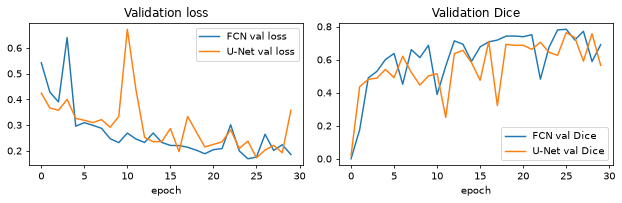

In [104]:
print(f"{'':6s} {'params':>12s} {'test Dice':>10s} {'test IoU':>9s} {'pixel acc':>10s}")
for name, net, result in [("FCN", model, fcn_test), ("U-Net", unet, unet_test)]:
    print(f"{name:6s} {count_params(net):12,d} {result['dice']:10.3f} {result['iou']:9.3f} {result['pixel_acc']:10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for name, curve in [("FCN", fcn_losses), ("U-Net", unet_losses)]:
    axes[0].plot(curve["val"], label=f"{name} val loss")
    axes[1].plot(curve["val_dice"], label=f"{name} val Dice")
axes[0].set(xlabel="epoch", title="Validation loss")
axes[1].set(xlabel="epoch", title="Validation Dice")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

**읽을 때 주의할 점**: 저장된 이 출력에서는 FCN(테스트 Dice 0.591)이 U-Net(0.536)보다 높습니다. 그러나 **거의 같은 코드와 같은 시드로 돌린 시험 실행에서는 U-Net 0.707, FCN 0.620으로 순서가 뒤집혔습니다.** 학습 이미지가 100여 장뿐이고, 사전학습 없이 처음부터 학습했으며, 테스트 이미지도 34장이기 때문입니다. 위 그래프처럼 검증 Dice도 에폭마다 크게 출렁이는데, 여기서는 마지막 에폭의 모델을 평가하므로 그 출렁임이 결과에 그대로 들어갑니다(U-Net은 20 에폭 0.686에서 30 에폭 0.566으로 내려갔습니다). 실무에서는 검증 Dice가 가장 좋은 에폭의 가중치를 저장해 평가합니다.

픽셀 정확도도 보세요. U-Net의 0.804는 전부 배경이라고 찍을 때의 0.836보다 낮지만 Dice는 0보다 훨씬 높습니다. 이 두 지표가 다른 것을 재기 때문입니다. 한 번의 실행으로 어느 모델이 낫다고 단정하지 말고, 시드를 바꿔 반복해 봐야 합니다(숙제).

### 실습 4. PyTorch로 DecoderBlock 만들기

위 TensorFlow의 `DecoderBlock`을 PyTorch로 옮기세요. `in_channels`를 받아 `n_filters`로 줄이며 크기를 2배로 키운 뒤, `skip`과 이어 붙이고, 합성곱-BN-ReLU를 두 번 거칩니다. 입력 `(1, 128, 14, 14)`와 skip `(1, 64, 28, 28)`을 넣으면 출력은 `(1, 64, 28, 28)`이어야 합니다.

```python
class DecoderBlock(nn.Module):
    def __init__(self, in_channels: int, n_filters: int) -> None: ...
    def forward(self, inputs: torch.Tensor, skip: torch.Tensor) -> torch.Tensor: ...
```

In [105]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
class DecoderBlock(nn.Module):
    """크기를 2배로 키우고 인코더 특징과 이어 붙인 뒤 합성곱을 두 번 거칩니다."""

    def __init__(self, in_channels: int, n_filters: int) -> None:
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, n_filters, kernel_size=2, stride=2)
        # 이어 붙이면 채널이 n_filters(위에서 온 것) + n_filters(skip)이 된다
        self.conv_blk = nn.Sequential(
            nn.Conv2d(2 * n_filters, n_filters, 3, padding=1), nn.BatchNorm2d(n_filters), nn.ReLU(),
            nn.Conv2d(n_filters, n_filters, 3, padding=1), nn.BatchNorm2d(n_filters), nn.ReLU(),
        )

    def forward(self, inputs: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.up(inputs)
        x = torch.cat([x, skip], dim=1)
        return self.conv_blk(x)


block = DecoderBlock(128, 64)
out = block(torch.zeros(2, 128, 14, 14), torch.zeros(2, 64, 28, 28))
assert out.shape == (2, 64, 28, 28)
print("OK", out.shape)
```

</details>

## 4.6 선택 실습: Kaggle 폐 X-ray 분할

폐 영역 분할 실습입니다. **계정이 없으면 이 절은 건너뛰고 지나갑니다.** 해 보려면 다음 순서로 준비합니다.

1. [Kaggle](https://www.kaggle.com/)에 가입하고 Settings의 API 항목에서 토큰을 만듭니다(`kaggle.json`에 사용자 이름과 키가 들어 있습니다).
2. 코랩 왼쪽의 열쇠 아이콘(Secrets)에 `KAGGLE_USERNAME`, `KAGGLE_KEY`를 등록하고 노트북 접근을 허용합니다. **키를 코드 셀에 직접 적지 마세요.** 노트북을 공유하면 함께 유출됩니다.
3. 아래 셀을 실행합니다.

데이터는 약 9.6 GB의 [Chest X-ray Masks and Labels](https://www.kaggle.com/datasets/nikhilpandey360/chest-xray-masks-and-labels)이고, 짝이 맞는 566장을 407/102/57로 나눕니다. U-Net 학습은 코랩에서 에폭당 5분 정도를 잡으세요. 데이터의 이용 조건은 Kaggle 페이지에서 직접 확인하세요.

파일 이름의 짝을 맞추는 코드가 까다로우므로, 이 부분은 계정이 없어도 가짜 파일로 동작을 확인합니다.

In [106]:
def lung_file_lists(root_path: Path) -> tuple[list[Path], list[Path]]:
    """이미지와 마스크의 짝을 찾습니다. 마스크 파일 이름은 '이미지이름_mask.png'입니다."""
    cxr_names = {p.name for p in (root_path / "CXR_png").glob("*.png")}
    mask_names = [p.name for p in (root_path / "masks").glob("*.png")]
    # 뒤의 '_mask' 5글자를 떼어 이미지 이름으로 되돌린다. 접미사가 없는 마스크는 짝을 찾지 못해 제외된다
    union = set(n.split(".")[0][:-5] + ".png" for n in mask_names) & cxr_names
    cxr_paths = sorted(root_path / "CXR_png" / n for n in union)
    mask_paths = sorted(root_path / "masks" / (n.split(".")[0] + "_mask.png") for n in union)
    return cxr_paths, mask_paths


# 가짜 파일로 짝 맞추기를 확인한다
with tempfile.TemporaryDirectory() as tmp:
    fake = Path(tmp)
    (fake / "CXR_png").mkdir()
    (fake / "masks").mkdir()
    for name in ["CHNCXR_0001_0.png", "CHNCXR_0002_0.png", "MCUCXR_0001_0.png"]:
        (fake / "CXR_png" / name).touch()
    for name in ["CHNCXR_0001_0_mask.png", "CHNCXR_0002_0_mask.png", "MCUCXR_0001_0.png"]:
        (fake / "masks" / name).touch()
    cxr, masks = lung_file_lists(fake)
    assert [p.name for p in cxr] == ["CHNCXR_0001_0.png", "CHNCXR_0002_0.png"]
    assert [p.name for p in masks] == ["CHNCXR_0001_0_mask.png", "CHNCXR_0002_0_mask.png"]
print("file pairing OK")

file pairing OK


In [107]:
def read_kaggle_secrets() -> tuple[str, str] | None:
    """코랩 Secrets 또는 환경 변수에서 Kaggle 인증 정보를 읽습니다. 없으면 None입니다."""
    try:
        from google.colab import userdata
        return userdata.get("KAGGLE_USERNAME"), userdata.get("KAGGLE_KEY")
    except Exception as err:   # 코랩이 아니거나 Secrets가 없으면 환경 변수로 넘어간다
        print("Colab Secrets not used:", type(err).__name__)
    username, key = os.environ.get("KAGGLE_USERNAME"), os.environ.get("KAGGLE_KEY")
    return (username, key) if username and key else None


LUNG_TEST_RATIO = 0.1
LUNG_EPOCHS = 10

credentials = read_kaggle_secrets()
if credentials is None:
    print("Kaggle 인증 정보가 없어 선택 실습을 건너뜁니다.")
else:
    os.environ["KAGGLE_USERNAME"], os.environ["KAGGLE_KEY"] = credentials
    subprocess.run(["pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "nikhilpandey360/chest-xray-masks-and-labels", "-p", DATA_ROOT], check=True)
    with zipfile.ZipFile(Path(DATA_ROOT) / "chest-xray-masks-and-labels.zip") as archive:
        archive.extractall(Path(DATA_ROOT) / "lung")

    cxr_paths, lung_mask_paths = lung_file_lists(Path(DATA_ROOT) / "lung" / "Lung Segmentation")
    print(len(cxr_paths), cxr_paths[:1])
    X, X_lung_test, y, y_lung_test = model_selection.train_test_split(cxr_paths, lung_mask_paths, test_size=LUNG_TEST_RATIO, random_state=RANDOM_SEED)
    X_lung_train, X_lung_val, y_lung_train, y_lung_val = model_selection.train_test_split(X, y, test_size=VAL_ratio, random_state=RANDOM_SEED)
    print(len(X_lung_train), len(X_lung_val), len(X_lung_test))

    lung_train = SegmentationDataset(X_lung_train, y_lung_train, x_transforms, y_transforms, flip=True)
    lung_val = SegmentationDataset(X_lung_val, y_lung_val, x_transforms, y_transforms)
    lung_test = SegmentationDataset(X_lung_test, y_lung_test, x_transforms, y_transforms)
    lung_unet = UNet()
    fit_segmentation(
        lung_unet,
        torch.utils.data.DataLoader(lung_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS),
        torch.utils.data.DataLoader(lung_val, batch_size=1, num_workers=NUM_WORKERS),
        LUNG_EPOCHS,
    )
    print(evaluate(lung_unet, torch.utils.data.DataLoader(lung_test, batch_size=1, num_workers=NUM_WORKERS)))
    show_predictions(lung_unet, lung_test)

Colab Secrets not used: ModuleNotFoundError
Kaggle 인증 정보가 없어 선택 실습을 건너뜁니다.


---
# 5교시. Mask R-CNN에서 SAM으로

## 5.1 Mask R-CNN

Faster R-CNN에 마스크를 예측하는 브랜치를 **병렬로** 추가한 모델입니다. 인스턴스 분할을 위한 모델로, 물체마다 마스크를 따로 냅니다. 기존 탐지 모델의 틀에 마스크 브랜치만 더하는 구조라 다른 과제에도 일반적으로 적용하기 좋습니다.

세 가지 브랜치를 가집니다. ([구조 그림](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*xqeT1wT1TdwU7UeK.png))

- **Classification Branch**: Faster R-CNN에서 얻은 RoI(Region of Interest)에 대해 물체의 클래스를 예측합니다.
- **Bbox Regression Branch**: 바운딩 박스를 예측합니다.
- **Mask Branch**: 분할 마스크를 예측합니다.

또 다른 특징으로, RoI Pooling 대신 **RoIAlign** 기법을 사용합니다.

> **흔한 오해**: 클래스를 먼저 예측하고 그 클래스 안에서 마스크를 생성한다는 설명을 볼 수 있습니다. [논문](https://arxiv.org/abs/1703.06870)의 강조점은 반대입니다. 마스크 브랜치는 클래스 예측과 **병렬로**, 즉 클래스를 기다리지 않고 모든 클래스의 마스크를 한꺼번에 냅니다. 그중 어느 것을 쓸지만 분류 결과(학습 때는 정답 클래스)로 고릅니다. 다만 이 병렬은 학습 때의 이야기이고, 추론 때는 속도를 위해 박스 예측과 NMS를 먼저 하고 살아남은 박스에만 마스크 브랜치를 돌립니다.

**Faster R-CNN과의 차이**

Faster R-CNN은 다음과 같이 동작합니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F0la9l%2FbtqW8HCsFxL%2FVk4TtWhixEt4gzdTo0srsk%2Fimg.png))

1. 백본 네트워크로 얻은 특성맵을 RPN(Region Proposal Network)에 넣어 RoI들을 얻습니다.
2. RoI pooling으로 고정 크기의 특성맵을 얻고, 완전연결층을 거쳐 classification과 bbox regression 브랜치에 넣습니다.
3. 클래스 레이블과 박스 보정값 두 가지를 예측합니다.

Mask R-CNN은 이 두 브랜치와 평행하게 분할 마스크를 예측하는 mask 브랜치가 추가된 구조입니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fcx1zeb%2FbtqWX5EbBpp%2FSDi2o1RDnpCCs2ckVpA8d0%2Fimg.png))

**RoIAlign**

RoI Pooling은 소수점 좌표를 정수로 반올림해 잘라 내고 풀링합니다. 분류에는 괜찮지만, 픽셀 단위 위치가 중요한 마스크에는 이 작은 어긋남이 치명적입니다.

RoIAlign은 대신 양선형 보간(bilinear interpolation)으로 위치 정보를 살립니다. ([격자 그림](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*IG0xWQ-p72bem7NQ.png))

1. RoI를 출력 크기에 맞춰 서브셀로 나눕니다(예: 2×2 출력이면 서브셀 4개).
2. 서브셀마다 샘플 위치를 몇 개 정합니다(예: 서브셀당 4개면 모두 16개). 각 샘플 값은 주변 격자 값을 양선형 보간해 구합니다. ([샘플 그림](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*lOR2XkJI09ArH9l4.png))
3. 서브셀 안의 샘플들을 max 또는 평균 풀링해 서브셀 값 하나를 만듭니다. ([풀링 그림](https://miro.medium.com/v2/resize:fit:1100/format:webp/0*A28fW7E4q3eJXH39.png))

직접 확인합니다. 박스를 조금씩 옮기면 RoI Pooling의 출력은 반올림된 정수가 바뀔 때까지 그대로이다가 계단처럼 튀고, RoIAlign의 출력은 이동량에 비례해 변합니다. 두 출력의 절대값이 다른 것은 신경 쓰지 않아도 됩니다. `roi_pool`은 칸 안의 최댓값을 고르고, `roi_align`은 샘플 위치의 보간값을 평균하기 때문입니다. 볼 것은 이동에 어떻게 반응하는가입니다.

In [108]:
feature_map = torch.arange(64, dtype=torch.float32).reshape(1, 1, 8, 8)

for shift in [0.0, 0.2, 0.4]:
    box = torch.tensor([[1.1 + shift, 1.1, 5.1 + shift, 5.1]])
    pooled = tv.ops.roi_pool(feature_map, [box], output_size=2)
    aligned = tv.ops.roi_align(feature_map, [box], output_size=2, sampling_ratio=2, aligned=True)
    print(f"shift={shift}: roi_pool={pooled.flatten().tolist()}")
    print(f"           roi_align={[round(v, 2) for v in aligned.flatten().tolist()]}")

shift=0.0: roi_pool=[27.0, 29.0, 43.0, 45.0]
           roi_align=[14.4, 16.4, 30.4, 32.4]
shift=0.2: roi_pool=[27.0, 29.0, 43.0, 45.0]
           roi_align=[14.6, 16.6, 30.6, 32.6]
shift=0.4: roi_pool=[28.0, 30.0, 44.0, 46.0]
           roi_align=[14.8, 16.8, 30.8, 32.8]


**Mask Branch**

분할은 픽셀 단위로 클래스를 분류해야 하므로 탐지보다 정교한 공간 배치(spatial layout) 정보가 필요합니다. Mask Branch는 여러 합성곱층으로 pixel-to-pixel 정보를 추출합니다. 각 RoI에 대해 $m\times m$ 크기의 마스크를 $K$개($K$는 클래스 수) 예측합니다. 즉 클래스별로 이진 마스크를 하나씩 출력합니다. ([마스크 브랜치 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2Fbu2jXB%2Fbtq98djIE3Q%2FwY2MQiAdgmkK6ZIZjp15OK%2Fimg.png))

**Mask R-CNN의 손실 함수**

$$L = L_{cls} + L_{box} + L_{mask}$$

- $L_{cls}$: 클래스 분류 손실
- $L_{box}$: 바운딩 박스 손실
- $L_{mask}$: 마스크 브랜치의 손실

$L_{mask}$를 계산할 때 각 RoI의 출력은 $K\cdot m^2$차원입니다. $m\times m$ 해상도의 이진 마스크가 $K$개 있다는 뜻입니다. 픽셀마다 sigmoid를 적용하고 평균 binary cross entropy를 계산하되, **그 RoI의 정답 클래스 $k$번째 마스크에 대해서만** 계산합니다.

softmax가 아닌 sigmoid를 쓰는 이유는 클래스끼리 경쟁하지 않게 하기 위해서입니다. "이 픽셀이 사람이냐 개냐"는 이미 분류 브랜치가 답하고, 마스크 브랜치는 "이 픽셀이 물체냐 아니냐"만 답합니다. ([손실 애니메이션](https://miro.medium.com/v2/resize:fit:1100/0*dSApi71EoP2XkuP4.gif))

코드로 옮기면 다음과 같습니다. 다른 클래스의 마스크 값을 아무리 바꿔도 손실이 그대로입니다.

In [109]:
NUM_RCNN_CLASSES, MASK_SIZE = 3, 4
set_seed()
mask_logits = torch.randn(1, NUM_RCNN_CLASSES, MASK_SIZE, MASK_SIZE)   # RoI 1개, K개의 m x m 마스크
gt_class = 1
gt_mask = torch.zeros(MASK_SIZE, MASK_SIZE)
gt_mask[1:3, 1:3] = 1

loss_before = F.binary_cross_entropy_with_logits(mask_logits[0, gt_class], gt_mask)
mask_logits[0, 2] += 100.0   # 정답이 아닌 클래스의 마스크를 크게 바꾼다
loss_after = F.binary_cross_entropy_with_logits(mask_logits[0, gt_class], gt_mask)
print(f"L_mask before: {loss_before.item():.4f}, after changing another class: {loss_after.item():.4f}")
assert loss_before == loss_after

L_mask before: 0.6591, after changing another class: 0.6591


## 5.2 미리 학습된 Mask R-CNN 모델을 미세 조정하기

공식 튜토리얼은 `engine.py`, `utils.py`, `transforms.py`를 내려받아 씁니다. 여기서는 외부 스크립트 없이 필요한 부분을 직접 작성합니다. 이 편이 학습 루프가 무엇을 하는지 잘 보입니다. 데이터는 4교시의 Penn-Fudan입니다.

데이터셋 코드를 정의합니다. 튜토리얼의 데이터 예시 그림입니다: [이미지](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image01.png), [마스크](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image02.png). 4.1절에서 직접 그려 본 것과 같습니다.

`tv_tensors`로 감싸는 이유는 좌우 반전 같은 변환을 할 때 **박스와 마스크가 이미지와 함께 변환**되게 하기 위해서입니다.

In [110]:
class PennFudanDataset(torch.utils.data.Dataset):
    def __init__(self, root: Path, transforms: v2.Compose | None = None) -> None:
        self.root = Path(root)
        self.transforms = transforms
        # 모든 이미지 파일을 읽고 정렬해 이미지와 마스크의 순서를 맞춘다
        self.imgs = sorted(os.listdir(self.root / "PNGImages"))
        self.masks = sorted(os.listdir(self.root / "PedMasks"))

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        img = Image.open(self.root / "PNGImages" / self.imgs[idx]).convert("RGB")
        # 마스크는 RGB로 변환하지 않는다. 각 값이 다른 인스턴스이고 0은 배경이기 때문이다
        mask = np.array(Image.open(self.root / "PedMasks" / self.masks[idx]))
        # 인스턴스들은 서로 다른 값으로 인코딩되어 있다. 첫 번째 값(배경)은 제거한다
        obj_ids = np.unique(mask)[1:]
        # 인코딩된 마스크를 인스턴스별 이진 마스크로 나눈다
        masks = mask == obj_ids[:, None, None]

        # 각 마스크의 바운딩 박스 좌표를 얻는다
        num_objs = len(obj_ids)
        boxes = []
        for i in range(num_objs):
            pos = np.where(masks[i])
            boxes.append([np.min(pos[1]), np.min(pos[0]), np.max(pos[1]), np.max(pos[0])])
        boxes = torch.as_tensor(np.array(boxes), dtype=torch.float32)

        target = {
            "boxes": tv_tensors.BoundingBoxes(boxes, format="XYXY", canvas_size=mask.shape),
            "labels": torch.ones((num_objs,), dtype=torch.int64),   # 객체는 보행자 한 종류뿐이다
            "masks": tv_tensors.Mask(torch.as_tensor(masks, dtype=torch.uint8)),
            "image_id": torch.tensor([idx]),
            "area": (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0]),
            # 모든 인스턴스는 군중(crowd)이 아니라고 가정한다
            "iscrowd": torch.zeros((num_objs,), dtype=torch.int64),
        }
        img = tv_tensors.Image(img)
        if self.transforms is not None:
            img, target = self.transforms(img, target)
        return img, target

    def __len__(self) -> int:
        return len(self.imgs)

COCO로 미리 학습된 모델에서 시작해 우리 클래스에 맞게 미세 조정합니다. 전이학습과 같은 발상입니다. 머리(박스 예측기, 마스크 예측기)만 우리 클래스 수에 맞는 새것으로 바꿉니다.

In [111]:
MASK_HIDDEN_LAYER = 256


def get_model_instance_segmentation(num_classes: int) -> nn.Module:
    # COCO에서 미리 학습된 인스턴스 분할 모델을 읽어 온다
    model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT)

    # 분류를 위한 입력 특징 차원을 얻어 박스 예측기를 새것으로 바꾼다
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # 마스크 예측기의 입력 차원을 얻어 마스크 예측기도 새것으로 바꾼다
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, MASK_HIDDEN_LAYER, num_classes)
    return model

데이터 변환 함수입니다. `torchvision.transforms.v2`를 씁니다.

In [112]:
def get_transform(train: bool) -> v2.Compose:
    steps = [v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]
    if train:
        # 학습 시 50% 확률로 좌우 반전한다. 박스와 마스크도 함께 뒤집힌다
        steps.append(v2.RandomHorizontalFlip(0.5))
    return v2.Compose(steps)

학습과 평가를 수행합니다. 튜토리얼의 `engine.py`가 하는 일을 직접 씁니다.

- 학습 루프: 탐지 모델은 **학습 모드에서 손실 딕셔너리를 돌려줍니다.** 전부 더해 역전파합니다. RPN의 손실 두 개까지 더해 항목이 5개입니다.
- 평가: 표준 지표는 COCO mAP입니다. 여기서는 개념이 잘 보이도록, 예측과 정답 마스크를 IoU로 짝지어 정밀도, 재현율, 평균 IoU를 직접 셉니다. 논문과 비교할 수치가 필요하면 `pycocotools`의 mAP를 쓰세요.

In [113]:
SCORE_THRESHOLD = 0.5
MASK_THRESHOLD = 0.5
MATCH_IOU = 0.5


def collate_fn(batch: list) -> tuple:
    """이미지마다 크기와 물체 수가 달라 텐서로 쌓지 않고 튜플로 묶습니다."""
    return tuple(zip(*batch))


def train_one_epoch(model: nn.Module, optimizer: torch.optim.Optimizer, loader: torch.utils.data.DataLoader, device: torch.device) -> dict[str, float]:
    """한 에폭 학습하고 손실 항목별 평균을 돌려줍니다."""
    model.train()
    totals: dict[str, float] = {}
    for images, targets in loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        for k, v in loss_dict.items():
            totals[k] = totals.get(k, 0.0) + v.item()
    return {k: v / len(loader) for k, v in totals.items()}


def mask_iou_matrix(pred: torch.Tensor, gt: torch.Tensor) -> torch.Tensor:
    """(N, H, W), (M, H, W) 불리언 마스크의 IoU 행렬 (N, M)을 계산합니다."""
    pred, gt = pred.flatten(1).float(), gt.flatten(1).float()
    inter = pred @ gt.T
    union = pred.sum(1, keepdim=True) + gt.sum(1) - inter
    return inter / union.clamp(min=1)


@torch.no_grad()
def evaluate_instances(predict_fn: Callable[[torch.Tensor], torch.Tensor], dataset: torch.utils.data.Dataset) -> dict[str, float]:
    """이미지를 받아 불리언 마스크를 돌려주는 함수를 평가합니다. 예측과 정답은 IoU가 큰 순서로 1:1 짝짓습니다."""
    tp, n_pred, n_gt, ious = 0, 0, 0, []
    for image, target in dataset:
        pred_masks = predict_fn(image)
        gt_masks = target["masks"].bool()
        n_pred += len(pred_masks)
        n_gt += len(gt_masks)
        if len(pred_masks) == 0:
            continue
        iou = mask_iou_matrix(pred_masks, gt_masks)
        while iou.numel() and iou.max() >= MATCH_IOU:
            best = iou.max().item()
            row, col = (iou == iou.max()).nonzero()[0].tolist()
            tp += 1
            ious.append(best)
            iou[row, :] = 0   # 짝이 된 예측과 정답은 다시 쓰지 않는다
            iou[:, col] = 0
    return {
        "precision": tp / max(n_pred, 1),
        "recall": tp / max(n_gt, 1),
        "mean_iou_of_matched": float(np.mean(ious)) if ious else 0.0,
    }

In [114]:
def main(num_epochs: int = 10) -> tuple[nn.Module, torch.utils.data.Dataset]:
    # 데이터셋은 배경과 사람, 두 개의 클래스만 가진다
    num_classes = 2
    dataset = PennFudanDataset(PENN_ROOT, get_transform(train=True))
    dataset_test = PennFudanDataset(PENN_ROOT, get_transform(train=False))

    # 전체의 50장을 테스트에, 나머지를 학습에 쓴다
    indices = torch.randperm(len(dataset)).tolist()
    dataset = torch.utils.data.Subset(dataset, indices[:-50])
    dataset_test = torch.utils.data.Subset(dataset_test, indices[-50:])

    data_loader = torch.utils.data.DataLoader(
        dataset, batch_size=2, shuffle=True, num_workers=NUM_WORKERS, collate_fn=collate_fn
    )

    model = get_model_instance_segmentation(num_classes).to(device)

    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005)
    # 3 에폭마다 학습률을 1/10로 줄인다
    lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

    start = time.time()
    for epoch in range(num_epochs):
        losses = train_one_epoch(model, optimizer, data_loader, device)
        lr_scheduler.step()
        print(f"epoch {epoch + 1:2d}  " + "  ".join(f"{k.replace('loss_', '')}={v:.3f}" for k, v in losses.items()))
    print(f"That's it! ({time.time() - start:.0f}s)")
    return model, dataset_test


set_seed()
rcnn_model, rcnn_test = main(num_epochs=10)

epoch  1  classifier=0.074  box_reg=0.168  mask=0.248  objectness=0.005  rpn_box_reg=0.006


epoch  2  classifier=0.034  box_reg=0.073  mask=0.144  objectness=0.001  rpn_box_reg=0.005


epoch  3  classifier=0.028  box_reg=0.054  mask=0.132  objectness=0.001  rpn_box_reg=0.004


epoch  4  classifier=0.026  box_reg=0.040  mask=0.120  objectness=0.001  rpn_box_reg=0.003


epoch  5  classifier=0.025  box_reg=0.038  mask=0.119  objectness=0.001  rpn_box_reg=0.003


epoch  6  classifier=0.024  box_reg=0.035  mask=0.117  objectness=0.001  rpn_box_reg=0.003


epoch  7  classifier=0.024  box_reg=0.034  mask=0.116  objectness=0.001  rpn_box_reg=0.003


epoch  8  classifier=0.023  box_reg=0.035  mask=0.117  objectness=0.001  rpn_box_reg=0.003


epoch  9  classifier=0.024  box_reg=0.035  mask=0.116  objectness=0.001  rpn_box_reg=0.003


epoch 10  classifier=0.025  box_reg=0.033  mask=0.117  objectness=0.001  rpn_box_reg=0.003
That's it! (291s)


테스트 50장에서 평가합니다. 비교 대상은 **미세 조정 전의 COCO 사전학습 모델**입니다. COCO에도 사람(person) 클래스가 있으므로 이 데이터에 곧바로 쓸 수 있습니다.

In [115]:
def rcnn_predict(model: nn.Module, class_id: int = 1) -> Callable[[torch.Tensor], torch.Tensor]:
    """Mask R-CNN을 '이미지 → 불리언 마스크' 함수로 감쌉니다."""
    def predict(image: torch.Tensor) -> torch.Tensor:
        model.eval()
        pred = model([image.to(device)])[0]
        keep = (pred["scores"] > SCORE_THRESHOLD) & (pred["labels"] == class_id)
        return (pred["masks"][keep].squeeze(1) > MASK_THRESHOLD).cpu()
    return predict


finetuned = evaluate_instances(rcnn_predict(rcnn_model), rcnn_test)
coco_model = maskrcnn_resnet50_fpn(weights=MaskRCNN_ResNet50_FPN_Weights.DEFAULT).to(device)
coco_only = evaluate_instances(rcnn_predict(coco_model), rcnn_test)   # COCO에서 사람은 1번 클래스다
coco_model.to("cpu")
print("COCO pretrained :", {k: round(v, 3) for k, v in coco_only.items()})
print("fine-tuned      :", {k: round(v, 3) for k, v in finetuned.items()})

COCO pretrained : {'precision': 0.447, 'recall': 0.992, 'mean_iou_of_matched': 0.869}
fine-tuned      : {'precision': 0.823, 'recall': 0.984, 'mean_iou_of_matched': 0.891}


In [116]:
DRAW_MASK_THRESHOLD = 0.7


def draw_prediction(model: nn.Module, image: torch.Tensor) -> torch.Tensor:
    """이미지에 예측 박스, 점수, 마스크를 그립니다."""
    model.eval()
    with torch.no_grad():
        pred = model([image.to(device)])[0]
    keep = pred["scores"] > SCORE_THRESHOLD
    canvas = (255.0 * image).to(torch.uint8)
    names = [f"pedestrian: {s:.3f}" for s in pred["scores"][keep]]
    canvas = draw_bounding_boxes(canvas, pred["boxes"][keep].long().cpu(), names, colors="red")
    masks = (pred["masks"][keep] > DRAW_MASK_THRESHOLD).squeeze(1).cpu()
    return draw_segmentation_masks(canvas, masks, alpha=0.5, colors="blue")


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, i in zip(axes, [0, 1, 2]):
    ax.imshow(draw_prediction(rcnn_model, rcnn_test[i][0]).permute(1, 2, 0))
    ax.axis("off")
plt.tight_layout()
plt.show()

이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


공식 튜토리얼의 예측 결과 예시도 비교해 보세요: [입력](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image05.png), [결과 1](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image06.png), [결과 2](https://tutorials.pytorch.kr/_static/img/tv_tutorial/tv_image07.png).

### 실습 5. 박스 IoU 직접 구현

탐지 모델의 평가와 NMS의 기본 연산인 박스 IoU를 직접 작성하세요. `boxes1`은 `(N, 4)`, `boxes2`는 `(M, 4)`이고 형식은 `[x1, y1, x2, y2]`, 결과는 `(N, M)`입니다. `torchvision.ops.box_iou`와 같은 값이 나오는지 확인합니다.

```python
def my_box_iou(boxes1: torch.Tensor, boxes2: torch.Tensor) -> torch.Tensor:
    ...
```

In [117]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def my_box_iou(boxes1: torch.Tensor, boxes2: torch.Tensor) -> torch.Tensor:
    """두 박스 묶음의 IoU 행렬을 계산합니다."""
    area1 = (boxes1[:, 2] - boxes1[:, 0]) * (boxes1[:, 3] - boxes1[:, 1])
    area2 = (boxes2[:, 2] - boxes2[:, 0]) * (boxes2[:, 3] - boxes2[:, 1])
    # 브로드캐스팅으로 모든 쌍의 교집합 좌표를 구한다
    top_left = torch.max(boxes1[:, None, :2], boxes2[:, :2])
    bottom_right = torch.min(boxes1[:, None, 2:], boxes2[:, 2:])
    # 겹치지 않으면 너비나 높이가 음수이므로 0으로 자른다
    wh = (bottom_right - top_left).clamp(min=0)
    inter = wh[..., 0] * wh[..., 1]
    return inter / (area1[:, None] + area2 - inter)


a = torch.tensor([[0.0, 0.0, 2.0, 2.0], [1.0, 1.0, 3.0, 3.0]])
b = torch.tensor([[1.0, 1.0, 2.0, 2.0], [5.0, 5.0, 6.0, 6.0], [0.0, 0.0, 2.0, 2.0]])
assert torch.allclose(my_box_iou(a, b), tv.ops.box_iou(a, b))
assert my_box_iou(a, b)[0, 2] == 1 and my_box_iou(a, b)[0, 1] == 0
print(my_box_iou(a, b))
```

</details>

## 5.3 SAM (Segment Anything Model)

이미지 분할을 위한 **Foundation Model**을 만드는 것을 목표로 한 모델입니다. ([개요 그림](https://global-uploads.webflow.com/6434d6a6071644318551fd72/6486a21a7a938f2d98e619f9_AnyConv.com__%E1%84%83%E1%85%A1%E1%84%8B%E1%85%AE%E1%86%AB%E1%84%85%E1%85%A9%E1%84%83%E1%85%B3.webp))

> **Foundation Model이란?** 분야를 막론하고 거대한 데이터셋으로 사전 학습시킨 거대한 모델입니다. 한마디로 방대한 이해도를 갖춘 모델입니다.

**Task**

- **zero-shot 학습**: 모델이 학습 과정에서 배우지 않은 대상에 대해서도 추가 학습 없이 동작합니다. 앞에서 Mask R-CNN은 보행자를 위해 미세 조정을 했지만, SAM은 그런 과정이 없습니다.
- **프롬프트 기반 모델**: 점(point), 박스(box), 마스크, 텍스트를 입력으로 받아 "무엇을 분할할지"를 지시받습니다. 클래스 이름을 내놓는 모델이 아닙니다.

**Model**

- **Image encoder**: ViT 기반으로, 추론에 시간이 걸리지만 강력합니다. 이미지당 한 번만 돌리면 됩니다. **ViT**(Vision Transformer)는 이미지를 작은 패치로 잘라 토큰처럼 늘어놓고 어텐션으로 처리하는 모델입니다. 어텐션과 Transformer는 9강에서 자세히 다룹니다.
- **Prompt encoder**
- **Mask decoder**: 이미지 인코더에 비해 프롬프트 인코더와 마스크 디코더는 아주 가벼워서, 웹에서도 50ms 이내로 동작한다고 논문은 보고합니다.

([모델 구조 그림](https://global-uploads.webflow.com/6434d6a6071644318551fd72/646eceb5c1ea99360752721f_AnyConv.com__730f883d-e952-4b44-bd53-1ce0fd5a0a5c.webp))

**Data**

거대한 데이터셋이 필요합니다. 분할에 필요한 마스크를 구하기 위해 Data Engine을 만들었습니다. 모델과 데이터가 번갈아 좋아지는 3단계입니다.

1. **Assisted-manual**: 작업자가 점을 찍으면 SAM이 어느 정도 마스크를 만들어 레이블링을 돕습니다.
2. **Semi-automatic**: 특정 물체들은 SAM이 알아서 마스크를 만들고, 작업자는 나머지 물체의 마스크를 만듭니다.
3. **Fully automatic**: 이미지에 격자 점을 찍어 모든 것을 자동으로 마스킹합니다.

([데이터 엔진 그림](https://global-uploads.webflow.com/6434d6a6071644318551fd72/6486a3676d4747bb486a7ba1_AnyConv.com__%E1%84%89%E1%85%B3%E1%84%8F%E1%85%B3%E1%84%85%E1%85%B5%E1%86%AB%E1%84%89%E1%85%A3%E1%86%BA%202023-06-12%20%E1%84%8B%E1%85%A9%E1%84%8C%E1%85%A5%E1%86%AB%2011.37.53.webp))

이렇게 만든 것이 **SA-1B 데이터셋**입니다.

**Segment Anything의 구조**

**Image Encoder**: 사전학습된 Vision Transformer(ViT), 구체적으로 Masked Autoencoder(MAE)로 사전학습한 ViT를 사용합니다. **MAE**는 이미지 패치의 상당 부분을 가리고 가려진 부분을 복원하도록 학습합니다. 오늘 배운 Denoising AE와 발상이 같습니다. ([그림](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*l8zPV1sSDmEPbwHTDh5Rzw.png))

**Prompt Encoder**: 프롬프트를 sparse(점, 박스, 텍스트)와 dense(마스크)로 나누어 처리합니다.

**Mask Decoder**: transformer decoder block과 dynamic mask prediction head를 사용합니다. ([그림](https://miro.medium.com/v2/resize:fit:720/format:webp/1*sN8cexlVUikfA0oLR-f5cA.png))

데모: [segment-anything.com](https://segment-anything.com/)

논문은 프롬프트로 텍스트, 마스크, 박스, 점이 가능하다고 설명하지만, 공개된 코드와 모델은 점, 박스, 마스크만 지원합니다.

이제 직접 돌려 봅니다. 공식 모델 중 가장 작은 ViT-B(`facebook/sam-vit-base`, 약 375 MB)를 HuggingFace `transformers`로 불러옵니다. 프롬프트는 이미지의 원래 좌표로 줍니다.

In [118]:
SAM_ID = "facebook/sam-vit-base"
SAM_INPUT_SIZE = 1024   # SAM은 긴 변이 1024가 되도록 이미지를 키운다
sam_processor = SamProcessor.from_pretrained(SAM_ID)
sam_model = SamModel.from_pretrained(SAM_ID).to(device).eval()
print(f"parameters: {count_params(sam_model) / 1e6:.1f}M")


class SamPredictor:
    """이미지 임베딩을 한 번만 계산하고, 프롬프트마다 디코더만 돌립니다."""

    def __init__(self, image: Image.Image) -> None:
        inputs = sam_processor(image, return_tensors="pt")
        self.original_sizes = inputs["original_sizes"]
        self.reshaped_sizes = inputs["reshaped_input_sizes"]
        self.scale = SAM_INPUT_SIZE / max(image.size)   # 원래 좌표를 입력 좌표로 바꾸는 배율
        with torch.no_grad():
            self.embedding = sam_model.get_image_embeddings(inputs["pixel_values"].to(device))

    def _to_tensor(self, values: list) -> torch.Tensor:
        # 일부 장치는 float64를 지원하지 않으므로 float32로 만든다
        return torch.tensor(values, dtype=torch.float32, device=device) * self.scale

    def predict(self, points: list | None = None, labels: list | None = None, box: list | None = None, multimask: bool = True) -> tuple[torch.Tensor, torch.Tensor]:
        """(프롬프트 수, 마스크 수, H, W) 불리언 마스크와 예측 품질 점수를 돌려줍니다."""
        kwargs = {}
        if points is not None:
            kwargs["input_points"] = self._to_tensor(points)
            kwargs["input_labels"] = torch.tensor(labels, dtype=torch.long, device=device)
        if box is not None:
            kwargs["input_boxes"] = self._to_tensor(box)
        with torch.no_grad():
            out = sam_model(image_embeddings=self.embedding, multimask_output=multimask, **kwargs)
        masks = sam_processor.image_processor.post_process_masks(
            out.pred_masks.cpu(), self.original_sizes.cpu(), self.reshaped_sizes.cpu()
        )[0]
        return masks, out.iou_scores[0].cpu()

parameters: 93.7M


**인코더가 무겁고 디코더가 가볍다**는 설명을 시간으로 확인합니다. 그리고 **프롬프트 점 하나**를 첫 번째 보행자 몸 위에 찍습니다. 점 하나로는 "셔츠인가, 사람인가, 사람들인가"가 모호합니다. 그래서 SAM은 마스크를 3개 내놓고 각각의 예상 품질 점수를 함께 줍니다.

In [119]:
sam_image = example_img
person_mask = example_mask == 1
ys, xs = np.nonzero(person_mask)
point_xy = [int(xs.mean()), int(ys.mean())]   # 첫 번째 보행자 마스크의 무게중심
print("prompt point:", point_xy, "inside the person:", bool(person_mask[point_xy[1], point_xy[0]]))

start = time.time()
predictor = SamPredictor(sam_image)
predictor.embedding.sum().item()   # GPU 연산은 비동기이므로 끝날 때까지 기다린 뒤 시간을 잰다
encode_time = time.time() - start

# 첫 호출은 준비 비용이 섞이므로 한 번 돌린 뒤 시간을 잰다
predictor.predict(points=[[[point_xy]]], labels=[[[1]]])
start = time.time()
point_masks, point_scores = predictor.predict(points=[[[point_xy]]], labels=[[[1]]])
decode_time = time.time() - start
print(f"image encoder: {encode_time * 1000:.0f} ms, prompt + mask decoder: {decode_time * 1000:.0f} ms ({device})")
print("masks:", point_masks.shape, "predicted IoU:", point_scores.numpy().round(3))


def overlay(ax: plt.Axes, image: Image.Image, mask: np.ndarray, title: str, color: tuple = (1.0, 0.2, 0.2)) -> None:
    """이미지 위에 마스크를 반투명하게 그립니다."""
    ax.imshow(image)
    layer = np.zeros((*mask.shape, 4))
    layer[mask] = (*color, 0.55)
    ax.imshow(layer)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for i, ax in enumerate(axes):
    mask = point_masks[0, i].numpy()
    iou = (mask & person_mask).sum() / (mask | person_mask).sum()
    overlay(ax, sam_image, mask, f"mask {i}: score={point_scores[0, i]:.3f}, true IoU={iou:.2f}")
    print(f"mask {i}: area={mask.mean() * 100:.1f}% of the image, predicted score={point_scores[0, i]:.3f}, true IoU={iou:.2f}")
    ax.scatter(*point_xy, marker="*", s=150, color="yellow", edgecolors="black")
plt.tight_layout()
plt.show()

prompt point: [204, 269] inside the person: True


image encoder: 465 ms, prompt + mask decoder: 6 ms (mps)
masks: torch.Size([1, 3, 479, 522]) predicted IoU: [[0.945 0.976 0.991]]
mask 0: area=9.6% of the image, predicted score=0.945, true IoU=0.91
mask 1: area=4.3% of the image, predicted score=0.976, true IoU=0.41
mask 2: area=4.3% of the image, predicted score=0.991, true IoU=0.41


이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


같은 점에서 나온 마스크 3개의 범위가 다릅니다. 위 출력에서 면적과 IoU를 보세요. 점이 허리 근처에 찍혀서, 사람 전체를 잡은 마스크(IoU 0.91)와 바지만 잡은 마스크(IoU 0.41)가 함께 나옵니다. 실행하면 그림으로 볼 수 있습니다. 모델 입장에서는 바지도 정답일 수 있기 때문입니다. **예상 품질 점수가 가장 높은 마스크가 우리가 원한 사람 전체인 것은 아닙니다.** 점수는 "마스크가 깔끔한가"에 가까운 참고값입니다.

모호함을 줄이려면 프롬프트를 더 줍니다. **박스**를 주거나, 포함할 점(레이블 1)을 늘리고 제외할 점(레이블 0)을 더합니다. 이때는 모호함이 줄어드므로 마스크 하나만 받습니다(`multimask=False`).

In [120]:
box_xyxy = [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]
box_masks, box_scores = predictor.predict(box=[[box_xyxy]], multimask=False)

# 몸의 위쪽 점을 포함 점으로 더하고, 다른 보행자의 무게중심은 제외한다
upper = ys < np.percentile(ys, 25)
upper_xy = [int(xs[upper].mean()), int(ys[upper].mean())]
other_ys, other_xs = np.nonzero(example_mask == 2)
neg_xy = [int(other_xs.mean()), int(other_ys.mean())]
multi_masks, multi_scores = predictor.predict(points=[[[point_xy, upper_xy, neg_xy]]], labels=[[[1, 1, 0]]], multimask=False)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
for ax, mask, name in [(axes[0], box_masks[0, 0].numpy(), "box prompt"), (axes[1], multi_masks[0, 0].numpy(), "positive + negative points")]:
    iou = (mask & person_mask).sum() / (mask | person_mask).sum()
    overlay(ax, sam_image, mask, f"{name}: true IoU={iou:.2f}")
    print(f"{name}: true IoU={iou:.2f}")
axes[0].add_patch(plt.Rectangle(box_xyxy[:2], box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], fill=False, edgecolor="lime", linewidth=2))
for positive in (point_xy, upper_xy):
    axes[1].scatter(*positive, marker="*", s=150, color="lime", edgecolors="black")
axes[1].scatter(*neg_xy, marker="x", s=100, color="red")
plt.tight_layout()
plt.show()

box prompt: true IoU=0.92


positive + negative points: true IoU=0.92


이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


**Fully automatic 방식**도 흉내 내 봅니다. 격자로 점을 찍어 점마다 마스크를 얻고, 예상 품질이 낮은 것을 버린 뒤, 많이 겹치는 것을 정리합니다. 데이터 엔진의 3단계가 이런 방식입니다. 실제 구현은 여러 스케일과 안정성 점수까지 쓰지만 핵심은 같습니다. 클래스를 모르는 모델이므로 사람뿐 아니라 건물과 도로 같은 배경도 조각으로 나옵니다. 실행하면 그림으로 볼 수 있습니다.

In [121]:
GRID_SIDE = 16
GRID_BATCH = 64
MIN_PRED_IOU = 0.88
MASK_NMS_IOU = 0.7

width, height = sam_image.size
grid_x = (np.arange(GRID_SIDE) + 0.5) * width / GRID_SIDE
grid_y = (np.arange(GRID_SIDE) + 0.5) * height / GRID_SIDE
grid_points = [[[float(x), float(y)]] for y in grid_y for x in grid_x]

candidates, candidate_scores = [], []
start = time.time()
for i in range(0, len(grid_points), GRID_BATCH):
    chunk = grid_points[i : i + GRID_BATCH]
    masks, scores = predictor.predict(points=[chunk], labels=[[[1]] * len(chunk)], multimask=True)
    best = scores.argmax(dim=1)   # 점마다 품질 점수가 가장 높은 마스크 하나만 쓴다
    chosen = range(len(chunk))
    candidates += [masks[j, best[j]] for j in chosen]
    candidate_scores += [scores[j, best[j]].item() for j in chosen]
print(f"{len(grid_points)} points decoded in {time.time() - start:.1f}s")

# 품질 점수 순으로 보며 이미 고른 마스크와 많이 겹치면 버린다(마스크 NMS)
order = np.argsort(candidate_scores)[::-1]
kept: list[torch.Tensor] = []
for idx in order:
    if candidate_scores[idx] < MIN_PRED_IOU:
        break
    if all(mask_iou_matrix(candidates[idx][None], k[None]).item() < MASK_NMS_IOU for k in kept):
        kept.append(candidates[idx])
print("masks kept:", len(kept))

auto_canvas = tv.transforms.functional.pil_to_tensor(sam_image)
# 조각이 잘 구분되도록 마스크마다 다른 색을 지정한다
mask_colors = [tuple(int(255 * v) for v in cm.tab20(i % 20)[:3]) for i in range(len(kept))]
auto_canvas = draw_segmentation_masks(auto_canvas, torch.stack(kept), alpha=0.6, colors=mask_colors)
plt.figure(figsize=(6, 4))
plt.imshow(auto_canvas.permute(1, 2, 0))
plt.axis("off")
plt.title(f"Automatic masks from a {GRID_SIDE}x{GRID_SIDE} point grid")
plt.show()

256 points decoded in 1.1s


masks kept: 39


이 셀의 그림은 데이터 재게시 조건 때문에 공개본에 저장하지 않았습니다. 실행하면 직접 볼 수 있습니다.


### 미세 조정한 Mask R-CNN과 SAM 비교

같은 테스트 50장에서 숫자로 비교합니다. 공정한 비교가 아니라는 점을 먼저 짚어 둡니다.

- **Mask R-CNN**: 프롬프트가 없습니다. 물체를 스스로 찾고 클래스까지 답합니다. 보행자로 미세 조정했습니다.
- **SAM + 정답 박스**: 정답 박스를 프롬프트로 줍니다. 사람이 박스를 쳐 준 상황입니다. 미세 조정은 없습니다.
- **SAM + 점 하나(점수 최고)**: 정답 마스크의 무게중심에 점 하나를 찍고, 예상 점수가 가장 높은 마스크를 씁니다.
- **SAM + 점 하나(3개 중 최선)**: 같은 점에서 나온 3개 중 실제 IoU가 가장 높은 것을 고릅니다. 현실에서는 사람이 눈으로 고르는 상황입니다.
- **Mask R-CNN의 박스 + SAM**: 사람 없이 돌아가는 조합입니다. 탐지는 Mask R-CNN이, 마스크는 SAM이 맡습니다.

정답을 프롬프트로 쓴 세 경우는 물체를 찾을 필요가 없으니 재현율이 후하게 나옵니다. 그래서 **짝지어진 물체의 평균 IoU**로 마스크 품질을 봅니다.

In [122]:
def to_pil(image: torch.Tensor) -> Image.Image:
    """0~1 범위의 텐서 이미지를 PIL 이미지로 바꿉니다."""
    return tv.transforms.functional.to_pil_image(image)


def inner_point(gt: torch.Tensor) -> list[float]:
    """마스크의 무게중심에 가장 가까운 물체 안의 점을 돌려줍니다. C자 모양이면 무게중심이 물체 밖일 수 있습니다."""
    ys, xs = gt.nonzero(as_tuple=True)
    near = ((xs.float() - xs.float().mean()) ** 2 + (ys.float() - ys.float().mean()) ** 2).argmin()
    return [float(xs[near]), float(ys[near])]


def sam_with_gt(image: torch.Tensor, target: dict, prompt: str) -> torch.Tensor:
    """정답 박스 또는 정답 무게중심 점을 프롬프트로 물체별 마스크를 얻습니다."""
    sam = SamPredictor(to_pil(image))
    results = []
    for box, gt in zip(target["boxes"].tolist(), target["masks"].bool()):
        if prompt == "box":
            masks, scores = sam.predict(box=[[box]], multimask=False)
            results.append(masks[0, 0])
        else:
            masks, scores = sam.predict(points=[[[inner_point(gt)]]], labels=[[[1]]], multimask=True)
            if prompt == "point_best":
                choice = mask_iou_matrix(masks[0], gt[None]).squeeze(1).argmax()
            else:
                choice = scores[0].argmax()
            results.append(masks[0, choice])
    return torch.stack(results)


def sam_on_detections(image: torch.Tensor) -> torch.Tensor:
    """Mask R-CNN이 찾은 박스를 SAM의 프롬프트로 넣습니다."""
    rcnn_model.eval()
    pred = rcnn_model([image.to(device)])[0]
    boxes = pred["boxes"][pred["scores"] > SCORE_THRESHOLD].tolist()
    if not boxes:
        return torch.zeros(0, *image.shape[1:], dtype=torch.bool)
    sam = SamPredictor(to_pil(image))
    masks, _ = sam.predict(box=[boxes], multimask=False)
    return masks[:, 0]


# 정답 프롬프트 방식은 target이 필요하므로 데이터셋을 순회하는 작은 어댑터를 쓴다
def evaluate_gt_prompt(prompt: str, segmenter: Callable = sam_with_gt) -> dict[str, float]:
    iterator = iter(rcnn_test)
    def predict(image: torch.Tensor) -> torch.Tensor:
        return segmenter(image, next(iterator)[1], prompt)
    return evaluate_instances(predict, rcnn_test)


start = time.time()
comparison = {
    "Mask R-CNN (fine-tuned)": finetuned,
    "SAM + ground-truth box": evaluate_gt_prompt("box"),
    "SAM + point, top score": evaluate_gt_prompt("point"),
    "SAM + point, best of 3": evaluate_gt_prompt("point_best"),
    "Mask R-CNN boxes + SAM": evaluate_instances(sam_on_detections, rcnn_test),
}
print(f"elapsed: {time.time() - start:.0f}s")
for name, row in comparison.items():
    print(f"{name:26s} precision={row['precision']:.3f} recall={row['recall']:.3f} mean IoU={row['mean_iou_of_matched']:.3f}")

elapsed: 71s
Mask R-CNN (fine-tuned)    precision=0.823 recall=0.984 mean IoU=0.891
SAM + ground-truth box     precision=0.992 recall=0.992 mean IoU=0.870
SAM + point, top score     precision=0.171 recall=0.171 mean IoU=0.784
SAM + point, best of 3     precision=0.976 recall=0.976 mean IoU=0.871
Mask R-CNN boxes + SAM     precision=0.803 recall=0.959 mean IoU=0.875


표를 읽어 봅시다.

- **미세 조정의 효과**: COCO 모델은 재현율이 이미 높고, 미세 조정으로 크게 오른 것은 정밀도입니다. 다만 정답에 없는 먼 곳의 사람을 찾아도 오탐으로 세어지므로, 정밀도의 절댓값은 직접 실행해 그림과 함께 보세요.
- **박스 프롬프트의 힘**: SAM은 보행자를 위한 학습 없이, 정답 박스만 받아 미세 조정한 Mask R-CNN에 가까운 마스크 품질을 냅니다. 이것이 foundation model의 장점입니다.
- **점 하나의 모호함**: 점수가 가장 높은 마스크를 그대로 쓰면 옷처럼 사람의 일부를 잡는 일이 많아 IoU 0.5를 넘는 경우가 크게 줄어듭니다. 3개 중 최선을 고르면 크게 회복됩니다. SAM이 마스크를 3개 내놓는 이유가 여기 있습니다.
- **조합**: Mask R-CNN의 박스에 SAM을 붙여도 이 데이터에서는 마스크 품질이 더 좋아지지 않습니다. 이미 미세 조정한 모델이 있으면 굳이 필요 없고, SAM의 값어치는 **학습 데이터가 없는 새 대상**에서 커집니다.

## 5.4 지금 쓴다면: SAM 2와 SAM 3

SAM은 프롬프트 기반 분할의 개념을 배우기에 좋지만, **새 프로젝트의 기본 선택은 후속 모델입니다.**

- **SAM 2**([Ravi 외, 2024](https://arxiv.org/abs/2408.00714)): 이미지와 **동영상**을 함께 다룹니다. 한 프레임에 점을 찍으면 메모리 구조로 뒤 프레임까지 물체를 따라갑니다. 인코더는 ViT 대신 계층형 Hiera를 씁니다. 논문은 이미지 분할에서 SAM보다 정확하고 6배 빠르다고 보고합니다. 크기별로 Tiny부터 Large까지 있고 라이선스는 Apache-2.0입니다. 개선판이 SAM 2.1입니다.
- **SAM 3**([Carion 외, 2025](https://arxiv.org/abs/2511.16719)): "노란 스쿨버스" 같은 **짧은 문구**를 프롬프트로 받아 해당하는 물체를 모두 찾습니다. SAM에서 공개되지 않았던 텍스트 프롬프트가 여기서 실현된 셈입니다. 다만 가중치가 약 3.4 GB이고, 자체 라이선스에 동의해 HuggingFace에서 접근 승인을 받아야 합니다. 이 강에서는 실행하지 않습니다.

계정 없이 받을 수 있는 가장 작은 **SAM 2.1 Tiny**를 같은 테스트 이미지에 돌려 SAM ViT-B와 비교합니다. 사용법은 거의 같습니다.

In [123]:
SAM2_ID = "facebook/sam2.1-hiera-tiny"
sam2_processor = Sam2Processor.from_pretrained(SAM2_ID)
sam2_model = Sam2Model.from_pretrained(SAM2_ID).to(device).eval()


def sam2_predict(image: Image.Image, multimask: bool, **prompts: list) -> tuple[torch.Tensor, torch.Tensor]:
    """프롬프트를 넣어 (물체 수, 마스크 수, H, W) 불리언 마스크와 예측 품질 점수를 돌려줍니다."""
    inputs = sam2_processor(images=image, return_tensors="pt", **prompts)
    # 일부 장치는 float64를 지원하지 않으므로 float32로 만든다
    inputs = {k: v.to(device, dtype=torch.float32) if v.is_floating_point() else v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        out = sam2_model(**inputs, multimask_output=multimask)
    masks = sam2_processor.post_process_masks(out.pred_masks.cpu(), inputs["original_sizes"].cpu())[0]
    return masks.bool(), out.iou_scores[0].cpu()


def sam2_with_gt(image: torch.Tensor, target: dict, prompt: str) -> torch.Tensor:
    """정답 박스 또는 정답 안의 점을 프롬프트로 넣습니다. 한 이미지의 물체를 한 번에 처리합니다."""
    pil_image = to_pil(image)
    gts = target["masks"].bool()
    if prompt == "box":
        masks, _ = sam2_predict(pil_image, False, input_boxes=[target["boxes"].tolist()])
        return masks[:, 0]
    points = [[inner_point(gt)] for gt in gts]
    masks, scores = sam2_predict(pil_image, True, input_points=[points], input_labels=[[[1]] * len(points)])
    if prompt == "point_best":
        choice = torch.stack([mask_iou_matrix(m, gt[None]).squeeze(1).argmax() for m, gt in zip(masks, gts)])
    else:
        choice = scores.argmax(dim=1)
    return masks[torch.arange(len(gts)), choice]


def forward_seconds(run: Callable[[], object], repeats: int = 5) -> float:
    """첫 호출의 준비 비용을 뺀 평균 시간을 잽니다."""
    run()
    begin = time.time()
    for _ in range(repeats):
        run()
    return (time.time() - begin) / repeats


timing_image = to_pil(rcnn_test[0][0])
timing_box = rcnn_test[0][1]["boxes"][:1].tolist()
sam1_seconds = forward_seconds(lambda: SamPredictor(timing_image).predict(box=[timing_box], multimask=False))
sam2_seconds = forward_seconds(lambda: sam2_predict(timing_image, False, input_boxes=[timing_box]))
print(f"parameters: SAM ViT-B {count_params(sam_model) / 1e6:.1f}M, SAM 2.1 Tiny {count_params(sam2_model) / 1e6:.1f}M")
print(f"one image with one box: SAM ViT-B {sam1_seconds * 1000:.0f} ms, SAM 2.1 Tiny {sam2_seconds * 1000:.0f} ms ({device})")

sam2_rows = {
    "SAM 2.1 Tiny + box": evaluate_gt_prompt("box", sam2_with_gt),
    "SAM 2.1 Tiny + point, top score": evaluate_gt_prompt("point", sam2_with_gt),
    "SAM 2.1 Tiny + point, best of 3": evaluate_gt_prompt("point_best", sam2_with_gt),
}
for name, row in {**{k: v for k, v in comparison.items() if k.startswith("SAM")}, **sam2_rows}.items():
    print(f"{name:32s} precision={row['precision']:.3f} recall={row['recall']:.3f} mean IoU={row['mean_iou_of_matched']:.3f}")

parameters: SAM ViT-B 93.7M, SAM 2.1 Tiny 31.4M
one image with one box: SAM ViT-B 264 ms, SAM 2.1 Tiny 64 ms (mps)


SAM + ground-truth box           precision=0.992 recall=0.992 mean IoU=0.870
SAM + point, top score           precision=0.171 recall=0.171 mean IoU=0.784
SAM + point, best of 3           precision=0.976 recall=0.976 mean IoU=0.871
SAM 2.1 Tiny + box               precision=1.000 recall=1.000 mean IoU=0.916
SAM 2.1 Tiny + point, top score  precision=0.837 recall=0.837 mean IoU=0.901
SAM 2.1 Tiny + point, best of 3  precision=1.000 recall=1.000 mean IoU=0.904


이 보행자 데이터에서 SAM 2.1 Tiny는 파라미터가 3분의 1(31.4M과 93.7M)인데도 이미지 하나를 약 4배 빠르게 처리했고, 정답 박스를 줬을 때의 평균 IoU도 더 높습니다(0.916과 0.870). 가장 큰 차이는 점 하나를 찍고 점수가 가장 높은 마스크를 그대로 쓰는 경우입니다. SAM은 IoU 0.5를 넘긴 비율이 17.1%였지만 SAM 2.1 Tiny는 83.7%입니다. 시간은 장치와 부하에 따라 달라지고, 이 결과는 테스트 이미지 50장에서 나온 것이므로 내 데이터로 다시 확인하세요.

정리하면 이렇습니다. 프롬프트로 분할한다는 개념과 사용법은 SAM에서 그대로 이어집니다. 점과 박스로 충분하면 **SAM 2.1부터** 시도하세요. 동영상이면 SAM 2 계열을, 문구로 찾고 싶으면 SAM 3를 검토합니다.

---
## 오늘의 요약

- **차원의 저주**: 차원이 커지면 점 사이가 멀어지고 가까운 점과 먼 점의 차이가 희미해집니다. 무의미한 특성이 많을 때 특히 위험합니다.
- **PCA**는 분산이 큰 방향으로 선형 투영합니다. **t-SNE, UMAP**은 이웃 관계를 지키는 비선형 시각화입니다. 이들의 그림에서 군집의 크기와 군집 사이 거리를 믿으면 안 되고, 파라미터를 바꿔 여러 장 그려 봐야 합니다.
- **오토인코더**는 병목이라는 제약으로 패턴을 찾게 합니다. 병목이 실제로 입력보다 작은지 확인하세요. 복원 오차는 이상 탐지 점수가 됩니다.
- **VAE**의 손실은 음의 ELBO입니다. $\text{BCE}(\text{합}) + \text{KLD}$가 곧 $-\mathbb{E}_q[\log p(x|z)] + D_{KL}(q\|p)$이고, 재매개변수화 $z=\mu+\sigma\varepsilon$ 덕분에 역전파가 가능합니다. KL이 0이면 잘된 것이 아니라 $z$가 정보를 잃은 것입니다.
- **FCN**은 완전연결층을 없애고 skip을 **더하고**, **U-Net**은 skip을 **이어 붙입니다.** 분할은 픽셀 정확도가 아니라 Dice나 IoU로 평가합니다.
- **Mask R-CNN**은 탐지에 마스크 브랜치를 병렬로 더합니다. **SAM**은 클래스를 모르는 대신 프롬프트로 무엇이든 분할합니다. 새 프로젝트라면 **SAM 2.1**부터 시도하고, 텍스트 프롬프트가 필요하면 **SAM 3**를 검토하세요.

## 숙제

1. **잠재 차원 실험**: 2.2절 오토인코더의 잠재 차원을 3, 16, 64로 바꿔 테스트 MSE와 잡음 제거 결과를 표로 정리하세요. `Autoencoder`의 `3`만 바꾸면 정보가 여전히 12차원 층을 지나므로, 12차원 층도 함께 넓히는 인자를 클래스에 추가해야 합니다. 노트북 전체를 실행한 뒤에는 `train`의 시그니처와 `trainset`(MNIST)이 바뀌어 있으니 `fit_ae(model, ae_loader)`와 `test_mse(model)`를 쓰세요. 3.5절 VAE의 잠재 차원을 2, 10, 20으로 바꾸면 복원과 생성 품질은 어떻게 변하나요? (잠재 변수가 2차원이 아니면 3.5절의 `torch.randn`을 쓰는 생성 코드는 그대로 돌아가지만, 잠재 공간 산점도는 앞의 두 차원만 보여 주고 격자 그림 셀은 `[xi, yi]`가 2차원이라 에러가 나므로 건너뛰세요.)
2. **β-VAE**: 손실을 `BCE + beta * KLD`로 바꾸고 `beta`를 0.1, 1, 4로 바꿔 보세요. 복원 품질과 잠재 공간 그림이 어떻게 달라지나요?
3. **반복 실험**: FCN과 U-Net을 시드 3개로 반복해 Dice의 평균과 표준편차를 비교하세요. `fit_segmentation`을 고쳐 검증 Dice가 가장 좋은 에폭의 가중치(`copy.deepcopy(model.state_dict())`)로 평가하면 결과가 어떻게 달라지나요?
4. **다른 데이터**: 4교시를 [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/)(`torchvision.datasets.OxfordIIITPet`, 약 800 MB)이나 선택 실습의 폐 X-ray로 바꿔 보세요. Pet의 마스크는 1이 전경, 2가 배경, 3이 경계이므로 `SegmentationDataset`의 `mask > 0`을 `mask != 2`로 바꿔야 합니다. 파일 목록은 폴더를 훑지 말고 `annotations/trainval.txt`의 각 줄 첫 단어(이름)로 만드세요. 이미지는 `images/이름.jpg`, 마스크는 `annotations/trimaps/이름.png`입니다. 데이터가 많아지면 FCN과 U-Net의 차이가 어떻게 변하나요?
5. **SAM으로 라벨링**: 내 사진 한 장을 `Image.open(경로).convert("RGB")`로 읽어 `sam2_predict`에 점과 박스 프롬프트로 넣어 마스크를 만들어 보세요. 어떤 물체에서 잘 안 되나요?
6. **동영상 추적(도전)**: `transformers`의 `Sam2VideoModel`, `Sam2VideoProcessor` 문서를 읽고 짧은 영상에서 물체 하나를 따라가 보세요.

## 더 읽을거리

- t-SNE: [van der Maaten & Hinton, 2008](https://www.jmlr.org/papers/v9/vandermaaten08a.html) · UMAP: [McInnes et al., 2018](https://arxiv.org/abs/1802.03426)
- VAE: [Kingma & Welling, 2013](https://arxiv.org/abs/1312.6114)
- FCN: [Long et al., 2014](https://arxiv.org/abs/1411.4038) · U-Net: [Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)
- Mask R-CNN: [He et al., 2017](https://arxiv.org/abs/1703.06870) · SAM: [Kirillov et al., 2023](https://arxiv.org/abs/2304.02643)
- SAM 2: [Ravi et al., 2024](https://arxiv.org/abs/2408.00714) · SAM 3: [Carion et al., 2025](https://arxiv.org/abs/2511.16719)
- [TorchVision 객체 탐지 미세 조정 튜토리얼](https://pytorch.org/tutorials/intermediate/torchvision_tutorial.html)